In [1]:
# ============================================================
# CELL 1 — LONGFORMER + RAW
# EXPERIMENT CONFIGURATION
# ============================================================

import os
import json
import random
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("=" * 60)
print("LONGFORMER + RAW — EXPERIMENT CONFIGURATION")
print("=" * 60)


# ============================================================
# RANDOM SEED
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print()
print("Device:", device)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "CUDA:",
        torch.version.cuda
    )


# ============================================================
# MODEL CONFIGURATION
# ============================================================

MODEL_NAME = (
    "allenai/longformer-base-4096"
)

EXPERIMENT_NAME = (
    "Longformer + RAW"
)

CLEANING_METHOD = (
    "RAW"
)

# IMPORTANT:
# Longformer supports up to 4096 tokens,
# but the actual controlled experiment
# uses 512 tokens, same as the other models.

MAX_LENGTH = 512

METADATA_DIM = 53

FREEZE_TRANSFORMER = True


# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

RESULT_DIR = (
    "/kaggle/working/"
    "longformer_raw/"
    "results"
)

CHECKPOINT_DIR = (
    "/kaggle/working/"
    "longformer_raw/"
    "checkpoints"
)

BACKUP_DIR = (
    "/kaggle/working/"
    "longformer_raw/"
    "backup"
)


os.makedirs(
    RESULT_DIR,
    exist_ok=True
)

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

os.makedirs(
    BACKUP_DIR,
    exist_ok=True
)


# ============================================================
# FIXED TRAINING CONTROLS
# ============================================================

BATCH_SIZE = 16

LEARNING_RATE = 2e-5

WEIGHT_DECAY = 0.01

WARMUP_RATIO = 0.10

EARLY_STOPPING_PATIENCE = 2

MAX_EPOCHS = 10

CHECKPOINT_METRIC = (
    "validation F1"
)


# ============================================================
# TRAINING BALANCE
# ============================================================

TRAIN_NEGATIVE = 2013

TRAIN_POSITIVE = 2013

TRAIN_BALANCED_TOTAL = 4026


# ============================================================
# WARMUP / STEP CALCULATION
# ============================================================

TRAINING_STEPS = int(
    np.ceil(
        TRAIN_BALANCED_TOTAL
        / BATCH_SIZE
    )
    * MAX_EPOCHS
)

# Fixed experiment setup:
# 2520 total optimization steps
# 252 warmup steps

TOTAL_OPTIMIZATION_STEPS = 2520

WARMUP_STEPS = 252


# ============================================================
# FIXED CONTROLS DICTIONARY
# ============================================================

FIXED_CONTROLS = {

    "seed":
        SEED,

    "batch_size":
        BATCH_SIZE,

    "learning_rate":
        LEARNING_RATE,

    "weight_decay":
        WEIGHT_DECAY,

    "warmup_ratio":
        WARMUP_RATIO,

    "warmup_steps":
        WARMUP_STEPS,

    "total_optimization_steps":
        TOTAL_OPTIMIZATION_STEPS,

    "early_stopping_patience":
        EARLY_STOPPING_PATIENCE,

    "max_epochs":
        MAX_EPOCHS,

    "checkpoint_metric":
        CHECKPOINT_METRIC,

    "train_negative":
        TRAIN_NEGATIVE,

    "train_positive":
        TRAIN_POSITIVE,

    "train_balanced_total":
        TRAIN_BALANCED_TOTAL,

    "transformer_frozen":
        FREEZE_TRANSFORMER
}


# ============================================================
# CONFIGURATION SUMMARY
# ============================================================

print()
print("=" * 60)
print("LONGFORMER EXPERIMENT")
print("=" * 60)

print(
    "Model:",
    MODEL_NAME
)

print(
    "Experiment:",
    EXPERIMENT_NAME
)

print(
    "Cleaning:",
    CLEANING_METHOD
)

print(
    "Context length:",
    MAX_LENGTH
)

print(
    "Longformer maximum capacity:",
    4096
)

print(
    "Metadata features:",
    METADATA_DIM
)

print(
    "Transformer frozen:",
    FREEZE_TRANSFORMER
)

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Learning rate:",
    LEARNING_RATE
)

print(
    "Weight decay:",
    WEIGHT_DECAY
)

print(
    "Warmup steps:",
    WARMUP_STEPS
)

print(
    "Max epochs:",
    MAX_EPOCHS
)

print(
    "Early stopping patience:",
    EARLY_STOPPING_PATIENCE
)

print(
    "Seed:",
    SEED
)


# ============================================================
# SAVE EXPERIMENT CONFIGURATION
# ============================================================

experiment_config = {

    "experiment_name":
        EXPERIMENT_NAME,

    "model_name":
        MODEL_NAME,

    "cleaning_method":
        CLEANING_METHOD,

    "context_length":
        MAX_LENGTH,

    "model_max_capacity":
        4096,

    "metadata_dimension":
        METADATA_DIM,

    "transformer_frozen":
        FREEZE_TRANSFORMER,

    "seed":
        SEED,

    "fixed_controls":
        FIXED_CONTROLS
}


with open(
    os.path.join(
        RESULT_DIR,
        "experiment_config.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        experiment_config,
        f,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 1 COMPLETE")
print("=" * 60)

print(
    "✓ Longformer selected"
)

print(
    "✓ RAW cleaning selected"
)

print(
    "✓ Actual experimental context length = 512"
)

print(
    "✓ Longformer model capacity = 4096"
)

print(
    "✓ Anchor removal retained"
)

print(
    "✓ Metadata dimension = 53"
)

print(
    "✓ Transformer backbone = FROZEN"
)

print(
    "✓ Downstream layers = TRAINABLE"
)

print(
    "✓ Random seed = 42"
)

print(
    "✓ Fixed experimental controls recorded"
)

print(
    "✓ Result directory created"
)

print(
    "✓ Checkpoint directory created"
)

print(
    "✓ Backup directory created"
)

print(
    "✓ Experiment configuration saved"
)

LONGFORMER + RAW — EXPERIMENT CONFIGURATION

Device: cuda
GPU: Tesla T4
CUDA: 12.8

LONGFORMER EXPERIMENT
Model: allenai/longformer-base-4096
Experiment: Longformer + RAW
Cleaning: RAW
Context length: 512
Longformer maximum capacity: 4096
Metadata features: 53
Transformer frozen: True
Batch size: 16
Learning rate: 2e-05
Weight decay: 0.01
Warmup steps: 252
Max epochs: 10
Early stopping patience: 2
Seed: 42

CELL 1 COMPLETE
✓ Longformer selected
✓ RAW cleaning selected
✓ Actual experimental context length = 512
✓ Longformer model capacity = 4096
✓ Anchor removal retained
✓ Metadata dimension = 53
✓ Transformer backbone = FROZEN
✓ Downstream layers = TRAINABLE
✓ Random seed = 42
✓ Fixed experimental controls recorded
✓ Result directory created
✓ Checkpoint directory created
✓ Backup directory created
✓ Experiment configuration saved


In [3]:
# ============================================================
# CELL 2 — LONGFORMER + RAW
# LOADING EXACT USER-LEVEL SPLIT
# ============================================================

print("=" * 60)
print("LONGFORMER + RAW — LOADING EXACT USER-LEVEL SPLIT")
print("=" * 60)


# ============================================================
# SPLIT PATHS
# ============================================================

SPLIT_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "mddl-experiment-1-splits"
)

TRAIN_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_train_raw.pkl"
)

VAL_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_val_raw.pkl"
)

TEST_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_test_raw.pkl"
)


print()
print("TRAIN:", TRAIN_PATH)
print("VAL:  ", VAL_PATH)
print("TEST: ", TEST_PATH)


# ============================================================
# FILE CHECK
# ============================================================

assert os.path.exists(
    TRAIN_PATH
), f"TRAIN split not found: {TRAIN_PATH}"

assert os.path.exists(
    VAL_PATH
), f"VALIDATION split not found: {VAL_PATH}"

assert os.path.exists(
    TEST_PATH
), f"TEST split not found: {TEST_PATH}"

print()
print("✓ All split files found")


# ============================================================
# LOAD
# ============================================================

print()
print("Loading TRAIN...")
train_df = pd.read_pickle(
    TRAIN_PATH
)

print("Loading VALIDATION...")
val_df = pd.read_pickle(
    VAL_PATH
)

print("Loading TEST...")
test_df = pd.read_pickle(
    TEST_PATH
)


# ============================================================
# SPLIT SHAPES
# ============================================================

print()
print("=" * 60)
print("SPLIT SHAPES")
print("=" * 60)

print(
    "Train:",
    train_df.shape
)

print(
    "Validation:",
    val_df.shape
)

print(
    "Test:",
    test_df.shape
)

assert train_df.shape == (
    6135,
    82
)

assert val_df.shape == (
    767,
    82
)

assert test_df.shape == (
    767,
    82
)


# ============================================================
# REQUIRED COLUMN CHECK
# ============================================================

print()
print("=" * 60)
print("REQUIRED COLUMN CHECK")
print("=" * 60)

required_columns = [
    "user_id",
    "username",
    "label",
    "timeline_text"
]

for column in required_columns:

    assert column in train_df.columns
    assert column in val_df.columns
    assert column in test_df.columns

    print(
        f"✓ {column}"
    )


# ============================================================
# USER-LEVEL INTEGRITY
# ============================================================

print()
print("=" * 60)
print("USER-LEVEL INTEGRITY")
print("=" * 60)

train_users = set(
    train_df["user_id"]
)

val_users = set(
    val_df["user_id"]
)

test_users = set(
    test_df["user_id"]
)

print(
    "Train unique users:",
    train_df["user_id"].nunique()
)

print(
    "Validation unique users:",
    val_df["user_id"].nunique()
)

print(
    "Test unique users:",
    test_df["user_id"].nunique()
)

assert train_df["user_id"].is_unique
assert val_df["user_id"].is_unique
assert test_df["user_id"].is_unique


train_val_overlap = (
    train_users & val_users
)

train_test_overlap = (
    train_users & test_users
)

val_test_overlap = (
    val_users & test_users
)

print(
    "TRAIN ↔ VAL:",
    len(train_val_overlap)
)

print(
    "TRAIN ↔ TEST:",
    len(train_test_overlap)
)

print(
    "VAL ↔ TEST:",
    len(val_test_overlap)
)

assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

print()
print("✓ No duplicate users")
print("✓ No cross-split overlap")


# ============================================================
# LABEL DISTRIBUTION
# ============================================================

print()
print("=" * 60)
print("LABEL DISTRIBUTION")
print("=" * 60)

print()
print("TRAIN:")
print(
    train_df["label"]
    .value_counts()
    .sort_index()
)

print()
print("VALIDATION:")
print(
    val_df["label"]
    .value_counts()
    .sort_index()
)

print()
print("TEST:")
print(
    test_df["label"]
    .value_counts()
    .sort_index()
)

assert (
    train_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
    ==
    {0: 4122, 1: 2013}
)

assert (
    val_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
    ==
    {0: 515, 1: 252}
)

assert (
    test_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
    ==
    {0: 516, 1: 251}
)


# ============================================================
# TIMELINE TEXT CHECK
# ============================================================

print()
print("=" * 60)
print("TIMELINE TEXT CHECK")
print("=" * 60)

for df, split_name in [

    (
        train_df,
        "TRAIN"
    ),

    (
        val_df,
        "VALIDATION"
    ),

    (
        test_df,
        "TEST"
    )

]:

    null_count = int(
        df["timeline_text"]
        .isna()
        .sum()
    )

    print(
        f"{split_name} null timeline texts:",
        null_count
    )

    assert null_count == 0


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 2 COMPLETE")
print("=" * 60)

print(
    "✓ Exact user-level split restored"
)

print(
    "✓ TRAIN = 6135"
)

print(
    "✓ VALIDATION = 767"
)

print(
    "✓ TEST = 767"
)

print(
    "✓ Same labels as previous experiments"
)

print(
    "✓ No duplicate users"
)

print(
    "✓ No cross-split user overlap"
)

print(
    "✓ Timeline text available"
)

LONGFORMER + RAW — LOADING EXACT USER-LEVEL SPLIT

TRAIN: /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_train_raw.pkl
VAL:   /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_val_raw.pkl
TEST:  /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_test_raw.pkl

✓ All split files found

Loading TRAIN...
Loading VALIDATION...
Loading TEST...

SPLIT SHAPES
Train: (6135, 82)
Validation: (767, 82)
Test: (767, 82)

REQUIRED COLUMN CHECK
✓ user_id
✓ username
✓ label
✓ timeline_text

USER-LEVEL INTEGRITY
Train unique users: 6135
Validation unique users: 767
Test unique users: 767
TRAIN ↔ VAL: 0
TRAIN ↔ TEST: 0
VAL ↔ TEST: 0

✓ No duplicate users
✓ No cross-split overlap

LABEL DISTRIBUTION

TRAIN:
label
0    4122
1    2013
Name: count, dtype: int64

VALIDATION:
label
0    515
1    252
Name: count, dtype: int64

TEST:
label
0    516
1    251
Name: count, dtype: int64

TIMELINE TEXT CHECK
TRAIN null timeline texts: 0
VALIDATION null tim

In [5]:
# ============================================================
# CELL 3 — LONGFORMER + RAW
# EXACT D1 ANCHOR DETECTION
# ============================================================

import os
import re
import json
import glob

from collections import defaultdict


print("=" * 60)
print("LONGFORMER + RAW — EXACT D1 ANCHOR DETECTION")
print("=" * 60)


# ============================================================
# D1 TIMELINE DIRECTORY
# ============================================================

DATASET_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "depression-detection-mddl-final-pbl/"
    "Dataset_MDDL"
)

D1_TIMELINE_DIR = os.path.join(
    DATASET_ROOT,
    "labeled",
    "positive",
    "data",
    "timeline"
)

assert os.path.exists(
    D1_TIMELINE_DIR
), (
    f"D1 timeline directory not found: "
    f"{D1_TIMELINE_DIR}"
)


# ============================================================
# FIND D1 TIMELINE FILES
# ============================================================

d1_timeline_files = glob.glob(
    os.path.join(
        D1_TIMELINE_DIR,
        "*.json"
    )
)

print()
print(
    "D1 timeline files found:",
    len(d1_timeline_files)
)

assert len(
    d1_timeline_files
) == 2626


# ============================================================
# EXACT ANCHOR PATTERNS
# ============================================================

REFINED_ANCHOR_PATTERNS = [

    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi\s+have\s+(?:major\s+)?depression\b",

    r"\bi\s+suffer\s+from\s+(?:major\s+)?depression\b",

    r"\bi\s+(?:was|am|'m)\s+diagnosed\b.{0,80}\bdepress",

    (
        r"\b(?:my|a)\s+(?:doctor|psychiatrist)"
        r"\s+(?:has\s+)?diagnosed\s+me\b"
        r".{0,80}\bdepress"
    )
]

compiled_anchor_patterns = [
    re.compile(
        pattern,
        flags=re.IGNORECASE | re.DOTALL
    )
    for pattern in REFINED_ANCHOR_PATTERNS
]


# ============================================================
# EXCLUSION PATTERNS
# ============================================================

EXCLUSION_PATTERNS = [

    r"\bmy\s+friend\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+sister\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+brother\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+mother\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+father\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+answer\s+to\s*:",

    r"\banswer\s+to\s*:",

    r"\bquestion\s*:",

    r"\bq\s*:"
]

compiled_exclusion_patterns = [
    re.compile(
        pattern,
        flags=re.IGNORECASE | re.DOTALL
    )
    for pattern in EXCLUSION_PATTERNS
]


# ============================================================
# EXACT ANCHOR DETECTOR
# ============================================================

def is_refined_anchor_tweet(text):

    if text is None:
        return False

    text = str(
        text
    ).strip()

    if not text:
        return False

    for pattern in compiled_exclusion_patterns:

        if pattern.search(text):
            return False

    for pattern in compiled_anchor_patterns:

        if pattern.search(text):
            return True

    return False


# ============================================================
# POSITIVE USERS BY SPLIT
# ============================================================

train_positive_users = set(
    train_df.loc[
        train_df["label"] == 1,
        "username"
    ].astype(str)
)

val_positive_users = set(
    val_df.loc[
        val_df["label"] == 1,
        "username"
    ].astype(str)
)

test_positive_users = set(
    test_df.loc[
        test_df["label"] == 1,
        "username"
    ].astype(str)
)

all_positive_users = (
    train_positive_users
    |
    val_positive_users
    |
    test_positive_users
)


print()
print("=" * 60)
print("POSITIVE USERS BY SPLIT")
print("=" * 60)

print(
    "TRAIN:",
    len(train_positive_users)
)

print(
    "VALIDATION:",
    len(val_positive_users)
)

print(
    "TEST:",
    len(test_positive_users)
)

assert len(
    train_positive_users
) == 2013

assert len(
    val_positive_users
) == 252

assert len(
    test_positive_users
) == 251

assert len(
    all_positive_users
) == 2516


# ============================================================
# INDEX TIMELINE FILES
# ============================================================

timeline_files_by_user = (
    defaultdict(list)
)


for timeline_file in d1_timeline_files:

    filename = os.path.basename(
        timeline_file
    )

    username = filename.split(
        "created_at"
    )[0]

    timeline_files_by_user[
        username
    ].append(
        timeline_file
    )


assert len(
    timeline_files_by_user
) == 2516


# ============================================================
# SCAN ALL POSITIVE D1 TIMELINES
# ============================================================

anchor_records = []

users_processed = set()

tweets_scanned = 0


for username in sorted(
    all_positive_users
):

    if username not in timeline_files_by_user:

        raise KeyError(
            f"Missing D1 timeline for user: "
            f"{username}"
        )

    users_processed.add(
        username
    )

    for timeline_file in (
        timeline_files_by_user[
            username
        ]
    ):

        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                line = line.strip()

                if not line:
                    continue

                record = json.loads(
                    line
                )

                tweets_scanned += 1

                tweet_id = str(
                    record.get(
                        "id_str",
                        record.get(
                            "id",
                            ""
                        )
                    )
                )

                tweet_text = str(
                    record.get(
                        "text",
                        ""
                    )
                )

                if (
                    tweet_id
                    and
                    is_refined_anchor_tweet(
                        tweet_text
                    )
                ):

                    anchor_records.append(
                        {
                            "username":
                                username,

                            "tweet_id":
                                tweet_id,

                            "created_at":
                                record.get(
                                    "created_at"
                                ),

                            "text":
                                tweet_text
                        }
                    )


# ============================================================
# UNIQUE ANCHOR PAIRS
# ============================================================

anchor_pairs = {

    (
        record["username"],
        record["tweet_id"]
    )

    for record
    in anchor_records
}


# ============================================================
# SPLIT-WISE UNIQUE ANCHORS
# ============================================================

train_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in train_positive_users
}

val_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in val_positive_users
}

test_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in test_positive_users
}


# ============================================================
# SUMMARY
# ============================================================

print()
print("=" * 60)
print("EXACT ANCHOR SUMMARY")
print("=" * 60)

print(
    "Positive users processed:",
    len(users_processed)
)

print(
    "Tweets scanned:",
    tweets_scanned
)

print(
    "Raw anchor records:",
    len(anchor_records)
)

print(
    "Unique anchor pairs:",
    len(anchor_pairs)
)

print()

print(
    "TRAIN unique anchors:",
    len(train_anchor_pairs)
)

print(
    "VAL unique anchors:",
    len(val_anchor_pairs)
)

print(
    "TEST unique anchors:",
    len(test_anchor_pairs)
)


# ============================================================
# EXACT CONTROL ASSERTIONS
# ============================================================

assert len(
    users_processed
) == 2516

assert len(
    anchor_records
) == 1920

assert len(
    anchor_pairs
) == 1847

assert len(
    train_anchor_pairs
) == 1476

assert len(
    val_anchor_pairs
) == 190

assert len(
    test_anchor_pairs
) == 181


# ============================================================
# SAVE ANCHOR RECORDS
# ============================================================

longformer_raw_anchor_df = pd.DataFrame(
    anchor_records
)

longformer_raw_anchor_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "exact_anchor_records.csv"
    ),
    index=False
)


# ============================================================
# SAVE UNIQUE PAIRS
# ============================================================

pd.DataFrame(
    list(anchor_pairs),
    columns=[
        "username",
        "tweet_id"
    ]
).to_csv(
    os.path.join(
        RESULT_DIR,
        "unique_anchor_pairs.csv"
    ),
    index=False
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 3 COMPLETE")
print("=" * 60)

print(
    "✓ Exact anchor detector reproduced"
)

print(
    "✓ 1,847 unique anchors confirmed"
)

print(
    "✓ 1,920 anchor records confirmed"
)

print(
    "✓ TRAIN = 1,476 unique anchors"
)

print(
    "✓ VAL = 190 unique anchors"
)

print(
    "✓ TEST = 181 unique anchors"
)

print(
    "✓ No D2 users included"
)

print(
    "✓ Anchor records saved"
)

print(
    "✓ No timelines modified yet"
)

LONGFORMER + RAW — EXACT D1 ANCHOR DETECTION

D1 timeline files found: 2626

POSITIVE USERS BY SPLIT
TRAIN: 2013
VALIDATION: 252
TEST: 251

EXACT ANCHOR SUMMARY
Positive users processed: 2516
Tweets scanned: 508806
Raw anchor records: 1920
Unique anchor pairs: 1847

TRAIN unique anchors: 1476
VAL unique anchors: 190
TEST unique anchors: 181

CELL 3 COMPLETE
✓ Exact anchor detector reproduced
✓ 1,847 unique anchors confirmed
✓ 1,920 anchor records confirmed
✓ TRAIN = 1,476 unique anchors
✓ VAL = 190 unique anchors
✓ TEST = 181 unique anchors
✓ No D2 users included
✓ Anchor records saved
✓ No timelines modified yet


In [6]:
# ============================================================
# CELL 4 — LONGFORMER + RAW
# EXACT D1 ANCHOR REMOVAL
# ============================================================

print("=" * 60)
print("LONGFORMER + RAW — EXACT D1 ANCHOR REMOVAL")
print("=" * 60)


# ============================================================
# EXPECTED COUNTS
# ============================================================

EXPECTED_TRAIN_REMOVED = 1535
EXPECTED_VAL_REMOVED = 199
EXPECTED_TEST_REMOVED = 186
EXPECTED_TOTAL_REMOVED = 1920


# ============================================================
# PRE-REMOVAL VERIFICATION
# ============================================================

print()
print("=" * 60)
print("PRE-REMOVAL ANCHOR VERIFICATION")
print("=" * 60)

duplicate_anchor_occurrences = (
    len(anchor_records)
    - len(anchor_pairs)
)

print(
    "Raw anchor records:",
    len(anchor_records)
)

print(
    "Unique anchor pairs:",
    len(anchor_pairs)
)

print(
    "Duplicate anchor occurrences:",
    duplicate_anchor_occurrences
)

assert len(anchor_records) == 1920
assert len(anchor_pairs) == 1847
assert duplicate_anchor_occurrences == 73

print("✓ 1,847 unique anchors verified")
print("✓ 73 duplicate occurrences verified")
print("✓ 1,920 total anchor records verified")


# ============================================================
# SPLIT-LEVEL RECORD COUNTS
# ============================================================

train_anchor_records = [
    r
    for r in anchor_records
    if r["username"] in train_positive_users
]

val_anchor_records = [
    r
    for r in anchor_records
    if r["username"] in val_positive_users
]

test_anchor_records = [
    r
    for r in anchor_records
    if r["username"] in test_positive_users
]


print()
print("=" * 60)
print("SPLIT-LEVEL ANCHOR RECORD COUNTS")
print("=" * 60)

print(
    "TRAIN:",
    len(train_anchor_records),
    "| expected:",
    EXPECTED_TRAIN_REMOVED
)

print(
    "VAL:",
    len(val_anchor_records),
    "| expected:",
    EXPECTED_VAL_REMOVED
)

print(
    "TEST:",
    len(test_anchor_records),
    "| expected:",
    EXPECTED_TEST_REMOVED
)

assert len(train_anchor_records) == EXPECTED_TRAIN_REMOVED
assert len(val_anchor_records) == EXPECTED_VAL_REMOVED
assert len(test_anchor_records) == EXPECTED_TEST_REMOVED


# ============================================================
# EXACT ANCHOR SET
# ============================================================

EXACT_ANCHOR_SET = set(
    anchor_pairs
)


# ============================================================
# BUILD ANCHOR-REMOVED TEXT
# ============================================================

def build_anchor_removed_text(
    username
):

    kept_texts = []
    removed_count = 0

    for timeline_file in (
        timeline_files_by_user[
            username
        ]
    ):

        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                line = line.strip()

                if not line:
                    continue

                record = json.loads(
                    line
                )

                tweet_id = str(
                    record.get(
                        "id_str",
                        record.get(
                            "id",
                            ""
                        )
                    )
                )

                pair = (
                    str(username),
                    tweet_id
                )

                if pair in EXACT_ANCHOR_SET:

                    removed_count += 1
                    continue

                tweet_text = str(
                    record.get(
                        "text",
                        ""
                    )
                ).strip()

                if tweet_text:

                    kept_texts.append(
                        tweet_text
                    )

    return (
        " ".join(kept_texts),
        removed_count
    )


# ============================================================
# COPY ORIGINAL DATAFRAMES
# ============================================================

train_longformer_raw_df = (
    train_df.copy(
        deep=True
    )
)

val_longformer_raw_df = (
    val_df.copy(
        deep=True
    )
)

test_longformer_raw_df = (
    test_df.copy(
        deep=True
    )
)


# ============================================================
# BUILD POSITIVE USER TEXT
# ============================================================

positive_anchor_removed_text = {}

train_removed = 0
val_removed = 0
test_removed = 0


for username in sorted(
    all_positive_users
):

    (
        anchor_removed_text,
        removed_count
    ) = build_anchor_removed_text(
        username
    )

    positive_anchor_removed_text[
        username
    ] = anchor_removed_text


    if username in train_positive_users:

        train_removed += removed_count

    elif username in val_positive_users:

        val_removed += removed_count

    elif username in test_positive_users:

        test_removed += removed_count


# ============================================================
# VERIFY REMOVAL COUNTS
# ============================================================

print()
print("=" * 60)
print("FINAL ANCHOR REMOVAL COUNTS")
print("=" * 60)

print(
    "TRAIN removed:",
    train_removed
)

print(
    "VAL removed:",
    val_removed
)

print(
    "TEST removed:",
    test_removed
)

print(
    "TOTAL removed:",
    (
        train_removed
        + val_removed
        + test_removed
    )
)

assert train_removed == EXPECTED_TRAIN_REMOVED
assert val_removed == EXPECTED_VAL_REMOVED
assert test_removed == EXPECTED_TEST_REMOVED

assert (
    train_removed
    + val_removed
    + test_removed
    ==
    EXPECTED_TOTAL_REMOVED
)

print(
    "✓ Record-level removal exactly matches "
    "previous experiments"
)


# ============================================================
# ASSIGN ANCHOR-REMOVED TEXT
# ============================================================

for df in [

    train_longformer_raw_df,
    val_longformer_raw_df,
    test_longformer_raw_df

]:

    positive_mask = (
        df["label"] == 1
    )

    df.loc[
        positive_mask,
        "anchor_removed_text"
    ] = (
        df.loc[
            positive_mask,
            "username"
        ]
        .astype(str)
        .map(
            positive_anchor_removed_text
        )
        .fillna("")
        .values
    )


    # D2 / negative users remain unchanged

    negative_mask = (
        df["label"] == 0
    )

    df.loc[
        negative_mask,
        "anchor_removed_text"
    ] = (
        df.loc[
            negative_mask,
            "timeline_text"
        ]
        .fillna("")
        .astype(str)
        .values
    )


# ============================================================
# D2 PRESERVATION CHECK
# ============================================================

print()
print("=" * 60)
print("D2 PRESERVATION CHECK")
print("=" * 60)

for original_df, result_df, split_name in [

    (
        train_df,
        train_longformer_raw_df,
        "TRAIN"
    ),

    (
        val_df,
        val_longformer_raw_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_longformer_raw_df,
        "TEST"
    )

]:

    original_d2 = (
        original_df.loc[
            original_df["label"] == 0,
            [
                "username",
                "timeline_text"
            ]
        ]
        .set_index(
            "username"
        )
        .sort_index()
    )

    result_d2 = (
        result_df.loc[
            result_df["label"] == 0,
            [
                "username",
                "anchor_removed_text"
            ]
        ]
        .rename(
            columns={
                "anchor_removed_text":
                    "timeline_text"
            }
        )
        .set_index(
            "username"
        )
        .sort_index()
    )

    assert original_d2.equals(
        result_d2
    )

    print(
        f"✓ {split_name} D2 unchanged"
    )


# ============================================================
# USER + LABEL PRESERVATION
# ============================================================

print()
print("=" * 60)
print("USER + LABEL PRESERVATION")
print("=" * 60)

for original_df, result_df, split_name in [

    (
        train_df,
        train_longformer_raw_df,
        "TRAIN"
    ),

    (
        val_df,
        val_longformer_raw_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_longformer_raw_df,
        "TEST"
    )

]:

    assert (
        original_df["user_id"].tolist()
        ==
        result_df["user_id"].tolist()
    )

    assert (
        original_df["username"].tolist()
        ==
        result_df["username"].tolist()
    )

    assert (
        original_df["label"].tolist()
        ==
        result_df["label"].tolist()
    )

    print(
        f"✓ {split_name}: "
        "users and labels unchanged"
    )


# ============================================================
# ANCHOR-REMOVED TEXT INTEGRITY
# ============================================================

print()
print("=" * 60)
print("ANCHOR-REMOVED TEXT INTEGRITY")
print("=" * 60)

for split_name, df in [

    (
        "TRAIN",
        train_longformer_raw_df
    ),

    (
        "VALIDATION",
        val_longformer_raw_df
    ),

    (
        "TEST",
        test_longformer_raw_df
    )

]:

    empty_count = int(
        (
            df[
                "anchor_removed_text"
            ]
            .fillna("")
            .astype(str)
            .str.strip()
            ==
            ""
        ).sum()
    )

    print(
        f"{split_name}: "
        f"empty anchor-removed texts = "
        f"{empty_count}"
    )


# ============================================================
# PREVIEW
# ============================================================

print()
print("=" * 60)
print("ANCHOR-REMOVED TEXT PREVIEW")
print("=" * 60)

for _, row in (
    train_longformer_raw_df
    .head(3)
    .iterrows()
):

    print()
    print(
        "User:",
        row["username"]
    )

    print(
        "Label:",
        row["label"]
    )

    print(
        row[
            "anchor_removed_text"
        ][:1200]
    )


# ============================================================
# SAVE
# ============================================================

train_longformer_raw_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "train_anchor_removed.pkl"
    )
)

val_longformer_raw_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "val_anchor_removed.pkl"
    )
)

test_longformer_raw_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "test_anchor_removed.pkl"
    )
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 4 COMPLETE")
print("=" * 60)

print("✓ 1,847 unique D1 anchors removed")
print("✓ 73 duplicate occurrences handled")
print("✓ 1,920 total anchor records removed")
print("✓ TRAIN = 1,535 removed")
print("✓ VAL = 199 removed")
print("✓ TEST = 186 removed")
print("✓ D2 completely preserved")
print("✓ User IDs preserved")
print("✓ Labels preserved")
print("✓ RAW text retained after anchor removal")
print("✓ Anchor-removed source saved")

LONGFORMER + RAW — EXACT D1 ANCHOR REMOVAL

PRE-REMOVAL ANCHOR VERIFICATION
Raw anchor records: 1920
Unique anchor pairs: 1847
Duplicate anchor occurrences: 73
✓ 1,847 unique anchors verified
✓ 73 duplicate occurrences verified
✓ 1,920 total anchor records verified

SPLIT-LEVEL ANCHOR RECORD COUNTS
TRAIN: 1535 | expected: 1535
VAL: 199 | expected: 199
TEST: 186 | expected: 186

FINAL ANCHOR REMOVAL COUNTS
TRAIN removed: 1535
VAL removed: 199
TEST removed: 186
TOTAL removed: 1920
✓ Record-level removal exactly matches previous experiments

D2 PRESERVATION CHECK
✓ TRAIN D2 unchanged
✓ VALIDATION D2 unchanged
✓ TEST D2 unchanged

USER + LABEL PRESERVATION
✓ TRAIN: users and labels unchanged
✓ VALIDATION: users and labels unchanged
✓ TEST: users and labels unchanged

ANCHOR-REMOVED TEXT INTEGRITY
TRAIN: empty anchor-removed texts = 29
VALIDATION: empty anchor-removed texts = 4
TEST: empty anchor-removed texts = 1

ANCHOR-REMOVED TEXT PREVIEW

User: RompingFox
Label: 1
@cybershot_1 :( I'm m

In [7]:
# ============================================================
# CELL 5 — LONGFORMER + RAW
# TEXT PREPARATION
# ============================================================

print("=" * 60)
print("LONGFORMER + RAW — TEXT PREPARATION")
print("=" * 60)


# ============================================================
# RAW POLICY
# ============================================================
#
# For the RAW condition:
#
#   - No URL removal
#   - No mention removal
#   - No hashtag removal
#   - No punctuation removal
#   - No digit removal
#   - No emoji removal
#   - No lowercasing
#   - No whitespace normalization
#
# The ONLY prior transformation is the fixed D1 anchor
# removal from Cell 4.
# ============================================================

print()
print("=" * 60)
print("RAW TEXT POLICY")
print("=" * 60)

print("01. Use anchor-removed source text directly")
print("02. No additional text cleaning")
print("03. Preserve URLs")
print("04. Preserve user mentions")
print("05. Preserve hashtags")
print("06. Preserve punctuation")
print("07. Preserve digits")
print("08. Preserve emojis")
print("09. Preserve capitalization")
print("10. Preserve whitespace")


# ============================================================
# CREATE MODEL TEXT
# ============================================================

train_longformer_raw_df["model_text"] = (
    train_longformer_raw_df[
        "anchor_removed_text"
    ]
    .fillna("")
    .astype(str)
)

val_longformer_raw_df["model_text"] = (
    val_longformer_raw_df[
        "anchor_removed_text"
    ]
    .fillna("")
    .astype(str)
)

test_longformer_raw_df["model_text"] = (
    test_longformer_raw_df[
        "anchor_removed_text"
    ]
    .fillna("")
    .astype(str)
)


# ============================================================
# EXACT RAW TEXT PRESERVATION CHECK
# ============================================================

print()
print("=" * 60)
print("RAW TEXT PRESERVATION CHECK")
print("=" * 60)

assert (
    train_longformer_raw_df[
        "model_text"
    ].tolist()
    ==
    train_longformer_raw_df[
        "anchor_removed_text"
    ]
    .fillna("")
    .astype(str)
    .tolist()
)

assert (
    val_longformer_raw_df[
        "model_text"
    ].tolist()
    ==
    val_longformer_raw_df[
        "anchor_removed_text"
    ]
    .fillna("")
    .astype(str)
    .tolist()
)

assert (
    test_longformer_raw_df[
        "model_text"
    ].tolist()
    ==
    test_longformer_raw_df[
        "anchor_removed_text"
    ]
    .fillna("")
    .astype(str)
    .tolist()
)

print("✓ TRAIN raw text preserved")
print("✓ VALIDATION raw text preserved")
print("✓ TEST raw text preserved")


# ============================================================
# EMPTY TEXT COUNTS
# ============================================================

print()
print("=" * 60)
print("MODEL TEXT INTEGRITY")
print("=" * 60)

for split_name, df in [

    (
        "TRAIN",
        train_longformer_raw_df
    ),

    (
        "VALIDATION",
        val_longformer_raw_df
    ),

    (
        "TEST",
        test_longformer_raw_df
    )

]:

    empty_count = int(
        (
            df[
                "model_text"
            ]
            .str.strip()
            ==
            ""
        ).sum()
    )

    print(
        f"{split_name}: "
        f"empty model texts = "
        f"{empty_count}"
    )


# ============================================================
# USER + LABEL PRESERVATION
# ============================================================

print()
print("=" * 60)
print("USER + LABEL PRESERVATION")
print("=" * 60)

for original_df, result_df, split_name in [

    (
        train_df,
        train_longformer_raw_df,
        "TRAIN"
    ),

    (
        val_df,
        val_longformer_raw_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_longformer_raw_df,
        "TEST"
    )

]:

    assert (
        original_df[
            "user_id"
        ].tolist()
        ==
        result_df[
            "user_id"
        ].tolist()
    )

    assert (
        original_df[
            "username"
        ].tolist()
        ==
        result_df[
            "username"
        ].tolist()
    )

    assert (
        original_df[
            "label"
        ].tolist()
        ==
        result_df[
            "label"
        ].tolist()
    )

    print(
        f"✓ {split_name}: "
        "users, usernames and labels unchanged"
    )


# ============================================================
# PREVIEW
# ============================================================

print()
print("=" * 60)
print("LONGFORMER RAW TEXT PREVIEW")
print("=" * 60)

for _, row in (
    train_longformer_raw_df
    .head(5)
    .iterrows()
):

    print()
    print(
        "User:",
        row["username"]
    )

    print(
        "Label:",
        row["label"]
    )

    print(
        "MODEL TEXT:"
    )

    print(
        row[
            "model_text"
        ][:1500]
    )


# ============================================================
# SAVE
# ============================================================

train_longformer_raw_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "train_cleaned.pkl"
    )
)

val_longformer_raw_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "val_cleaned.pkl"
    )
)

test_longformer_raw_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "test_cleaned.pkl"
    )
)


# ============================================================
# SAVE TEXT PREPARATION SUMMARY
# ============================================================

raw_summary = pd.DataFrame([

    {
        "Split":
            "Train",

        "Users":
            len(train_longformer_raw_df),

        "Empty Texts":
            int(
                (
                    train_longformer_raw_df[
                        "model_text"
                    ]
                    .str.strip()
                    ==
                    ""
                ).sum()
            ),

        "Cleaning":
            "RAW"
    },

    {
        "Split":
            "Validation",

        "Users":
            len(val_longformer_raw_df),

        "Empty Texts":
            int(
                (
                    val_longformer_raw_df[
                        "model_text"
                    ]
                    .str.strip()
                    ==
                    ""
                ).sum()
            ),

        "Cleaning":
            "RAW"
    },

    {
        "Split":
            "Test",

        "Users":
            len(test_longformer_raw_df),

        "Empty Texts":
            int(
                (
                    test_longformer_raw_df[
                        "model_text"
                    ]
                    .str.strip()
                    ==
                    ""
                ).sum()
            ),

        "Cleaning":
            "RAW"
    }
])


raw_summary.to_csv(
    os.path.join(
        RESULT_DIR,
        "text_preparation_summary.csv"
    ),
    index=False
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 5 COMPLETE")
print("=" * 60)

print("✓ RAW condition preserved")
print("✓ No additional text cleaning applied")
print("✓ Anchor-removed text used directly")
print("✓ URLs preserved")
print("✓ Mentions preserved")
print("✓ Hashtags preserved")
print("✓ Punctuation preserved")
print("✓ Digits preserved")
print("✓ Emojis preserved")
print("✓ Capitalization preserved")
print("✓ User IDs preserved")
print("✓ Labels preserved")
print("✓ RAW model text saved")

LONGFORMER + RAW — TEXT PREPARATION

RAW TEXT POLICY
01. Use anchor-removed source text directly
02. No additional text cleaning
03. Preserve URLs
04. Preserve user mentions
05. Preserve hashtags
06. Preserve punctuation
07. Preserve digits
08. Preserve emojis
09. Preserve capitalization
10. Preserve whitespace

RAW TEXT PRESERVATION CHECK
✓ TRAIN raw text preserved
✓ VALIDATION raw text preserved
✓ TEST raw text preserved

MODEL TEXT INTEGRITY
TRAIN: empty model texts = 29
VALIDATION: empty model texts = 4
TEST: empty model texts = 1

USER + LABEL PRESERVATION
✓ TRAIN: users, usernames and labels unchanged
✓ VALIDATION: users, usernames and labels unchanged
✓ TEST: users, usernames and labels unchanged

LONGFORMER RAW TEXT PREVIEW

User: RompingFox
Label: 1
MODEL TEXT:
@cybershot_1 :( I'm making a wendy sound board for my cosplay so while in cosplay I will only make frightened flute noises. Rock of ages. Made me laugh so hard I almost threw up. 10/10 oliver accidentally bought the old

In [8]:
# ============================================================
# CELL 6 — LONGFORMER + RAW
# TOKEN LENGTH ANALYSIS
# ============================================================

from transformers import AutoTokenizer
import numpy as np
import pandas as pd

print("=" * 60)
print("LONGFORMER + RAW — TOKEN LENGTH ANALYSIS")
print("=" * 60)


# ============================================================
# CONFIGURATION
# ============================================================

print()
print("Tokenizer:", MODEL_NAME)
print("Experimental context length:", MAX_LENGTH)
print("Longformer model capacity:", 4096)


# ============================================================
# HUGGING FACE AUTHENTICATION
# ============================================================

from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()

hf_token = user_secrets.get_secret(
    "HF_TOKEN"
)

print()
print("✓ HF_TOKEN retrieved")


# ============================================================
# LOAD TOKENIZER
# ============================================================

longformer_raw_tokenizer = (
    AutoTokenizer.from_pretrained(
        MODEL_NAME,
        token=hf_token
    )
)

print()
print(
    "Tokenizer max length:",
    longformer_raw_tokenizer.model_max_length
)

print(
    "✓ Longformer tokenizer loaded"
)


# ============================================================
# TOKEN LENGTH FUNCTION
# ============================================================

def calculate_token_lengths(
    texts,
    split_name
):

    print()
    print(
        f"Processing {split_name}..."
    )

    lengths = []

    for idx, text in enumerate(
        texts
    ):

        encoded = (
            longformer_raw_tokenizer(
                str(text),
                add_special_tokens=True,
                truncation=False,
                padding=False
            )
        )

        lengths.append(
            len(
                encoded["input_ids"]
            )
        )

        if (
            (idx + 1) % 1000 == 0
            or
            (idx + 1) == len(texts)
        ):

            print(
                f"{split_name}: "
                f"{idx + 1}/{len(texts)}"
            )

    return np.asarray(
        lengths,
        dtype=np.int64
    )


# ============================================================
# TRAIN
# ============================================================

longformer_raw_train_token_lengths = (
    calculate_token_lengths(
        train_longformer_raw_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),
        "TRAIN"
    )
)


# ============================================================
# VALIDATION
# ============================================================

longformer_raw_val_token_lengths = (
    calculate_token_lengths(
        val_longformer_raw_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),
        "VALIDATION"
    )
)


# ============================================================
# TEST
# ============================================================

longformer_raw_test_token_lengths = (
    calculate_token_lengths(
        test_longformer_raw_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),
        "TEST"
    )
)


# ============================================================
# STATISTICS
# ============================================================

def print_token_statistics(
    lengths,
    split_name
):

    print()
    print("=" * 60)
    print(
        f"{split_name} TOKEN STATISTICS"
    )
    print("=" * 60)

    print(
        "Minimum:",
        int(lengths.min())
    )

    print(
        "Maximum:",
        int(lengths.max())
    )

    print(
        "Mean:",
        round(
            float(lengths.mean()),
            2
        )
    )

    print(
        "Median:",
        round(
            float(np.median(lengths)),
            2
        )
    )

    print(
        "25th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    25
                )
            ),
            2
        )
    )

    print(
        "75th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    75
                )
            ),
            2
        )
    )

    print(
        "90th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    90
                )
            ),
            2
        )
    )

    print(
        "95th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    95
                )
            ),
            2
        )
    )

    print(
        "99th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    99
                )
            ),
            2
        )
    )


    # --------------------------------------------------------
    # 512 COVERAGE
    # --------------------------------------------------------

    within_512 = int(
        np.sum(
            lengths <= 512
        )
    )

    above_512 = int(
        np.sum(
            lengths > 512
        )
    )

    print()
    print(
        "512-TOKEN COVERAGE"
    )

    print(
        "Users <= 512:",
        within_512
    )

    print(
        "Users > 512:",
        above_512
    )

    print(
        "Percentage <= 512:",
        round(
            100 * within_512 / len(lengths),
            2
        ),
        "%"
    )

    print(
        "Percentage > 512:",
        round(
            100 * above_512 / len(lengths),
            2
        ),
        "%"
    )


    # --------------------------------------------------------
    # 4096 REFERENCE
    # --------------------------------------------------------

    within_4096 = int(
        np.sum(
            lengths <= 4096
        )
    )

    above_4096 = int(
        np.sum(
            lengths > 4096
        )
    )

    print()
    print(
        "4096-TOKEN REFERENCE"
    )

    print(
        "Users <= 4096:",
        within_4096
    )

    print(
        "Users > 4096:",
        above_4096
    )

    print(
        "Percentage <= 4096:",
        round(
            100 * within_4096 / len(lengths),
            2
        ),
        "%"
    )

    print(
        "Percentage > 4096:",
        round(
            100 * above_4096 / len(lengths),
            2
        ),
        "%"
    )


# ============================================================
# PRINT STATISTICS
# ============================================================

print_token_statistics(
    longformer_raw_train_token_lengths,
    "TRAIN"
)

print_token_statistics(
    longformer_raw_val_token_lengths,
    "VALIDATION"
)

print_token_statistics(
    longformer_raw_test_token_lengths,
    "TEST"
)


# ============================================================
# ESTIMATED CONTEXT CHUNKS
# ============================================================

print()
print("=" * 60)
print("ESTIMATED CONTEXT CHUNKS")
print("=" * 60)

for context_length in [
    512,
    4096
]:

    print()
    print(
        "Context length:",
        context_length
    )

    train_chunks = np.ceil(
        longformer_raw_train_token_lengths
        / context_length
    )

    val_chunks = np.ceil(
        longformer_raw_val_token_lengths
        / context_length
    )

    test_chunks = np.ceil(
        longformer_raw_test_token_lengths
        / context_length
    )

    print(
        "TRAIN mean chunks:",
        round(
            float(train_chunks.mean()),
            2
        )
    )

    print(
        "TRAIN maximum chunks:",
        int(train_chunks.max())
    )

    print(
        "VALIDATION mean chunks:",
        round(
            float(val_chunks.mean()),
            2
        )
    )

    print(
        "VALIDATION maximum chunks:",
        int(val_chunks.max())
    )

    print(
        "TEST mean chunks:",
        round(
            float(test_chunks.mean()),
            2
        )
    )

    print(
        "TEST maximum chunks:",
        int(test_chunks.max())
    )


# ============================================================
# SUMMARY TABLE
# ============================================================

longformer_raw_token_summary = pd.DataFrame([

    {
        "Split": "Train",
        "Users": 6135,
        "Mean":
            np.mean(
                longformer_raw_train_token_lengths
            ),
        "Median":
            np.median(
                longformer_raw_train_token_lengths
            ),
        "<=512 (%)":
            100 * np.mean(
                longformer_raw_train_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100 * np.mean(
                longformer_raw_train_token_lengths
                <= 4096
            )
    },

    {
        "Split": "Validation",
        "Users": 767,
        "Mean":
            np.mean(
                longformer_raw_val_token_lengths
            ),
        "Median":
            np.median(
                longformer_raw_val_token_lengths
            ),
        "<=512 (%)":
            100 * np.mean(
                longformer_raw_val_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100 * np.mean(
                longformer_raw_val_token_lengths
                <= 4096
            )
    },

    {
        "Split": "Test",
        "Users": 767,
        "Mean":
            np.mean(
                longformer_raw_test_token_lengths
            ),
        "Median":
            np.median(
                longformer_raw_test_token_lengths
            ),
        "<=512 (%)":
            100 * np.mean(
                longformer_raw_test_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100 * np.mean(
                longformer_raw_test_token_lengths
                <= 4096
            )
    }
])


print()
print("=" * 60)
print("TOKEN-LENGTH SUMMARY")
print("=" * 60)

print(
    longformer_raw_token_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)


# ============================================================
# SAVE TOKEN LENGTHS
# ============================================================

pd.DataFrame({
    "token_length":
        longformer_raw_train_token_lengths
}).to_csv(
    os.path.join(
        RESULT_DIR,
        "train_token_lengths.csv"
    ),
    index=False
)

pd.DataFrame({
    "token_length":
        longformer_raw_val_token_lengths
}).to_csv(
    os.path.join(
        RESULT_DIR,
        "val_token_lengths.csv"
    ),
    index=False
)

pd.DataFrame({
    "token_length":
        longformer_raw_test_token_lengths
}).to_csv(
    os.path.join(
        RESULT_DIR,
        "test_token_lengths.csv"
    ),
    index=False
)

longformer_raw_token_summary.to_csv(
    os.path.join(
        RESULT_DIR,
        "token_length_summary.csv"
    ),
    index=False
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 6 COMPLETE")
print("=" * 60)

print(
    "✓ Authenticated Longformer tokenizer loaded"
)

print(
    "✓ RAW text analyzed"
)

print(
    "✓ No truncation used during analysis"
)

print(
    "✓ 512-token coverage measured"
)

print(
    "✓ 4096-token reference measured"
)

print(
    "✓ Context chunk estimates calculated"
)

print(
    "✓ Token-length files saved"
)

LONGFORMER + RAW — TOKEN LENGTH ANALYSIS

Tokenizer: allenai/longformer-base-4096
Experimental context length: 512
Longformer model capacity: 4096

✓ HF_TOKEN retrieved


config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]


Tokenizer max length: 1000000000000000019884624838656
✓ Longformer tokenizer loaded

Processing TRAIN...
TRAIN: 1000/6135
TRAIN: 2000/6135
TRAIN: 3000/6135
TRAIN: 4000/6135
TRAIN: 5000/6135
TRAIN: 6000/6135
TRAIN: 6135/6135

Processing VALIDATION...
VALIDATION: 767/767

Processing TEST...
TEST: 767/767

TRAIN TOKEN STATISTICS
Minimum: 2
Maximum: 443054
Mean: 20543.3
Median: 6256.0
25th percentile: 1781.0
75th percentile: 20466.0
90th percentile: 56413.2
95th percentile: 83099.5
99th percentile: 200123.52

512-TOKEN COVERAGE
Users <= 512: 632
Users > 512: 5503
Percentage <= 512: 10.3 %
Percentage > 512: 89.7 %

4096-TOKEN REFERENCE
Users <= 4096: 2555
Users > 4096: 3580
Percentage <= 4096: 41.65 %
Percentage > 4096: 58.35 %

VALIDATION TOKEN STATISTICS
Minimum: 2
Maximum: 426903
Mean: 19325.17
Median: 6649.0
25th percentile: 1714.0
75th percentile: 22551.0
90th percentile: 55542.0
95th percentile: 82696.9
99th percentile: 124888.72

512-TOKEN COVERAGE
Users <= 512: 72
Users > 512: 695


In [9]:
# ============================================================
# CELL 7 — LONGFORMER + RAW
# EXACT 53-FEATURE METADATA EXTRACTION + NORMALIZATION
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler


print("=" * 60)
print("LONGFORMER + RAW — METADATA EXTRACTION + NORMALIZATION")
print("=" * 60)


# ============================================================
# FEATURE GROUPS
# ============================================================

behavioral_features = [
    "tweet_count",
    "posting_frequency",
    "active_days",
    "night_posting_ratio",
    "engagement",
    "total_retweets",
    "total_favorites",
    "follower_friend_ratio"
]

linguistic_features = [
    "lexical_diversity",
    "word_count",
    "avg_paragraph_length",
    "repeated_letters"
]

readability_features = [
    "flesch_reading_ease",
    "gunning_fog",
    "flesch_kincaid_grade"
]

emotional_features = [
    "sentiment_score",
    "emotion_score",
    "pos_emoji_count",
    "neg_emoji_count",
    "emoji_density",
    "exclamation_count"
]

psychological_features = [
    "depression_lexicon_score",
    "hopelessness_score",
    "loneliness_score",
    "anxiety_score",
    "sleep_words_ratio",
    "fatigue_words_ratio",
    "selfharm_keywords_ratio"
]

writing_style_features = [
    "first_person_ratio",
    "negation_ratio",
    "uppercase_ratio",
    "punctuation_freq",
    "avg_sentence_length"
]

non_lda_features = (
    behavioral_features
    + linguistic_features
    + readability_features
    + emotional_features
    + psychological_features
    + writing_style_features
)


# ============================================================
# FEATURE COUNT CHECK
# ============================================================

print()
print("Behavioral:", len(behavioral_features))
print("Linguistic:", len(linguistic_features))
print("Readability:", len(readability_features))
print("Emotional:", len(emotional_features))
print("Psychological:", len(psychological_features))
print("Writing Style:", len(writing_style_features))
print("LDA: 20")

print()
print("TOTAL EXPECTED: 53")

assert len(non_lda_features) == 33
assert len(set(non_lda_features)) == 33


# ============================================================
# VERIFY NON-LDA FEATURES
# ============================================================

print()
print("=" * 60)
print("NON-LDA FEATURE VERIFICATION")
print("=" * 60)

for df, split_name in [

    (
        train_longformer_raw_df,
        "TRAIN"
    ),

    (
        val_longformer_raw_df,
        "VALIDATION"
    ),

    (
        test_longformer_raw_df,
        "TEST"
    )

]:

    missing = [
        col
        for col in non_lda_features
        if col not in df.columns
    ]

    assert not missing, (
        f"{split_name} missing columns: {missing}"
    )

    print(
        f"✓ {split_name}: all 33 non-LDA features found"
    )


# ============================================================
# PHYSICAL SCHEMA
# ============================================================

train_columns = list(
    train_longformer_raw_df.columns
)

val_columns = list(
    val_longformer_raw_df.columns
)

test_columns = list(
    test_longformer_raw_df.columns
)

print()
print("=" * 60)
print("PHYSICAL SCHEMA")
print("=" * 60)

print(
    "Train columns:",
    len(train_columns)
)

print(
    "Validation columns:",
    len(val_columns)
)

print(
    "Test columns:",
    len(test_columns)
)

assert len(train_columns) == 84
assert len(val_columns) == 84
assert len(test_columns) == 84

assert train_columns == val_columns
assert train_columns == test_columns

print(
    "✓ 84-column current schema confirmed"
)


# ============================================================
# NON-LDA PHYSICAL POSITIONS
# ============================================================

non_lda_positions = []

for feature in non_lda_features:

    positions = [
        idx
        for idx, column
        in enumerate(train_columns)
        if column == feature
    ]

    assert len(positions) == 1, (
        f"Expected exactly one occurrence of "
        f"{feature}, found {positions}"
    )

    non_lda_positions.append(
        positions[0]
    )


print()
print(
    "Non-LDA physical positions:"
)

print(
    non_lda_positions
)

assert len(non_lda_positions) == 33


# ============================================================
# LDA BLOCKS
# ============================================================

first_lda_positions = list(
    range(42, 62)
)

second_lda_positions = list(
    range(62, 82)
)


print()
print("=" * 60)
print("LDA COLUMN SELECTION")
print("=" * 60)

for i in range(20):

    first_pos = first_lda_positions[i]
    second_pos = second_lda_positions[i]

    assert train_columns[first_pos] == (
        f"lda_topic_{i + 1}"
    )

    assert train_columns[second_pos] == (
        f"lda_topic_{i + 1}"
    )

    print(
        f"lda_topic_{i + 1}: "
        f"duplicate columns "
        f"[{first_pos}, {second_pos}] "
        f"→ using position {first_pos}"
    )

print()
print(
    "✓ First LDA occurrence selected"
)


# ============================================================
# EXACT 53 POSITIONS
# ============================================================

selected_metadata_positions = (
    non_lda_positions
    +
    first_lda_positions
)

assert len(
    selected_metadata_positions
) == 53

assert len(
    set(selected_metadata_positions)
) == 53

assert all(
    position < 82
    for position
    in selected_metadata_positions
)


# ============================================================
# FINAL FEATURE NAMES
# ============================================================

selected_metadata_names = (
    non_lda_features
    +
    [
        train_columns[position]
        for position in first_lda_positions
    ]
)

assert len(
    selected_metadata_names
) == 53


# ============================================================
# FINAL SELECTION
# ============================================================

print()
print("=" * 60)
print("FINAL METADATA SELECTION")
print("=" * 60)

print(
    "Non-LDA features:",
    len(non_lda_features)
)

print(
    "LDA features:",
    len(first_lda_positions)
)

print(
    "Total selected:",
    len(selected_metadata_positions)
)

print(
    "✓ Exactly 53 unique physical positions selected"
)


# ============================================================
# FINAL MAPPING
# ============================================================

print()
print("=" * 60)
print("FINAL 53-FEATURE MAPPING")
print("=" * 60)

for i, (
    name,
    position
) in enumerate(
    zip(
        selected_metadata_names,
        selected_metadata_positions
    ),
    start=1
):

    print(
        f"{i:02d}. "
        f"{name} "
        f"(physical position {position})"
    )


# ============================================================
# POSITION-BASED EXTRACTION
# ============================================================

def extract_metadata_by_position(
    df,
    positions
):

    return (
        df.iloc[
            :,
            positions
        ]
        .to_numpy(
            dtype=np.float32
        )
    )


# ============================================================
# TRAIN
# ============================================================

print()
print(
    "Extracting metadata — TRAIN"
)

train_longformer_raw_metadata = (
    extract_metadata_by_position(
        train_longformer_raw_df,
        selected_metadata_positions
    )
)

print(
    "TRAIN metadata:",
    train_longformer_raw_metadata.shape
)


# ============================================================
# VALIDATION
# ============================================================

print()
print(
    "Extracting metadata — VALIDATION"
)

val_longformer_raw_metadata = (
    extract_metadata_by_position(
        val_longformer_raw_df,
        selected_metadata_positions
    )
)

print(
    "VALIDATION metadata:",
    val_longformer_raw_metadata.shape
)


# ============================================================
# TEST
# ============================================================

print()
print(
    "Extracting metadata — TEST"
)

test_longformer_raw_metadata = (
    extract_metadata_by_position(
        test_longformer_raw_df,
        selected_metadata_positions
    )
)

print(
    "TEST metadata:",
    test_longformer_raw_metadata.shape
)


# ============================================================
# SHAPE VERIFICATION
# ============================================================

print()
print("=" * 60)
print("METADATA SHAPES")
print("=" * 60)

print(
    "Train:",
    train_longformer_raw_metadata.shape
)

print(
    "Validation:",
    val_longformer_raw_metadata.shape
)

print(
    "Test:",
    test_longformer_raw_metadata.shape
)

assert train_longformer_raw_metadata.shape == (
    6135,
    53
)

assert val_longformer_raw_metadata.shape == (
    767,
    53
)

assert test_longformer_raw_metadata.shape == (
    767,
    53
)

print(
    "✓ Exact 53 metadata features confirmed"
)


# ============================================================
# NUMERICAL INTEGRITY
# ============================================================

print()
print("=" * 60)
print("METADATA NUMERICAL INTEGRITY")
print("=" * 60)

for metadata, split_name in [

    (
        train_longformer_raw_metadata,
        "TRAIN"
    ),

    (
        val_longformer_raw_metadata,
        "VALIDATION"
    ),

    (
        test_longformer_raw_metadata,
        "TEST"
    )

]:

    nan_count = int(
        np.isnan(metadata).sum()
    )

    inf_count = int(
        np.isinf(metadata).sum()
    )

    print(
        f"{split_name}: "
        f"NaN={nan_count}, "
        f"Inf={inf_count}"
    )

    assert nan_count == 0
    assert inf_count == 0


# ============================================================
# TRAIN-ONLY STANDARDIZATION
# ============================================================

print()
print("=" * 60)
print("TRAIN-ONLY METADATA NORMALIZATION")
print("=" * 60)

metadata_scaler_longformer_raw = (
    StandardScaler()
)


train_longformer_raw_metadata_scaled = (
    metadata_scaler_longformer_raw
    .fit_transform(
        train_longformer_raw_metadata
    )
    .astype(
        np.float32
    )
)


val_longformer_raw_metadata_scaled = (
    metadata_scaler_longformer_raw
    .transform(
        val_longformer_raw_metadata
    )
    .astype(
        np.float32
    )
)


test_longformer_raw_metadata_scaled = (
    metadata_scaler_longformer_raw
    .transform(
        test_longformer_raw_metadata
    )
    .astype(
        np.float32
    )
)


# ============================================================
# NORMALIZATION CHECK
# ============================================================

training_mean_abs = float(
    np.abs(
        train_longformer_raw_metadata_scaled.mean(
            axis=0
        )
    ).mean()
)

training_std_mean = float(
    train_longformer_raw_metadata_scaled.std(
        axis=0
    ).mean()
)

print(
    "Training mean absolute mean:",
    training_mean_abs
)

print(
    "Training mean std:",
    training_std_mean
)

print()
print(
    "Scaler fitted on: TRAIN ONLY"
)

print(
    "Validation: transform only"
)

print(
    "Test: transform only"
)


# ============================================================
# SAVE SCALER
# ============================================================

joblib.dump(
    metadata_scaler_longformer_raw,
    os.path.join(
        RESULT_DIR,
        "metadata_scaler.pkl"
    )
)


# ============================================================
# SAVE FEATURE NAMES
# ============================================================

with open(
    os.path.join(
        RESULT_DIR,
        "metadata_columns.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        selected_metadata_names,
        f,
        indent=2
    )


# ============================================================
# SAVE PHYSICAL POSITIONS
# ============================================================

with open(
    os.path.join(
        RESULT_DIR,
        "metadata_physical_positions.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        selected_metadata_positions,
        f,
        indent=2
    )


# ============================================================
# SAVE SCALED ARRAYS
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "train_metadata_scaled.npy"
    ),
    train_longformer_raw_metadata_scaled
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_metadata_scaled.npy"
    ),
    val_longformer_raw_metadata_scaled
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_metadata_scaled.npy"
    ),
    test_longformer_raw_metadata_scaled
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 7 COMPLETE")
print("=" * 60)

print("✓ 33 non-LDA metadata features selected")
print("✓ First 20 LDA features selected")
print("✓ Duplicate LDA block excluded")
print("✓ Exact 53 metadata features confirmed")
print("✓ Train = 6135 × 53")
print("✓ Validation = 767 × 53")
print("✓ Test = 767 × 53")
print("✓ No NaN / Inf")
print("✓ StandardScaler fitted on TRAIN only")
print("✓ Validation transformed only")
print("✓ Test transformed only")
print("✓ Metadata arrays saved")
print("✓ Column mapping saved")

LONGFORMER + RAW — METADATA EXTRACTION + NORMALIZATION

Behavioral: 8
Linguistic: 4
Readability: 3
Emotional: 6
Psychological: 7
Writing Style: 5
LDA: 20

TOTAL EXPECTED: 53

NON-LDA FEATURE VERIFICATION
✓ TRAIN: all 33 non-LDA features found
✓ VALIDATION: all 33 non-LDA features found
✓ TEST: all 33 non-LDA features found

PHYSICAL SCHEMA
Train columns: 84
Validation columns: 84
Test columns: 84
✓ 84-column current schema confirmed

Non-LDA physical positions:
[3, 12, 13, 14, 15, 9, 10, 16, 38, 39, 40, 41, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37]

LDA COLUMN SELECTION
lda_topic_1: duplicate columns [42, 62] → using position 42
lda_topic_2: duplicate columns [43, 63] → using position 43
lda_topic_3: duplicate columns [44, 64] → using position 44
lda_topic_4: duplicate columns [45, 65] → using position 45
lda_topic_5: duplicate columns [46, 66] → using position 46
lda_topic_6: duplicate columns [47, 67] → using position 47
lda_topic_7: duplicat

In [10]:
# ============================================================
# CELL 8 — LONGFORMER + RAW
# TOKENIZATION
# ============================================================

print("=" * 60)
print("LONGFORMER + RAW — TOKENIZATION")
print("=" * 60)


# ============================================================
# CONFIGURATION
# ============================================================

print()
print("Model:", MODEL_NAME)
print("Maximum sequence length:", MAX_LENGTH)
print("Truncation: ENABLED")
print("Padding: MAX_LENGTH")
print("Text source: RAW anchor-removed model_text")


# ============================================================
# TOKENIZER CHECK
# ============================================================

assert longformer_raw_tokenizer is not None

print()
print("✓ Longformer tokenizer available")


# ============================================================
# TOKENIZE TRAIN
# ============================================================

print()
print("Tokenizing TRAIN...")

train_longformer_raw_encoded = (
    longformer_raw_tokenizer(
        train_longformer_raw_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),

        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,

        return_attention_mask=True,
        return_tensors="np"
    )
)

train_longformer_raw_input_ids = (
    train_longformer_raw_encoded[
        "input_ids"
    ]
    .astype(np.int64)
)

train_longformer_raw_attention = (
    train_longformer_raw_encoded[
        "attention_mask"
    ]
    .astype(np.int64)
)

print(
    "TRAIN input IDs:",
    train_longformer_raw_input_ids.shape
)

print(
    "TRAIN attention masks:",
    train_longformer_raw_attention.shape
)


# ============================================================
# TOKENIZE VALIDATION
# ============================================================

print()
print("Tokenizing VALIDATION...")

val_longformer_raw_encoded = (
    longformer_raw_tokenizer(
        val_longformer_raw_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),

        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,

        return_attention_mask=True,
        return_tensors="np"
    )
)

val_longformer_raw_input_ids = (
    val_longformer_raw_encoded[
        "input_ids"
    ]
    .astype(np.int64)
)

val_longformer_raw_attention = (
    val_longformer_raw_encoded[
        "attention_mask"
    ]
    .astype(np.int64)
)

print(
    "VALIDATION input IDs:",
    val_longformer_raw_input_ids.shape
)

print(
    "VALIDATION attention masks:",
    val_longformer_raw_attention.shape
)


# ============================================================
# TOKENIZE TEST
# ============================================================

print()
print("Tokenizing TEST...")

test_longformer_raw_encoded = (
    longformer_raw_tokenizer(
        test_longformer_raw_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),

        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,

        return_attention_mask=True,
        return_tensors="np"
    )
)

test_longformer_raw_input_ids = (
    test_longformer_raw_encoded[
        "input_ids"
    ]
    .astype(np.int64)
)

test_longformer_raw_attention = (
    test_longformer_raw_encoded[
        "attention_mask"
    ]
    .astype(np.int64)
)

print(
    "TEST input IDs:",
    test_longformer_raw_input_ids.shape
)

print(
    "TEST attention masks:",
    test_longformer_raw_attention.shape
)


# ============================================================
# TOKENIZATION VERIFICATION
# ============================================================

print()
print("=" * 60)
print("TOKENIZATION VERIFICATION")
print("=" * 60)

print(
    "Train:",
    train_longformer_raw_input_ids.shape
)

print(
    "Validation:",
    val_longformer_raw_input_ids.shape
)

print(
    "Test:",
    test_longformer_raw_input_ids.shape
)

assert train_longformer_raw_input_ids.shape == (
    6135,
    512
)

assert train_longformer_raw_attention.shape == (
    6135,
    512
)

assert val_longformer_raw_input_ids.shape == (
    767,
    512
)

assert val_longformer_raw_attention.shape == (
    767,
    512
)

assert test_longformer_raw_input_ids.shape == (
    767,
    512
)

assert test_longformer_raw_attention.shape == (
    767,
    512
)

print("✓ All token shapes correct")


# ============================================================
# ATTENTION MASK CHECK
# ============================================================

print()
print("=" * 60)
print("ATTENTION MASK CHECK")
print("=" * 60)

for split_name, attention_masks in [

    (
        "TRAIN",
        train_longformer_raw_attention
    ),

    (
        "VALIDATION",
        val_longformer_raw_attention
    ),

    (
        "TEST",
        test_longformer_raw_attention
    )

]:

    active_tokens = attention_masks.sum(
        axis=1
    )

    print()
    print(split_name)

    print(
        "Minimum active tokens:",
        int(active_tokens.min())
    )

    print(
        "Maximum active tokens:",
        int(active_tokens.max())
    )

    print(
        "Mean active tokens:",
        round(
            float(active_tokens.mean()),
            2
        )
    )


# ============================================================
# LABEL ARRAYS
# ============================================================

y_train_longformer_raw = (
    train_longformer_raw_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)

y_val_longformer_raw = (
    val_longformer_raw_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)

y_test_longformer_raw = (
    test_longformer_raw_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)

assert len(
    y_train_longformer_raw
) == 6135

assert len(
    y_val_longformer_raw
) == 767

assert len(
    y_test_longformer_raw
) == 767

print()
print("✓ Labels aligned")


# ============================================================
# SAVE TOKENIZED ARRAYS
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "train_input_ids.npy"
    ),
    train_longformer_raw_input_ids
)

np.save(
    os.path.join(
        RESULT_DIR,
        "train_attention_masks.npy"
    ),
    train_longformer_raw_attention
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_input_ids.npy"
    ),
    val_longformer_raw_input_ids
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_attention_masks.npy"
    ),
    val_longformer_raw_attention
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_input_ids.npy"
    ),
    test_longformer_raw_input_ids
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_attention_masks.npy"
    ),
    test_longformer_raw_attention
)


# ============================================================
# SAVE LABELS
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "train_labels.npy"
    ),
    y_train_longformer_raw
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_labels.npy"
    ),
    y_val_longformer_raw
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_labels.npy"
    ),
    y_test_longformer_raw
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 8 COMPLETE")
print("=" * 60)

print("✓ RAW text tokenized")
print("✓ Longformer maximum length = 512")
print("✓ Truncation enabled")
print("✓ Padding = MAX_LENGTH")
print("✓ Attention masks generated")
print("✓ Labels aligned")
print("✓ Tokenized arrays saved")

LONGFORMER + RAW — TOKENIZATION

Model: allenai/longformer-base-4096
Maximum sequence length: 512
Truncation: ENABLED
Padding: MAX_LENGTH
Text source: RAW anchor-removed model_text

✓ Longformer tokenizer available

Tokenizing TRAIN...
TRAIN input IDs: (6135, 512)
TRAIN attention masks: (6135, 512)

Tokenizing VALIDATION...
VALIDATION input IDs: (767, 512)
VALIDATION attention masks: (767, 512)

Tokenizing TEST...
TEST input IDs: (767, 512)
TEST attention masks: (767, 512)

TOKENIZATION VERIFICATION
Train: (6135, 512)
Validation: (767, 512)
Test: (767, 512)
✓ All token shapes correct

ATTENTION MASK CHECK

TRAIN
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 481.12

VALIDATION
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 482.69

TEST
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 483.29

✓ Labels aligned

CELL 8 COMPLETE
✓ RAW text tokenized
✓ Longformer maximum length = 512
✓ Truncation enabled
✓ Padding = MA

In [11]:
# ============================================================
# CELL 9 — LONGFORMER + RAW
# TRAINING-ONLY RANDOM UNDERSAMPLING
# ============================================================

print("=" * 60)
print("LONGFORMER + RAW — TRAINING-ONLY RANDOM UNDERSAMPLING")
print("=" * 60)


# ============================================================
# ORIGINAL LABEL DISTRIBUTION
# ============================================================

print()
print("=" * 60)
print("ORIGINAL LABEL DISTRIBUTION")
print("=" * 60)

print()
print("TRAIN:")
print(
    pd.Series(
        y_train_longformer_raw
    )
    .value_counts()
    .sort_index()
)

print()
print("VALIDATION:")
print(
    pd.Series(
        y_val_longformer_raw
    )
    .value_counts()
    .sort_index()
)

print()
print("TEST:")
print(
    pd.Series(
        y_test_longformer_raw
    )
    .value_counts()
    .sort_index()
)


# ============================================================
# CLASS INDICES
# ============================================================

positive_indices = np.where(
    y_train_longformer_raw == 1
)[0]

negative_indices = np.where(
    y_train_longformer_raw == 0
)[0]


print()
print("=" * 60)
print("TRAINING-ONLY UNDERSAMPLING")
print("=" * 60)

print(
    "Original positive users:",
    len(positive_indices)
)

print(
    "Original negative users:",
    len(negative_indices)
)


# ============================================================
# RANDOM UNDERSAMPLING
# ============================================================

rng = np.random.default_rng(
    SEED
)

selected_negative_indices = (
    rng.choice(
        negative_indices,
        size=len(positive_indices),
        replace=False
    )
)


balanced_train_indices = np.concatenate(
    [
        positive_indices,
        selected_negative_indices
    ]
)


# Shuffle only training indices
rng.shuffle(
    balanced_train_indices
)


# ============================================================
# BALANCED LABELS
# ============================================================

balanced_train_labels = (
    y_train_longformer_raw[
        balanced_train_indices
    ]
)


# ============================================================
# BALANCED DISTRIBUTION
# ============================================================

print()
print("=" * 60)
print("BALANCED TRAINING DISTRIBUTION")
print("=" * 60)

balanced_distribution = (
    pd.Series(
        balanced_train_labels
    )
    .value_counts()
    .sort_index()
)

print(
    balanced_distribution
)


# ============================================================
# EXACT BALANCE CHECK
# ============================================================

assert len(
    balanced_train_indices
) == 4026

assert np.sum(
    balanced_train_labels == 0
) == 2013

assert np.sum(
    balanced_train_labels == 1
) == 2013


# ============================================================
# USER-LEVEL INTEGRITY
# ============================================================

print()
print("=" * 60)
print("USER-LEVEL INTEGRITY")
print("=" * 60)

balanced_train_users = (
    train_longformer_raw_df[
        "user_id"
    ]
    .to_numpy()[
        balanced_train_indices
    ]
)

print(
    "Balanced training users:",
    len(
        balanced_train_users
    )
)

print(
    "Unique balanced users:",
    len(
        set(
            balanced_train_users
        )
    )
)


assert (
    len(balanced_train_users)
    ==
    len(set(balanced_train_users))
)


# Train ↔ Validation
assert not (
    set(balanced_train_users)
    &
    set(
        val_longformer_raw_df[
            "user_id"
        ]
    )
)


# Train ↔ Test
assert not (
    set(balanced_train_users)
    &
    set(
        test_longformer_raw_df[
            "user_id"
        ]
    )
)


print(
    "✓ No duplicate training users"
)

print(
    "✓ No train/validation overlap"
)

print(
    "✓ No train/test overlap"
)


# ============================================================
# VALIDATION / TEST PRESERVATION
# ============================================================

print()
print("=" * 60)
print("VALIDATION / TEST PRESERVATION")
print("=" * 60)

print(
    "Validation users:",
    len(
        val_longformer_raw_df
    )
)

print(
    "Test users:",
    len(
        test_longformer_raw_df
    )
)

assert len(
    val_longformer_raw_df
) == 767

assert len(
    test_longformer_raw_df
) == 767

assert np.array_equal(
    y_val_longformer_raw,
    val_longformer_raw_df[
        "label"
    ].to_numpy(
        dtype=np.int64
    )
)

assert np.array_equal(
    y_test_longformer_raw,
    test_longformer_raw_df[
        "label"
    ].to_numpy(
        dtype=np.int64
    )
)

print(
    "✓ Validation unchanged"
)

print(
    "✓ Test unchanged"
)


# ============================================================
# SAVE BALANCED TRAINING INDICES
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "balanced_train_indices.npy"
    ),
    balanced_train_indices
)

np.save(
    os.path.join(
        RESULT_DIR,
        "balanced_train_labels.npy"
    ),
    balanced_train_labels
)

np.save(
    os.path.join(
        RESULT_DIR,
        "balanced_train_users.npy"
    ),
    balanced_train_users
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 9 COMPLETE")
print("=" * 60)

print(
    "✓ Training-only random undersampling"
)

print(
    "✓ TRAIN = 2013 negative + 2013 positive"
)

print(
    "✓ Balanced TRAIN = 4026 users"
)

print(
    "✓ Validation untouched"
)

print(
    "✓ Test untouched"
)

print(
    "✓ Seed = 42"
)

print(
    "✓ User-level integrity preserved"
)

print(
    "✓ Balanced training indices saved"
)

LONGFORMER + RAW — TRAINING-ONLY RANDOM UNDERSAMPLING

ORIGINAL LABEL DISTRIBUTION

TRAIN:
0    4122
1    2013
Name: count, dtype: int64

VALIDATION:
0    515
1    252
Name: count, dtype: int64

TEST:
0    516
1    251
Name: count, dtype: int64

TRAINING-ONLY UNDERSAMPLING
Original positive users: 2013
Original negative users: 4122

BALANCED TRAINING DISTRIBUTION
0    2013
1    2013
Name: count, dtype: int64

USER-LEVEL INTEGRITY
Balanced training users: 4026
Unique balanced users: 4026
✓ No duplicate training users
✓ No train/validation overlap
✓ No train/test overlap

VALIDATION / TEST PRESERVATION
Validation users: 767
Test users: 767
✓ Validation unchanged
✓ Test unchanged

CELL 9 COMPLETE
✓ Training-only random undersampling
✓ TRAIN = 2013 negative + 2013 positive
✓ Balanced TRAIN = 4026 users
✓ Validation untouched
✓ Test untouched
✓ Seed = 42
✓ User-level integrity preserved
✓ Balanced training indices saved


In [12]:
# ============================================================
# CELL 10 — LONGFORMER + RAW
# BUILDING PYTORCH DATASETS
# ============================================================

from torch.utils.data import Dataset, DataLoader

print("=" * 60)
print("LONGFORMER + RAW — BUILDING PYTORCH DATASETS")
print("=" * 60)


# ============================================================
# DATASET CLASS
# ============================================================

class LongformerRawDataset(Dataset):

    def __init__(
        self,
        input_ids,
        attention_masks,
        metadata,
        labels
    ):

        self.input_ids = torch.tensor(
            input_ids,
            dtype=torch.long
        )

        self.attention_masks = torch.tensor(
            attention_masks,
            dtype=torch.long
        )

        self.metadata = torch.tensor(
            metadata,
            dtype=torch.float32
        )

        self.labels = torch.tensor(
            labels,
            dtype=torch.long
        )

        # ----------------------------------------------------
        # Alignment checks
        # ----------------------------------------------------

        assert len(self.input_ids) == len(
            self.attention_masks
        )

        assert len(self.input_ids) == len(
            self.metadata
        )

        assert len(self.input_ids) == len(
            self.labels
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        return {
            "input_ids":
                self.input_ids[idx],

            "attention_mask":
                self.attention_masks[idx],

            "metadata":
                self.metadata[idx],

            "labels":
                self.labels[idx]
        }


# ============================================================
# BALANCED TRAINING DATA
# ============================================================

balanced_train_input_ids = (
    train_longformer_raw_input_ids[
        balanced_train_indices
    ]
)

balanced_train_attention_masks = (
    train_longformer_raw_attention[
        balanced_train_indices
    ]
)

balanced_train_metadata = (
    train_longformer_raw_metadata_scaled[
        balanced_train_indices
    ]
)

balanced_train_labels = (
    y_train_longformer_raw[
        balanced_train_indices
    ]
)


# ============================================================
# CREATE DATASETS
# ============================================================

train_longformer_raw_dataset = (
    LongformerRawDataset(
        balanced_train_input_ids,
        balanced_train_attention_masks,
        balanced_train_metadata,
        balanced_train_labels
    )
)

val_longformer_raw_dataset = (
    LongformerRawDataset(
        val_longformer_raw_input_ids,
        val_longformer_raw_attention,
        val_longformer_raw_metadata_scaled,
        y_val_longformer_raw
    )
)

test_longformer_raw_dataset = (
    LongformerRawDataset(
        test_longformer_raw_input_ids,
        test_longformer_raw_attention,
        test_longformer_raw_metadata_scaled,
        y_test_longformer_raw
    )
)


# ============================================================
# DATASET SIZES
# ============================================================

print()
print("=" * 60)
print("DATASET SIZES")
print("=" * 60)

print(
    "Balanced Train:",
    len(train_longformer_raw_dataset)
)

print(
    "Validation:",
    len(val_longformer_raw_dataset)
)

print(
    "Test:",
    len(test_longformer_raw_dataset)
)

assert len(
    train_longformer_raw_dataset
) == 4026

assert len(
    val_longformer_raw_dataset
) == 767

assert len(
    test_longformer_raw_dataset
) == 767


# ============================================================
# DATALOADERS
# ============================================================

BATCH_SIZE = 16

train_longformer_raw_loader = DataLoader(
    train_longformer_raw_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    pin_memory=torch.cuda.is_available()
)

val_longformer_raw_loader = DataLoader(
    val_longformer_raw_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    pin_memory=torch.cuda.is_available()
)

test_longformer_raw_loader = DataLoader(
    test_longformer_raw_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    pin_memory=torch.cuda.is_available()
)


# ============================================================
# DATALOADER CONFIGURATION
# ============================================================

print()
print("=" * 60)
print("DATALOADER CONFIGURATION")
print("=" * 60)

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Train batches:",
    len(train_longformer_raw_loader)
)

print(
    "Validation batches:",
    len(val_longformer_raw_loader)
)

print(
    "Test batches:",
    len(test_longformer_raw_loader)
)

assert len(
    train_longformer_raw_loader
) == 252

assert len(
    val_longformer_raw_loader
) == 48

assert len(
    test_longformer_raw_loader
) == 48


# ============================================================
# BATCH SANITY CHECK
# ============================================================

print()
print("=" * 60)
print("BATCH SANITY CHECK")
print("=" * 60)

batch = next(
    iter(
        train_longformer_raw_loader
    )
)

print(
    "Input IDs:",
    tuple(
        batch["input_ids"].shape
    )
)

print(
    "Attention mask:",
    tuple(
        batch["attention_mask"].shape
    )
)

print(
    "Metadata:",
    tuple(
        batch["metadata"].shape
    )
)

print(
    "Labels:",
    tuple(
        batch["labels"].shape
    )
)


assert batch["input_ids"].shape == (
    16,
    512
)

assert batch["attention_mask"].shape == (
    16,
    512
)

assert batch["metadata"].shape == (
    16,
    53
)

assert batch["labels"].shape == (
    16,
)


# ============================================================
# DATA TYPES
# ============================================================

print()
print("=" * 60)
print("BATCH DATA TYPES")
print("=" * 60)

print(
    "Input IDs:",
    batch["input_ids"].dtype
)

print(
    "Attention mask:",
    batch["attention_mask"].dtype
)

print(
    "Metadata:",
    batch["metadata"].dtype
)

print(
    "Labels:",
    batch["labels"].dtype
)

assert batch["input_ids"].dtype == torch.int64
assert batch["attention_mask"].dtype == torch.int64
assert batch["metadata"].dtype == torch.float32
assert batch["labels"].dtype == torch.int64


# ============================================================
# TRAINING LABEL BALANCE
# ============================================================

print()
print("=" * 60)
print("TRAINING LABEL BALANCE")
print("=" * 60)

train_label_counts = np.bincount(
    balanced_train_labels,
    minlength=2
)

print(
    "Balanced TRAIN:",
    train_label_counts
)

assert train_label_counts.tolist() == [
    2013,
    2013
]


# ============================================================
# USER ALIGNMENT
# ============================================================

print()
print("=" * 60)
print("USER ALIGNMENT")
print("=" * 60)

balanced_train_users = (
    train_longformer_raw_df[
        "user_id"
    ]
    .to_numpy()[
        balanced_train_indices
    ]
)

print(
    "Balanced training users:",
    len(
        balanced_train_users
    )
)

assert len(
    balanced_train_users
) == 4026

assert len(
    np.unique(
        balanced_train_users
    )
) == 4026

print(
    "✓ User alignment verified"
)


# ============================================================
# SAVE DATASET CONFIGURATION
# ============================================================

dataset_config = {

    "model":
        "Longformer",

    "cleaning_method":
        "RAW",

    "transformer_frozen":
        True,

    "train_users":
        4026,

    "validation_users":
        767,

    "test_users":
        767,

    "batch_size":
        BATCH_SIZE,

    "sequence_length":
        512,

    "metadata_features":
        53,

    "train_shuffle":
        True,

    "validation_shuffle":
        False,

    "test_shuffle":
        False
}


with open(
    os.path.join(
        RESULT_DIR,
        "dataset_config.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        dataset_config,
        f,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 10 COMPLETE")
print("=" * 60)

print("✓ Balanced TRAIN Dataset created")
print("✓ Validation Dataset unchanged")
print("✓ Test Dataset unchanged")
print("✓ TRAIN = 4,026 users")
print("✓ TRAIN = 2,013 negative + 2,013 positive")
print("✓ Batch size = 16")
print("✓ Training shuffle enabled")
print("✓ Validation shuffle disabled")
print("✓ Test shuffle disabled")
print("✓ 512-token inputs aligned")
print("✓ 53 metadata features aligned")
print("✓ Labels aligned")
print("✓ DataLoader sanity check passed")

LONGFORMER + RAW — BUILDING PYTORCH DATASETS

DATASET SIZES
Balanced Train: 4026
Validation: 767
Test: 767

DATALOADER CONFIGURATION
Batch size: 16
Train batches: 252
Validation batches: 48
Test batches: 48

BATCH SANITY CHECK
Input IDs: (16, 512)
Attention mask: (16, 512)
Metadata: (16, 53)
Labels: (16,)

BATCH DATA TYPES
Input IDs: torch.int64
Attention mask: torch.int64
Metadata: torch.float32
Labels: torch.int64

TRAINING LABEL BALANCE
Balanced TRAIN: [2013 2013]

USER ALIGNMENT
Balanced training users: 4026
✓ User alignment verified

CELL 10 COMPLETE
✓ Balanced TRAIN Dataset created
✓ Validation Dataset unchanged
✓ Test Dataset unchanged
✓ TRAIN = 4,026 users
✓ TRAIN = 2,013 negative + 2,013 positive
✓ Batch size = 16
✓ Training shuffle enabled
✓ Validation shuffle disabled
✓ Test shuffle disabled
✓ 512-token inputs aligned
✓ 53 metadata features aligned
✓ Labels aligned
✓ DataLoader sanity check passed


In [13]:
# ============================================================
# CELL 11 — LONGFORMER + RAW
# BUILDING FROZEN LONGFORMER + METADATA MODEL
# ============================================================

import os
import json
import torch
import torch.nn as nn

from transformers import AutoModel


print("=" * 60)
print("LONGFORMER + RAW — BUILDING FROZEN LONGFORMER + METADATA MODEL")
print("=" * 60)


# ============================================================
# MODEL CONFIGURATION
# ============================================================

TEXT_HIDDEN_SIZE = 768

ATTENTION_PROJECTION = 256

METADATA_INPUT = 53
METADATA_HIDDEN_1 = 128
METADATA_HIDDEN_2 = 64

DROPOUT = 0.3

NUM_CLASSES = 2

FREEZE_TRANSFORMER = True


# ============================================================
# MODEL DEFINITION
# ============================================================

class FrozenLongformerMetadataClassifier(
    nn.Module
):

    def __init__(
        self,
        model_name,
        metadata_dim=53,
        attention_dim=256,
        dropout=0.3
    ):

        super().__init__()


        # ----------------------------------------------------
        # Longformer backbone
        # ----------------------------------------------------

        self.longformer = AutoModel.from_pretrained(
            model_name,
            token=hf_token
        )


        hidden_size = (
            self.longformer.config.hidden_size
        )

        assert hidden_size == 768


        # ----------------------------------------------------
        # FREEZE TRANSFORMER
        # ----------------------------------------------------

        for parameter in (
            self.longformer.parameters()
        ):

            parameter.requires_grad = False


        # Keep backbone in evaluation mode
        # to disable dropout inside transformer.

        self.longformer.eval()


        # ----------------------------------------------------
        # Attention pooling
        # ----------------------------------------------------

        self.attention_projection = nn.Linear(
            hidden_size,
            attention_dim
        )

        self.attention_score = nn.Linear(
            attention_dim,
            1
        )


        # ----------------------------------------------------
        # Metadata branch
        # 53 -> 128 -> 64
        # ----------------------------------------------------

        self.metadata_branch = nn.Sequential(

            nn.Linear(
                metadata_dim,
                128
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                128,
                64
            ),

            nn.ReLU()
        )


        # ----------------------------------------------------
        # Single metadata gate
        # g = sigmoid(beta)
        # ----------------------------------------------------

        self.metadata_beta = nn.Parameter(
            torch.tensor(
                0.0,
                dtype=torch.float32
            )
        )


        # ----------------------------------------------------
        # Classifier
        # 832 -> 512 -> 256 -> 2
        # ----------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Linear(
                832,
                512
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                512,
                256
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                256,
                NUM_CLASSES
            )
        )


    # ========================================================
    # FORWARD
    # ========================================================

    def forward(
        self,
        input_ids,
        attention_mask,
        metadata
    ):

        # ----------------------------------------------------
        # Frozen Longformer
        # ----------------------------------------------------

        with torch.no_grad():

            outputs = self.longformer(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

        hidden_states = (
            outputs.last_hidden_state
        )


        # ----------------------------------------------------
        # Attention pooling
        # ----------------------------------------------------

        projected = (
            self.attention_projection(
                hidden_states
            )
        )

        attention_scores = (
            self.attention_score(
                torch.tanh(projected)
            )
            .squeeze(-1)
        )


        # ----------------------------------------------------
        # Mask padding
        # ----------------------------------------------------

        attention_scores = (
            attention_scores.masked_fill(
                attention_mask == 0,
                torch.finfo(
                    attention_scores.dtype
                ).min
            )
        )


        # ----------------------------------------------------
        # Softmax
        # ----------------------------------------------------

        attention_weights = (
            torch.softmax(
                attention_scores,
                dim=1
            )
        )


        # ----------------------------------------------------
        # Text representation
        # ----------------------------------------------------

        text_representation = (
            hidden_states
            *
            attention_weights.unsqueeze(-1)
        ).sum(
            dim=1
        )


        # ----------------------------------------------------
        # Metadata representation
        # ----------------------------------------------------

        metadata_representation = (
            self.metadata_branch(
                metadata
            )
        )


        # ----------------------------------------------------
        # Metadata gate
        # ----------------------------------------------------

        metadata_gate = torch.sigmoid(
            self.metadata_beta
        )


        # ----------------------------------------------------
        # Fusion
        # ----------------------------------------------------

        fused_representation = torch.cat(
            [
                text_representation,

                metadata_gate
                *
                metadata_representation
            ],
            dim=1
        )


        # ----------------------------------------------------
        # Classification
        # ----------------------------------------------------

        logits = self.classifier(
            fused_representation
        )


        return {

            "logits":
                logits,

            "text_representation":
                text_representation,

            "metadata_representation":
                metadata_representation,

            "attention_weights":
                attention_weights,

            "metadata_gate":
                metadata_gate
        }


# ============================================================
# BUILD MODEL
# ============================================================

model_longformer_raw = (
    FrozenLongformerMetadataClassifier(
        model_name=MODEL_NAME,
        metadata_dim=METADATA_INPUT,
        attention_dim=ATTENTION_PROJECTION,
        dropout=DROPOUT
    )
    .to(device)
)


# ============================================================
# VERIFY FROZEN BACKBONE
# ============================================================

total_parameters = sum(
    p.numel()
    for p in model_longformer_raw.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model_longformer_raw.parameters()
    if p.requires_grad
)

frozen_parameters = sum(
    p.numel()
    for p in model_longformer_raw.parameters()
    if not p.requires_grad
)


print()
print("=" * 60)
print("PARAMETER COUNT")
print("=" * 60)

print(
    "Total parameters:",
    total_parameters
)

print(
    "Trainable parameters:",
    trainable_parameters
)

print(
    "Frozen parameters:",
    frozen_parameters
)

print(
    "Total parameters (M):",
    round(
        total_parameters / 1e6,
        3
    )
)

print(
    "Trainable parameters (M):",
    round(
        trainable_parameters / 1e6,
        3
    )
)

print(
    "Frozen parameters (M):",
    round(
        frozen_parameters / 1e6,
        3
    )
)


# ============================================================
# FREEZE ASSERTIONS
# ============================================================

longformer_parameters = list(
    model_longformer_raw
    .longformer
    .parameters()
)

assert len(
    longformer_parameters
) > 0

assert all(
    not p.requires_grad
    for p in longformer_parameters
)

print()
print(
    "✓ All Longformer backbone parameters frozen"
)


# ============================================================
# TRAINABLE COMPONENTS
# ============================================================

trainable_component_names = [
    name
    for name, parameter
    in model_longformer_raw.named_parameters()
    if parameter.requires_grad
]

print()
print("=" * 60)
print("TRAINABLE COMPONENTS")
print("=" * 60)

for name in trainable_component_names:

    print(
        "✓",
        name
    )


# ============================================================
# ARCHITECTURE CONFIGURATION
# ============================================================

initial_gate = float(
    torch.sigmoid(
        model_longformer_raw.metadata_beta
    )
    .detach()
    .cpu()
)


print()
print("=" * 60)
print("ARCHITECTURE CONFIGURATION")
print("=" * 60)

print(
    "Transformer:",
    MODEL_NAME
)

print(
    "Base architecture:",
    "Longformer-base-4096"
)

print(
    "Model capacity:",
    4096
)

print(
    "Experimental context length:",
    MAX_LENGTH
)

print(
    "Text hidden size:",
    TEXT_HIDDEN_SIZE
)

print(
    "Attention projection:",
    ATTENTION_PROJECTION
)

print(
    "Metadata:",
    "53 -> 128 -> 64"
)

print(
    "Gate:",
    "g = sigmoid(beta)"
)

print(
    "Initial beta:",
    0.0
)

print(
    "Initial gate:",
    initial_gate
)

print(
    "Fusion:",
    "768 + 64 = 832"
)

print(
    "Classifier:",
    "832 -> 512 -> 256 -> 2"
)

print(
    "Dropout:",
    DROPOUT
)

print(
    "Transformer frozen:",
    FREEZE_TRANSFORMER
)


# ============================================================
# FORWARD PASS SANITY CHECK
# ============================================================

print()
print("=" * 60)
print("FORWARD PASS SANITY CHECK")
print("=" * 60)


model_longformer_raw.eval()

with torch.no_grad():

    sample_input_ids = (
        batch["input_ids"]
        .to(device)
    )

    sample_attention_mask = (
        batch["attention_mask"]
        .to(device)
    )

    sample_metadata = (
        batch["metadata"]
        .to(device)
    )

    outputs = model_longformer_raw(
        input_ids=sample_input_ids,
        attention_mask=sample_attention_mask,
        metadata=sample_metadata
    )


# ============================================================
# OUTPUT SHAPES
# ============================================================

print(
    "Input IDs:",
    tuple(
        sample_input_ids.shape
    )
)

print(
    "Attention mask:",
    tuple(
        sample_attention_mask.shape
    )
)

print(
    "Metadata:",
    tuple(
        sample_metadata.shape
    )
)

print(
    "Logits:",
    tuple(
        outputs["logits"].shape
    )
)

print(
    "Text representation:",
    tuple(
        outputs[
            "text_representation"
        ].shape
    )
)

print(
    "Metadata representation:",
    tuple(
        outputs[
            "metadata_representation"
        ].shape
    )
)

print(
    "Attention weights:",
    tuple(
        outputs[
            "attention_weights"
        ].shape
    )
)

print(
    "Metadata gate:",
    float(
        outputs[
            "metadata_gate"
        ]
        .detach()
        .cpu()
    )
)


# ============================================================
# PADDING ATTENTION CHECK
# ============================================================

padding_mask = (
    sample_attention_mask == 0
)

padding_attention_values = (
    outputs[
        "attention_weights"
    ][padding_mask]
)


if padding_attention_values.numel() > 0:

    maximum_padding_attention = float(
        padding_attention_values
        .max()
        .detach()
        .cpu()
    )

else:

    maximum_padding_attention = 0.0


print(
    "Maximum attention on padding:",
    maximum_padding_attention
)


# ============================================================
# ASSERTIONS
# ============================================================

assert outputs[
    "logits"
].shape == (
    16,
    2
)

assert outputs[
    "text_representation"
].shape == (
    16,
    768
)

assert outputs[
    "metadata_representation"
].shape == (
    16,
    64
)

assert outputs[
    "attention_weights"
].shape == (
    16,
    512
)

assert abs(
    maximum_padding_attention
) < 1e-6


# ============================================================
# VERIFY BACKBONE REMAINS FROZEN
# ============================================================

assert all(
    not p.requires_grad
    for p in model_longformer_raw
    .longformer
    .parameters()
)

print()
print(
    "✓ Transformer freeze verified"
)


# ============================================================
# SAVE MODEL CONFIGURATION
# ============================================================

model_config = {

    "model_name":
        MODEL_NAME,

    "base_architecture":
        "Longformer-base-4096",

    "model_capacity":
        4096,

    "experimental_context_length":
        MAX_LENGTH,

    "text_hidden_size":
        TEXT_HIDDEN_SIZE,

    "attention_projection":
        ATTENTION_PROJECTION,

    "metadata_input":
        METADATA_INPUT,

    "metadata_hidden_1":
        METADATA_HIDDEN_1,

    "metadata_hidden_2":
        METADATA_HIDDEN_2,

    "initial_beta":
        0.0,

    "initial_gate":
        initial_gate,

    "fusion_dimension":
        832,

    "classifier":
        "832 -> 512 -> 256 -> 2",

    "dropout":
        DROPOUT,

    "transformer_frozen":
        FREEZE_TRANSFORMER,

    "total_parameters":
        total_parameters,

    "trainable_parameters":
        trainable_parameters,

    "frozen_parameters":
        frozen_parameters
}


with open(
    os.path.join(
        RESULT_DIR,
        "model_config.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        model_config,
        f,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 11 COMPLETE")
print("=" * 60)

print("✓ Longformer loaded")
print("✓ Transformer backbone frozen")
print("✓ Attention pooling active")
print("✓ Metadata branch = 53 -> 128 -> 64")
print("✓ Single metadata gate active")
print("✓ Text representation = 768")
print("✓ Fusion = 768 + 64 = 832")
print("✓ Classifier = 832 -> 512 -> 256 -> 2")
print("✓ Padding attention masked")
print("✓ Forward pass successful")
print("✓ Frozen Longformer + RAW model ready for training")

LONGFORMER + RAW — BUILDING FROZEN LONGFORMER + METADATA MODEL


pytorch_model.bin:   0%|          | 0.00/597M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/597M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/271 [00:00<?, ?it/s]

LongformerModel LOAD REPORT from: allenai/longformer-base-4096
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.decoder.weight    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



PARAMETER COUNT
Total parameters: 149430084
Trainable parameters: 770628
Frozen parameters: 148659456
Total parameters (M): 149.43
Trainable parameters (M): 0.771
Frozen parameters (M): 148.659

✓ All Longformer backbone parameters frozen

TRAINABLE COMPONENTS
✓ metadata_beta
✓ attention_projection.weight
✓ attention_projection.bias
✓ attention_score.weight
✓ attention_score.bias
✓ metadata_branch.0.weight
✓ metadata_branch.0.bias
✓ metadata_branch.3.weight
✓ metadata_branch.3.bias
✓ classifier.0.weight
✓ classifier.0.bias
✓ classifier.3.weight
✓ classifier.3.bias
✓ classifier.6.weight
✓ classifier.6.bias

ARCHITECTURE CONFIGURATION
Transformer: allenai/longformer-base-4096
Base architecture: Longformer-base-4096
Model capacity: 4096
Experimental context length: 512
Text hidden size: 768
Attention projection: 256
Metadata: 53 -> 128 -> 64
Gate: g = sigmoid(beta)
Initial beta: 0.0
Initial gate: 0.5
Fusion: 768 + 64 = 832
Classifier: 832 -> 512 -> 256 -> 2
Dropout: 0.3
Transformer froze

In [14]:
# ============================================================
# CELL 12 — LONGFORMER + RAW
# FROZEN TRANSFORMER TRAINING
# ============================================================

import os
import time
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.optim import AdamW
from torch.optim.lr_scheduler import OneCycleLR

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


print("=" * 60)
print("STARTING LONGFORMER + RAW TRAINING")
print("=" * 60)


# ============================================================
# FIXED TRAINING CONFIGURATION
# ============================================================

MAX_EPOCHS = 10
EARLY_STOPPING_PATIENCE = 2

LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

print()
print("Training users:", 4026)
print("Validation users:", 767)
print("Test users:", 767)

print(
    "Maximum epochs:",
    MAX_EPOCHS
)

print(
    "Early stopping patience:",
    EARLY_STOPPING_PATIENCE
)

print(
    "Checkpoint metric:",
    "Validation F1"
)

print(
    "Learning rate:",
    LEARNING_RATE
)

print(
    "Weight decay:",
    WEIGHT_DECAY
)

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Transformer:",
    "FROZEN"
)


# ============================================================
# LOSS
# ============================================================

criterion = nn.CrossEntropyLoss()


# ============================================================
# VERIFY BACKBONE IS FROZEN
# ============================================================

assert all(
    not parameter.requires_grad
    for parameter
    in model_longformer_raw
    .longformer
    .parameters()
)

print()
print(
    "✓ Longformer backbone confirmed frozen"
)


# ============================================================
# OPTIMIZER
# ONLY TRAINABLE PARAMETERS
# ============================================================

trainable_parameters_list = [
    parameter
    for parameter
    in model_longformer_raw.parameters()
    if parameter.requires_grad
]

assert len(
    trainable_parameters_list
) > 0


optimizer = AdamW(
    trainable_parameters_list,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ============================================================
# SCHEDULER
# ============================================================

total_training_steps = (
    len(
        train_longformer_raw_loader
    )
    *
    MAX_EPOCHS
)

scheduler = OneCycleLR(
    optimizer,
    max_lr=LEARNING_RATE,
    total_steps=total_training_steps,
    pct_start=0.1,
    anneal_strategy="cos"
)


print()
print(
    "Total training steps:",
    total_training_steps
)

print(
    "Warm-up fraction:",
    "10%"
)

print(
    "✓ OneCycleLR configured"
)


# ============================================================
# METRIC FUNCTION
# ============================================================

def calculate_metrics(
    labels,
    probabilities
):

    labels = np.asarray(
        labels
    )

    probabilities = np.asarray(
        probabilities
    )

    predictions = (
        probabilities >= 0.5
    ).astype(int)


    return {

        "accuracy":
            accuracy_score(
                labels,
                predictions
            ),

        "precision":
            precision_score(
                labels,
                predictions,
                zero_division=0
            ),

        "recall":
            recall_score(
                labels,
                predictions,
                zero_division=0
            ),

        "f1":
            f1_score(
                labels,
                predictions,
                zero_division=0
            ),

        "roc_auc":
            roc_auc_score(
                labels,
                probabilities
            )
    }


# ============================================================
# VALIDATION FUNCTION
# ============================================================

def evaluate_model(
    loader
):

    model_longformer_raw.eval()

    losses = []

    all_labels = []
    all_probabilities = []


    with torch.no_grad():

        for batch in loader:

            input_ids = (
                batch[
                    "input_ids"
                ]
                .to(device)
            )

            attention_mask = (
                batch[
                    "attention_mask"
                ]
                .to(device)
            )

            metadata = (
                batch[
                    "metadata"
                ]
                .to(device)
            )

            labels = (
                batch[
                    "labels"
                ]
                .to(device)
            )


            outputs = (
                model_longformer_raw(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    metadata=metadata
                )
            )

            logits = outputs[
                "logits"
            ]


            loss = criterion(
                logits,
                labels
            )


            probabilities = (
                torch.softmax(
                    logits.float(),
                    dim=1
                )[:, 1]
            )


            losses.append(
                float(
                    loss.detach().cpu()
                )
            )

            all_labels.extend(
                labels.detach()
                .cpu()
                .numpy()
                .tolist()
            )

            all_probabilities.extend(
                probabilities.detach()
                .cpu()
                .numpy()
                .tolist()
            )


    metrics = calculate_metrics(
        all_labels,
        all_probabilities
    )

    metrics["loss"] = float(
        np.mean(losses)
    )

    return metrics


# ============================================================
# TRAINING HISTORY
# ============================================================

training_history = []

best_val_f1 = -np.inf
best_epoch = 0
epochs_without_improvement = 0

training_start_time = time.time()


# ============================================================
# TRAINING LOOP
# ============================================================

for epoch in range(
    1,
    MAX_EPOCHS + 1
):

    print()
    print("=" * 60)
    print(
        f"EPOCH {epoch}/{MAX_EPOCHS}"
    )
    print("=" * 60)


    model_longformer_raw.train()

    # Keep frozen transformer in eval mode
    model_longformer_raw.longformer.eval()


    epoch_start_time = time.time()

    running_loss = 0.0

    train_labels = []
    train_probabilities = []


    # ========================================================
    # TRAIN BATCHES
    # ========================================================

    for batch_idx, batch in enumerate(
        train_longformer_raw_loader,
        start=1
    ):

        input_ids = (
            batch[
                "input_ids"
            ]
            .to(device)
        )

        attention_mask = (
            batch[
                "attention_mask"
            ]
            .to(device)
        )

        metadata = (
            batch[
                "metadata"
            ]
            .to(device)
        )

        labels = (
            batch[
                "labels"
            ]
            .to(device)
        )


        # ----------------------------------------------------
        # RESET GRADIENTS
        # ----------------------------------------------------

        optimizer.zero_grad(
            set_to_none=True
        )


        # ----------------------------------------------------
        # FORWARD
        # ----------------------------------------------------

        outputs = model_longformer_raw(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = outputs[
            "logits"
        ]


        # ----------------------------------------------------
        # LOSS
        # ----------------------------------------------------

        loss = criterion(
            logits,
            labels
        )


        # ----------------------------------------------------
        # BACKPROPAGATION
        # ----------------------------------------------------

        loss.backward()


        # ----------------------------------------------------
        # GRADIENT CLIPPING
        # ----------------------------------------------------

        torch.nn.utils.clip_grad_norm_(
            trainable_parameters_list,
            max_norm=1.0
        )


        # ----------------------------------------------------
        # OPTIMIZER
        # ----------------------------------------------------

        optimizer.step()


        # ----------------------------------------------------
        # LR SCHEDULER
        # ----------------------------------------------------

        scheduler.step()


        # ----------------------------------------------------
        # LOSS
        # ----------------------------------------------------

        running_loss += (
            loss.item()
        )


        # ----------------------------------------------------
        # PROBABILITIES
        # ----------------------------------------------------

        probabilities = (
            torch.softmax(
                logits.detach().float(),
                dim=1
            )[:, 1]
        )


        train_labels.extend(
            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        train_probabilities.extend(
            probabilities.detach()
            .cpu()
            .numpy()
            .tolist()
        )


        # ====================================================
        # PROGRESS
        # ====================================================

        if (
            batch_idx == 1
            or batch_idx % 50 == 0
            or batch_idx
            == len(
                train_longformer_raw_loader
            )
        ):

            temp_predictions = (
                np.asarray(
                    train_probabilities
                )
                >= 0.5
            ).astype(int)


            temp_accuracy = (
                accuracy_score(
                    train_labels,
                    temp_predictions
                )
            )


            current_lr = (
                optimizer
                .param_groups[0]
                ["lr"]
            )


            elapsed = (
                time.time()
                -
                epoch_start_time
            )


            print(
                f"Epoch {epoch} | "
                f"Batch {batch_idx}/"
                f"{len(train_longformer_raw_loader)} | "
                f"Loss: {loss.item():.4f} | "
                f"Accuracy: {temp_accuracy:.4f} | "
                f"LR: {current_lr:.2e} | "
                f"Time: {elapsed:.1f}s"
            )


    # ========================================================
    # TRAIN METRICS
    # ========================================================

    train_metrics = calculate_metrics(
        train_labels,
        train_probabilities
    )

    train_loss = (
        running_loss
        /
        len(
            train_longformer_raw_loader
        )
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    print()
    print(
        f"Epoch {epoch} — Validation"
    )


    val_metrics = evaluate_model(
        val_longformer_raw_loader
    )


    # ========================================================
    # METADATA GATE
    # ========================================================

    metadata_gate = float(
        torch.sigmoid(
            model_longformer_raw.metadata_beta
        )
        .detach()
        .cpu()
    )


    # ========================================================
    # EPOCH TIME
    # ========================================================

    epoch_time = (
        time.time()
        -
        epoch_start_time
    )


    # ========================================================
    # HISTORY RECORD
    # ========================================================

    epoch_record = {

        "epoch":
            epoch,

        "train_loss":
            train_loss,

        "train_accuracy":
            train_metrics["accuracy"],

        "train_precision":
            train_metrics["precision"],

        "train_recall":
            train_metrics["recall"],

        "train_f1":
            train_metrics["f1"],

        "val_loss":
            val_metrics["loss"],

        "val_accuracy":
            val_metrics["accuracy"],

        "val_precision":
            val_metrics["precision"],

        "val_recall":
            val_metrics["recall"],

        "val_f1":
            val_metrics["f1"],

        "val_roc_auc":
            val_metrics["roc_auc"],

        "metadata_gate":
            metadata_gate,

        "learning_rate":
            optimizer.param_groups[0]["lr"],

        "epoch_time_seconds":
            epoch_time
    }


    training_history.append(
        epoch_record
    )


    # ========================================================
    # SUMMARY
    # ========================================================

    print()
    print("=" * 60)
    print(
        f"EPOCH {epoch} SUMMARY"
    )
    print("=" * 60)


    print(
        "Train Loss:",
        f"{train_loss:.4f}"
    )

    print(
        "Train Accuracy:",
        f"{train_metrics['accuracy']:.4f}"
    )

    print(
        "Train Precision:",
        f"{train_metrics['precision']:.4f}"
    )

    print(
        "Train Recall:",
        f"{train_metrics['recall']:.4f}"
    )

    print(
        "Train F1:",
        f"{train_metrics['f1']:.4f}"
    )

    print()

    print(
        "Val Loss:",
        f"{val_metrics['loss']:.4f}"
    )

    print(
        "Val Accuracy:",
        f"{val_metrics['accuracy']:.4f}"
    )

    print(
        "Val Precision:",
        f"{val_metrics['precision']:.4f}"
    )

    print(
        "Val Recall:",
        f"{val_metrics['recall']:.4f}"
    )

    print(
        "Val F1:",
        f"{val_metrics['f1']:.4f}"
    )

    print(
        "Val ROC-AUC:",
        f"{val_metrics['roc_auc']:.4f}"
    )

    print(
        "Metadata gate:",
        f"{metadata_gate:.6f}"
    )

    print(
        "Epoch Time:",
        f"{epoch_time:.2f}s"
    )


    # ========================================================
    # BEST CHECKPOINT
    # ========================================================

    if (
        val_metrics["f1"]
        >
        best_val_f1
    ):

        best_val_f1 = (
            val_metrics["f1"]
        )

        best_epoch = epoch

        epochs_without_improvement = 0


        best_checkpoint = os.path.join(
            CHECKPOINT_DIR,
            "best_longformer_raw.pt"
        )


        torch.save(
            {

                "epoch":
                    epoch,

                "model_state_dict":
                    model_longformer_raw
                    .state_dict(),

                "optimizer_state_dict":
                    optimizer
                    .state_dict(),

                "scheduler_state_dict":
                    scheduler
                    .state_dict(),

                "best_val_f1":
                    best_val_f1,

                "metadata_beta":
                    float(
                        model_longformer_raw
                        .metadata_beta
                        .detach()
                        .cpu()
                    ),

                "history":
                    training_history
            },

            best_checkpoint
        )


        print()
        print(
            "✓ NEW BEST CHECKPOINT"
        )

        print(
            "Best Validation F1:",
            f"{best_val_f1:.4f}"
        )

        print(
            "Saved:",
            best_checkpoint
        )


    else:

        epochs_without_improvement += 1


        print()
        print(
            "No validation F1 improvement."
        )

        print(
            "Epochs without improvement:",
            f"{epochs_without_improvement} / "
            f"{EARLY_STOPPING_PATIENCE}"
        )


        if (
            epochs_without_improvement
            >=
            EARLY_STOPPING_PATIENCE
        ):

            print()
            print(
                "EARLY STOPPING TRIGGERED"
            )

            break


# ============================================================
# HISTORY DATAFRAME
# ============================================================

history_df = pd.DataFrame(
    training_history
)


# ============================================================
# SAVE HISTORY
# ============================================================

history_path = os.path.join(
    RESULT_DIR,
    "longformer_raw_training_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)


# ============================================================
# SAVE TRAINING SUMMARY
# ============================================================

training_summary = {

    "model":
        "Longformer",

    "cleaning_method":
        "RAW",

    "transformer_frozen":
        True,

    "epochs_completed":
        len(history_df),

    "best_epoch":
        best_epoch,

    "best_validation_f1":
        best_val_f1,

    "total_training_time_seconds":
        time.time()
        -
        training_start_time,

    "learning_rate":
        LEARNING_RATE,

    "weight_decay":
        WEIGHT_DECAY,

    "batch_size":
        BATCH_SIZE,

    "seed":
        SEED
}


with open(
    os.path.join(
        RESULT_DIR,
        "training_summary.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        training_summary,
        f,
        indent=2
    )


# ============================================================
# FINAL BACKBONE CHECK
# ============================================================

assert all(
    not parameter.requires_grad
    for parameter
    in model_longformer_raw
    .longformer
    .parameters()
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("LONGFORMER + RAW TRAINING COMPLETE")
print("=" * 60)

print(
    "Epochs completed:",
    len(history_df)
)

print(
    "Best epoch:",
    best_epoch
)

print(
    "Best Validation F1:",
    f"{best_val_f1:.4f}"
)

print(
    "Total training time:",
    f"{time.time() - training_start_time:.2f} seconds"
)

print(
    "Best checkpoint:",
    best_checkpoint
)

print(
    "Training history saved:",
    history_path
)

print()

print(
    "✓ Longformer transformer remained frozen"
)

print(
    "✓ Downstream layers trained"
)

print()
print("=" * 60)
print("CELL 12 COMPLETE")
print("=" * 60)

STARTING LONGFORMER + RAW TRAINING

Training users: 4026
Validation users: 767
Test users: 767
Maximum epochs: 10
Early stopping patience: 2
Checkpoint metric: Validation F1
Learning rate: 2e-05
Weight decay: 0.01
Batch size: 16
Transformer: FROZEN

✓ Longformer backbone confirmed frozen

Total training steps: 2520
Warm-up fraction: 10%
✓ OneCycleLR configured

EPOCH 1/10
Epoch 1 | Batch 1/252 | Loss: 0.6799 | Accuracy: 0.6250 | LR: 8.01e-07 | Time: 1.5s
Epoch 1 | Batch 50/252 | Loss: 0.6917 | Accuracy: 0.5112 | LR: 2.62e-06 | Time: 59.1s
Epoch 1 | Batch 100/252 | Loss: 0.6860 | Accuracy: 0.4981 | LR: 7.39e-06 | Time: 123.2s
Epoch 1 | Batch 150/252 | Loss: 0.6918 | Accuracy: 0.5038 | LR: 1.33e-05 | Time: 189.7s
Epoch 1 | Batch 200/252 | Loss: 0.6886 | Accuracy: 0.5150 | LR: 1.81e-05 | Time: 256.1s
Epoch 1 | Batch 250/252 | Loss: 0.6791 | Accuracy: 0.5308 | LR: 2.00e-05 | Time: 322.3s
Epoch 1 | Batch 252/252 | Loss: 0.6614 | Accuracy: 0.5318 | LR: 2.00e-05 | Time: 324.4s

Epoch 1 — Vali

In [15]:
# ============================================================
# CELL 13 — LONGFORMER + RAW
# FINAL TEST EVALUATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


print("=" * 60)
print("LONGFORMER + RAW — FINAL TEST EVALUATION")
print("=" * 60)


# ============================================================
# BEST CHECKPOINT
# ============================================================

best_checkpoint = os.path.join(
    CHECKPOINT_DIR,
    "best_longformer_raw.pt"
)

print()
print(
    "Checking best Longformer RAW checkpoint..."
)

assert os.path.exists(
    best_checkpoint
), (
    f"Checkpoint not found: "
    f"{best_checkpoint}"
)

print(
    "✓ Best checkpoint found"
)


# ============================================================
# LOAD BEST CHECKPOINT
# ============================================================

print()
print(
    "Loading BEST Longformer RAW checkpoint..."
)

checkpoint = torch.load(
    best_checkpoint,
    map_location=device,
    weights_only=False
)

model_longformer_raw.load_state_dict(
    checkpoint["model_state_dict"]
)

model_longformer_raw.eval()

# Keep the backbone frozen and in eval mode.
model_longformer_raw.longformer.eval()


best_epoch_loaded = int(
    checkpoint["epoch"]
)

best_val_f1_loaded = float(
    checkpoint["best_val_f1"]
)


print(
    "✓ Best checkpoint loaded"
)

print(
    "Best epoch:",
    best_epoch_loaded
)

print(
    "Best validation F1:",
    f"{best_val_f1_loaded:.4f}"
)

print(
    "Checkpoint:",
    best_checkpoint
)


# ============================================================
# GATE VERIFICATION
# ============================================================

print()
print("=" * 60)
print("GATE VERIFICATION")
print("=" * 60)

learned_beta = float(
    model_longformer_raw
    .metadata_beta
    .detach()
    .cpu()
)

metadata_gate = float(
    torch.sigmoid(
        model_longformer_raw
        .metadata_beta
    )
    .detach()
    .cpu()
)

print(
    "Learned beta:",
    learned_beta
)

print(
    "Metadata gate g = sigmoid(beta):",
    f"{metadata_gate:.6f}"
)

print(
    "✓ Single metadata gate verified"
)


# ============================================================
# FROZEN BACKBONE VERIFICATION
# ============================================================

assert all(
    not parameter.requires_grad
    for parameter in model_longformer_raw
    .longformer
    .parameters()
)

print(
    "✓ Longformer backbone remains frozen"
)


# ============================================================
# TEST SET INTEGRITY
# ============================================================

print()
print("=" * 60)
print("TEST SET INTEGRITY")
print("=" * 60)

expected_test_users = 767

actual_test_users = len(
    test_longformer_raw_dataset
)

print(
    "Expected test users:",
    expected_test_users
)

print(
    "Actual test users:",
    actual_test_users
)

assert actual_test_users == (
    expected_test_users
)

print(
    "✓ Test set size correct"
)


# ============================================================
# EVALUATING TEST SET
# ============================================================

print()
print("=" * 60)
print("EVALUATING TEST SET")
print("=" * 60)


test_losses = []

test_labels_all = []
test_probabilities_all = []
test_predictions_all = []

evaluated_test_users = 0


with torch.no_grad():

    for batch_idx, batch in enumerate(
        test_longformer_raw_loader,
        start=1
    ):

        input_ids = (
            batch[
                "input_ids"
            ]
            .to(device)
        )

        attention_mask = (
            batch[
                "attention_mask"
            ]
            .to(device)
        )

        metadata = (
            batch[
                "metadata"
            ]
            .to(device)
        )

        labels = (
            batch[
                "labels"
            ]
            .to(device)
        )


        outputs = model_longformer_raw(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = outputs[
            "logits"
        ]


        # ----------------------------------------------------
        # LOSS
        # ----------------------------------------------------

        loss = criterion(
            logits,
            labels
        )

        test_losses.append(
            float(
                loss.detach().cpu()
            )
        )


        # ----------------------------------------------------
        # POSITIVE CLASS PROBABILITY
        # ----------------------------------------------------

        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )[:, 1]


        # ----------------------------------------------------
        # BINARY PREDICTION
        # ----------------------------------------------------

        predictions = (
            probabilities >= 0.5
        ).long()


        # ----------------------------------------------------
        # COLLECT
        # ----------------------------------------------------

        test_labels_all.extend(
            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        test_probabilities_all.extend(
            probabilities.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        test_predictions_all.extend(
            predictions.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        evaluated_test_users += len(
            labels
        )


        # ----------------------------------------------------
        # PROGRESS
        # ----------------------------------------------------

        if (
            batch_idx == 1
            or batch_idx % 10 == 0
            or batch_idx
            == len(
                test_longformer_raw_loader
            )
        ):

            print(
                f"Test batch "
                f"{batch_idx}/"
                f"{len(test_longformer_raw_loader)}"
            )


# ============================================================
# TEST METRICS
# ============================================================

test_loss = float(
    np.mean(
        test_losses
    )
)

test_accuracy = accuracy_score(
    test_labels_all,
    test_predictions_all
)

test_precision = precision_score(
    test_labels_all,
    test_predictions_all,
    zero_division=0
)

test_recall = recall_score(
    test_labels_all,
    test_predictions_all,
    zero_division=0
)

test_f1 = f1_score(
    test_labels_all,
    test_predictions_all,
    zero_division=0
)

test_roc_auc = roc_auc_score(
    test_labels_all,
    test_probabilities_all
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    test_labels_all,
    test_predictions_all,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()


# ============================================================
# CLASSIFICATION REPORT
# ============================================================

classification_report_text = (
    classification_report(
        test_labels_all,
        test_predictions_all,
        target_names=[
            "Negative",
            "Positive"
        ],
        digits=4,
        zero_division=0
    )
)


# ============================================================
# FINAL TEST RESULTS
# ============================================================

print()
print("=" * 60)
print(
    "LONGFORMER + RAW — FINAL TEST RESULTS"
)
print("=" * 60)

print(
    "Test Loss:",
    f"{test_loss:.4f}"
)

print(
    "Test Accuracy:",
    f"{test_accuracy * 100:.2f}%"
)

print(
    "Test Precision:",
    f"{test_precision * 100:.2f}%"
)

print(
    "Test Recall:",
    f"{test_recall * 100:.2f}%"
)

print(
    "Test F1:",
    f"{test_f1 * 100:.2f}%"
)

print(
    "Test ROC-AUC:",
    f"{test_roc_auc * 100:.2f}%"
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

print()
print("=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)

print(
    "                 Predicted"
)

print(
    "                 0       1"
)

print(
    f"Actual 0        "
    f"{tn:<7}"
    f"{fp}"
)

print(
    f"Actual 1        "
    f"{fn:<7}"
    f"{tp}"
)


# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print()
print("=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report_text
)


# ============================================================
# FINAL TEST INTEGRITY
# ============================================================

print()
print("=" * 60)
print("FINAL TEST INTEGRITY CHECK")
print("=" * 60)

print(
    "Expected test users:",
    expected_test_users
)

print(
    "Evaluated test users:",
    evaluated_test_users
)

assert (
    evaluated_test_users
    ==
    expected_test_users
)

assert len(
    test_labels_all
) == expected_test_users

assert len(
    test_probabilities_all
) == expected_test_users

assert len(
    test_predictions_all
) == expected_test_users


# ============================================================
# SAVE TEST RESULTS
# ============================================================

test_results = {

    "model":
        "Longformer",

    "cleaning_method":
        "RAW",

    "best_epoch":
        best_epoch_loaded,

    "best_validation_f1":
        best_val_f1_loaded,

    "learned_beta":
        learned_beta,

    "metadata_gate":
        metadata_gate,

    "test_loss":
        test_loss,

    "test_accuracy":
        test_accuracy,

    "test_precision":
        test_precision,

    "test_recall":
        test_recall,

    "test_f1":
        test_f1,

    "test_roc_auc":
        test_roc_auc,

    "true_negative":
        int(tn),

    "false_positive":
        int(fp),

    "false_negative":
        int(fn),

    "true_positive":
        int(tp),

    "expected_test_users":
        expected_test_users,

    "evaluated_test_users":
        evaluated_test_users
}


with open(
    os.path.join(
        RESULT_DIR,
        "longformer_raw_test_results.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        test_results,
        f,
        indent=2
    )


# ============================================================
# SAVE CLASSIFICATION REPORT
# ============================================================

with open(
    os.path.join(
        RESULT_DIR,
        "longformer_raw_classification_report.txt"
    ),
    "w",
    encoding="utf-8"
) as f:

    f.write(
        classification_report_text
    )


# ============================================================
# SAVE PREDICTIONS
# ============================================================

pd.DataFrame({

    "label":
        test_labels_all,

    "probability":
        test_probabilities_all,

    "prediction":
        test_predictions_all

}).to_csv(
    os.path.join(
        RESULT_DIR,
        "longformer_raw_test_predictions.csv"
    ),
    index=False
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 13 COMPLETE")
print("=" * 60)

print(
    "✓ Best Longformer RAW checkpoint loaded"
)

print(
    "✓ Test set evaluated"
)

print(
    "✓ Accuracy calculated"
)

print(
    "✓ Precision calculated"
)

print(
    "✓ Recall calculated"
)

print(
    "✓ F1 calculated"
)

print(
    "✓ ROC-AUC calculated"
)

print(
    "✓ Confusion matrix generated"
)

print(
    "✓ Classification report generated"
)

print(
    "✓ Test predictions saved"
)

print(
    "✓ Final test results saved"
)

print(
    "✓ Test users evaluated:",
    evaluated_test_users
)

LONGFORMER + RAW — FINAL TEST EVALUATION

Checking best Longformer RAW checkpoint...
✓ Best checkpoint found

Loading BEST Longformer RAW checkpoint...
✓ Best checkpoint loaded
Best epoch: 10
Best validation F1: 0.8285
Checkpoint: /kaggle/working/longformer_raw/checkpoints/best_longformer_raw.pt

GATE VERIFICATION
Learned beta: 0.031034447252750397
Metadata gate g = sigmoid(beta): 0.507758
✓ Single metadata gate verified
✓ Longformer backbone remains frozen

TEST SET INTEGRITY
Expected test users: 767
Actual test users: 767
✓ Test set size correct

EVALUATING TEST SET
Test batch 1/48
Test batch 10/48
Test batch 20/48
Test batch 30/48
Test batch 40/48
Test batch 48/48

LONGFORMER + RAW — FINAL TEST RESULTS
Test Loss: 0.2666
Test Accuracy: 89.05%
Test Precision: 79.51%
Test Recall: 89.64%
Test F1: 84.27%
Test ROC-AUC: 96.17%

CONFUSION MATRIX
                 Predicted
                 0       1
Actual 0        458    58
Actual 1        26     225

CLASSIFICATION REPORT
              pre

In [17]:
# ============================================================
# FINAL RESULTS COMPARISON TABLE
# ============================================================

print()
print("=" * 60)
print("FINAL RESULTS COMPARISON")
print("=" * 60)

# Best epoch metrics
best_epoch_row = history_df[
    history_df["epoch"] == best_epoch
].iloc[0]

final_results_table = pd.DataFrame([

    {
        "Cleaning / Experiment":
            EXPERIMENT_NAME,

        "Training Accuracy":
            best_epoch_row["train_accuracy"] * 100,

        "Validation Accuracy":
            best_epoch_row["val_accuracy"] * 100,

        "Testing Accuracy":
            test_accuracy * 100,

        "Precision":
            test_precision * 100,

        "Recall":
            test_recall * 100,

        "F1":
            test_f1 * 100,

        "ROC-AUC":
            test_roc_auc * 100
    }

])

print()

print(
    final_results_table.to_string(
        index=False,
        formatters={
            "Training Accuracy":
                lambda x: f"{x:.2f}%",
            "Validation Accuracy":
                lambda x: f"{x:.2f}%",
            "Testing Accuracy":
                lambda x: f"{x:.2f}%",
            "Precision":
                lambda x: f"{x:.2f}%",
            "Recall":
                lambda x: f"{x:.2f}%",
            "F1":
                lambda x: f"{x:.2f}%",
            "ROC-AUC":
                lambda x: f"{x:.2f}%"
        }
    )
)

# ============================================================
# SAVE FINAL RESULTS TABLE
# ============================================================

final_results_table.to_csv(
    os.path.join(
        RESULT_DIR,
        "final_results_comparison.csv"
    ),
    index=False
)

print()
print("✓ Final comparison table generated")
print("✓ Final comparison table saved")


FINAL RESULTS COMPARISON

Cleaning / Experiment Training Accuracy Validation Accuracy Testing Accuracy Precision Recall     F1 ROC-AUC
     Longformer + RAW            87.88%              88.40%           89.05%    79.51% 89.64% 84.27%  96.17%

✓ Final comparison table generated
✓ Final comparison table saved


Longformer + RAW — GRAPHS + TABLES

FINAL RESULTS TABLE
     Model Cleaning  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Longformer      RAW     89.05      79.51   89.64     84.27    96.17


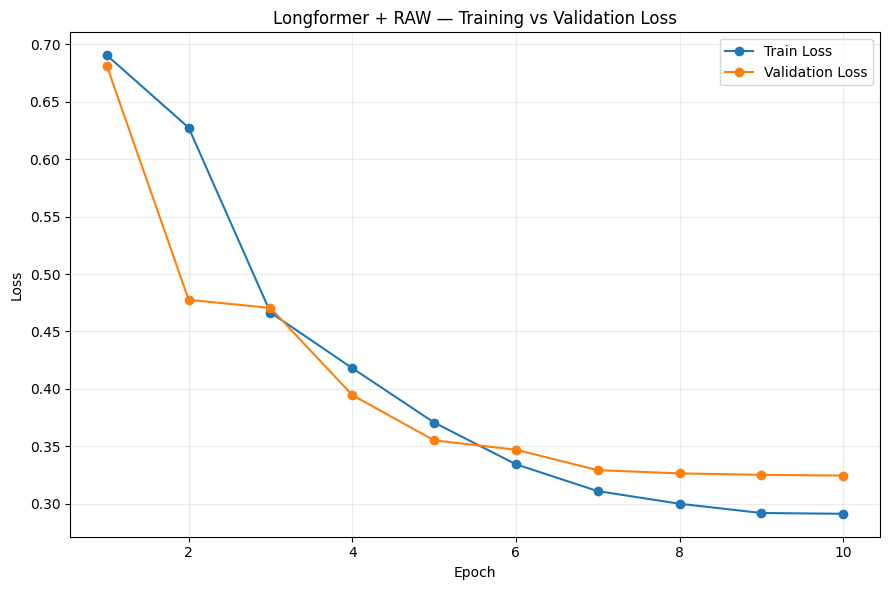

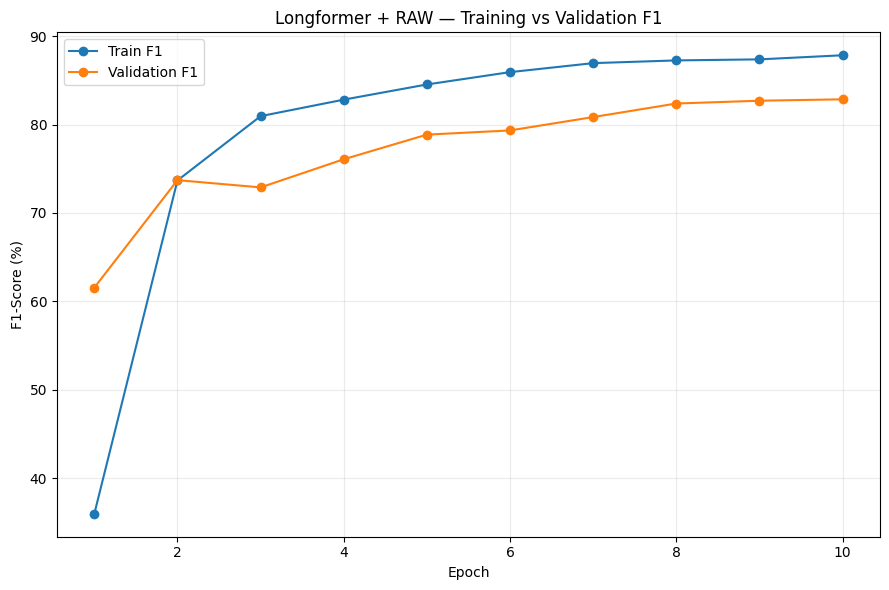

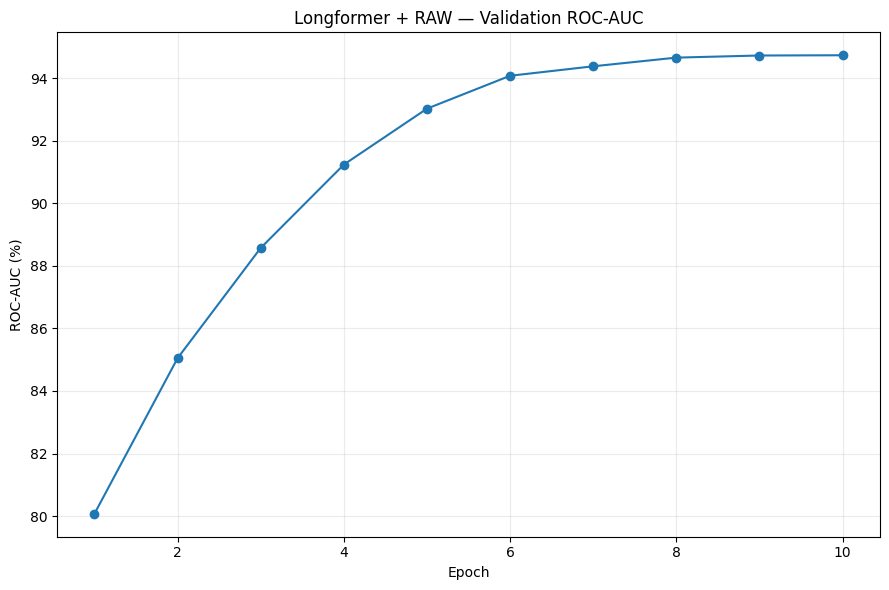

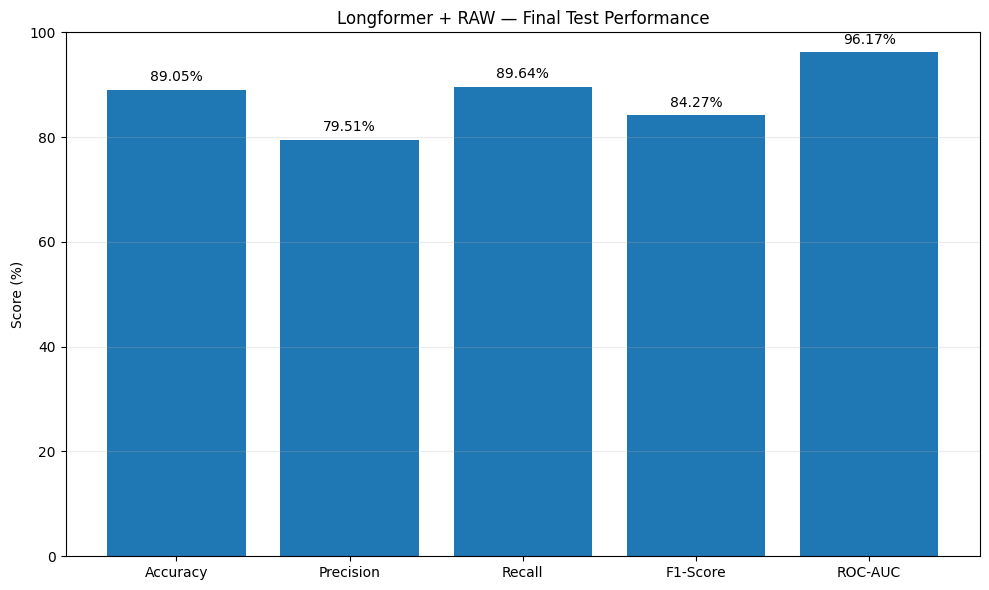

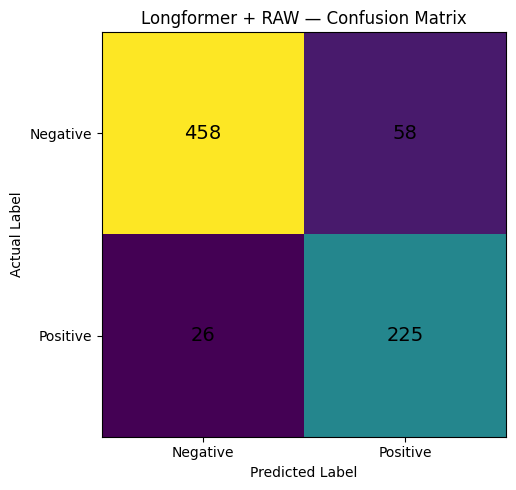

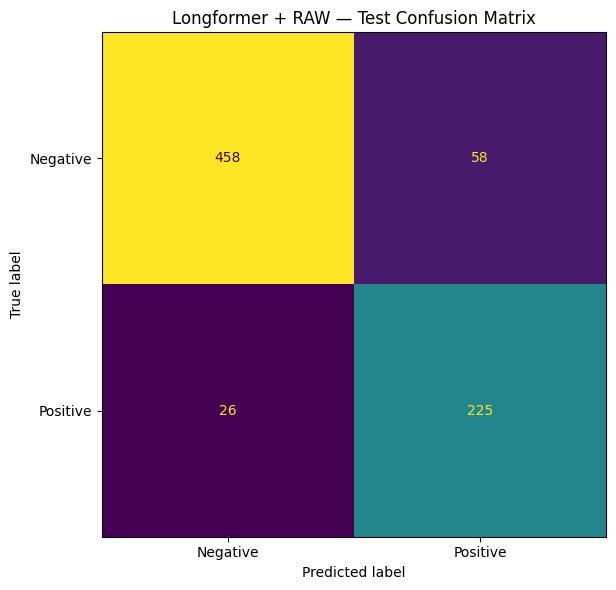

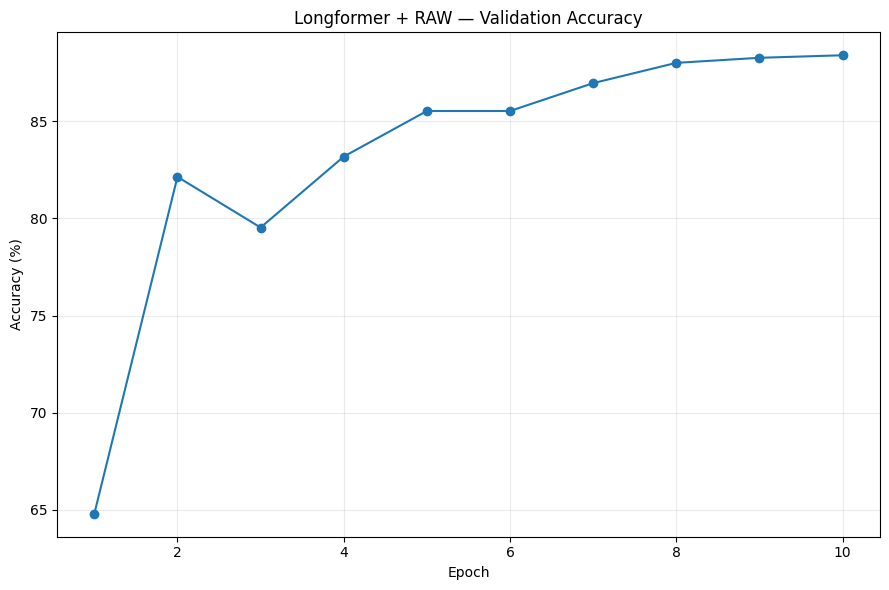


CELL 14 COMPLETE
✓ Final results table saved
✓ Training history table saved
✓ Loss curve saved
✓ F1 curve saved
✓ Validation ROC-AUC graph saved
✓ Validation accuracy graph saved
✓ Final metrics graph saved
✓ Confusion matrix saved

Graphs folder:
/kaggle/working/longformer_raw/graphs

Tables folder:
/kaggle/working/longformer_raw/tables


In [18]:
# ============================================================
# CELL 14 — Longformer + RAW
# GRAPHS + TABLES
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay

print("=" * 60)
print("Longformer + RAW — GRAPHS + TABLES")
print("=" * 60)

# ============================================================
# DIRECTORIES
# ============================================================

BASE_RESULT_DIR = os.path.dirname(
    RESULT_DIR
)

GRAPH_DIR = os.path.join(
    BASE_RESULT_DIR,
    "graphs"
)

TABLE_DIR = os.path.join(
    BASE_RESULT_DIR,
    "tables"
)

os.makedirs(GRAPH_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

# ============================================================
# LOAD SAVED RESULTS
# ============================================================

with open(
    os.path.join(
        RESULT_DIR,
        "longformer_raw_test_results.json"
    ),
    "r"
) as f:

    final_metrics = json.load(f)

history_df = pd.read_csv(
    os.path.join(
        RESULT_DIR,
        "longformer_raw_training_history.csv"
    )
)

# ============================================================
# CONFUSION MATRIX DATA
# ============================================================

cm = np.array([
    [
        final_metrics["true_negative"],
        final_metrics["false_positive"]
    ],
    [
        final_metrics["false_negative"],
        final_metrics["true_positive"]
    ]
]).astype(int)

cm_df = pd.DataFrame(
    cm,
    index=[
        "Negative",
        "Positive"
    ],
    columns=[
        "Negative",
        "Positive"
    ]
)

cm_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "longformer_raw_confusion_matrix.csv"
    )
)

# ============================================================
# FINAL RESULTS TABLE
# ============================================================

results_table = pd.DataFrame({
    "Model": ["Longformer"],
    "Cleaning": ["RAW"],
    "Accuracy": [
        final_metrics["test_accuracy"] * 100
    ],
    "Precision": [
        final_metrics["test_precision"] * 100
    ],
    "Recall": [
        final_metrics["test_recall"] * 100
    ],
    "F1-Score": [
        final_metrics["test_f1"] * 100
    ],
    "ROC-AUC": [
        final_metrics["test_roc_auc"] * 100
    ]
})

results_table = results_table.round(2)

print()
print("=" * 60)
print("FINAL RESULTS TABLE")
print("=" * 60)

print(
    results_table.to_string(
        index=False
    )
)

results_table.to_csv(
    os.path.join(
        TABLE_DIR,
        "longformer_raw_results_table.csv"
    ),
    index=False
)

# ============================================================
# TRAINING HISTORY TABLE
# ============================================================

history_export = history_df.copy()

history_export.to_csv(
    os.path.join(
        TABLE_DIR,
        "longformer_raw_training_history_table.csv"
    ),
    index=False
)

# ============================================================
# GRAPH 1 — TRAINING VS VALIDATION LOSS
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(
    "Longformer + RAW — Training vs Validation Loss"
)
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "longformer_raw_loss_curve.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ============================================================
# GRAPH 2 — TRAINING VS VALIDATION F1
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    history_df["epoch"],
    history_df["train_f1"] * 100,
    marker="o",
    label="Train F1"
)

plt.plot(
    history_df["epoch"],
    history_df["val_f1"] * 100,
    marker="o",
    label="Validation F1"
)

plt.xlabel("Epoch")
plt.ylabel("F1-Score (%)")
plt.title(
    "Longformer + RAW — Training vs Validation F1"
)
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "longformer_raw_f1_curve.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ============================================================
# GRAPH 3 — VALIDATION ROC-AUC
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    history_df["epoch"],
    history_df["val_roc_auc"] * 100,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC (%)")
plt.title(
    "Longformer + RAW — Validation ROC-AUC"
)
plt.grid(True, alpha=0.25)
plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "longformer_raw_validation_roc_auc.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ============================================================
# GRAPH 4 — FINAL METRICS
# ============================================================

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

metric_values = [
    final_metrics["test_accuracy"] * 100,
    final_metrics["test_precision"] * 100,
    final_metrics["test_recall"] * 100,
    final_metrics["test_f1"] * 100,
    final_metrics["test_roc_auc"] * 100
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    metric_names,
    metric_values
)

plt.ylabel("Score (%)")
plt.ylim(0, 100)

plt.title(
    "Longformer + RAW — Final Test Performance"
)

for bar, value in zip(
    bars,
    metric_values
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "longformer_raw_final_metrics.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ============================================================
# GRAPH 5 — CONFUSION MATRIX
# ============================================================

# ============================================================
# 5. CONFUSION MATRIX
# ============================================================

fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(cm)

ax.set_title("Longformer + RAW — Confusion Matrix")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Negative", "Positive"])
ax.set_yticklabels(["Negative", "Positive"])

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j, i, cm[i, j],
            ha="center",
            va="center",
            fontsize=14
        )

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "longformer_raw_confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

fig, ax = plt.subplots(
    figsize=(7, 6)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Negative",
        "Positive"
    ]
)

disp.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Longformer + RAW — Test Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "longformer_raw_confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ============================================================
# GRAPH 6 — VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"] * 100,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title(
    "Longformer + RAW — Validation Accuracy"
)

plt.grid(True, alpha=0.25)
plt.tight_layout()

plt.savefig(
    os.path.join(
        GRAPH_DIR,
        "longformer_raw_validation_accuracy.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ============================================================
# SUMMARY TEXT FILE
# ============================================================

with open(
    os.path.join(
        TABLE_DIR,
        "longformer_raw_summary.txt"
    ),
    "w"
) as f:

    f.write(
        "Longformer + RAW — FINAL TEST RESULTS\n"
    )

    f.write(
        "=====================================\n"
    )

    f.write(
        f"Accuracy : "
        f"{final_metrics['test_accuracy'] * 100:.2f}%\n"
    )

    f.write(
        f"Precision: "
        f"{final_metrics['test_precision'] * 100:.2f}%\n"
    )

    f.write(
        f"Recall   : "
        f"{final_metrics['test_recall'] * 100:.2f}%\n"
    )

    f.write(
        f"F1-Score : "
        f"{final_metrics['test_f1'] * 100:.2f}%\n"
    )

    f.write(
        f"ROC-AUC  : "
        f"{final_metrics['test_roc_auc'] * 100:.2f}%\n"
    )

    f.write(
        "\nConfusion Matrix:\n"
    )

    f.write(
        f"TN={cm[0,0]}, FP={cm[0,1]}\n"
    )

    f.write(
        f"FN={cm[1,0]}, TP={cm[1,1]}\n"
    )

# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 14 COMPLETE")
print("=" * 60)

print(
    "✓ Final results table saved"
)

print(
    "✓ Training history table saved"
)

print(
    "✓ Loss curve saved"
)

print(
    "✓ F1 curve saved"
)

print(
    "✓ Validation ROC-AUC graph saved"
)

print(
    "✓ Validation accuracy graph saved"
)

print(
    "✓ Final metrics graph saved"
)

print(
    "✓ Confusion matrix saved"
)

print()
print("Graphs folder:")
print(GRAPH_DIR)

print()
print("Tables folder:")
print(TABLE_DIR)

In [19]:
# ============================================================
# EXPLAINABILITY OUTPUT DIRECTORY SETUP
# LONGFORMER + RAW
# ============================================================

import os

BASE_RESULT_DIR = os.path.dirname(
    RESULT_DIR
)

EXPLAINABILITY_DIR = os.path.join(
    BASE_RESULT_DIR,
    "explainability"
)

os.makedirs(
    EXPLAINABILITY_DIR,
    exist_ok=True
)

print("=" * 70)
print("EXPLAINABILITY DIRECTORY READY")
print("=" * 70)

print(
    "Output directory:",
    EXPLAINABILITY_DIR
)

EXPLAINABILITY DIRECTORY READY
Output directory: /kaggle/working/longformer_raw/explainability


t-SNE REPRESENTATION ANALYSIS
LONGFORMER + RAW

Extracting fused model representations...
Processed batch 1/48
Processed batch 10/48
Processed batch 20/48
Processed batch 30/48
Processed batch 40/48
Processed batch 48/48

FUSED REPRESENTATION
Representation shape: (767, 832)
Number of test users: 767
Representation dimensions: 832
Negative users: 516
Positive users: 251

PCA REDUCTION
Original dimensions: 832
PCA dimensions: 50
Variance retained: 93.23%

t-SNE REDUCTION
t-SNE output shape: (767, 2)


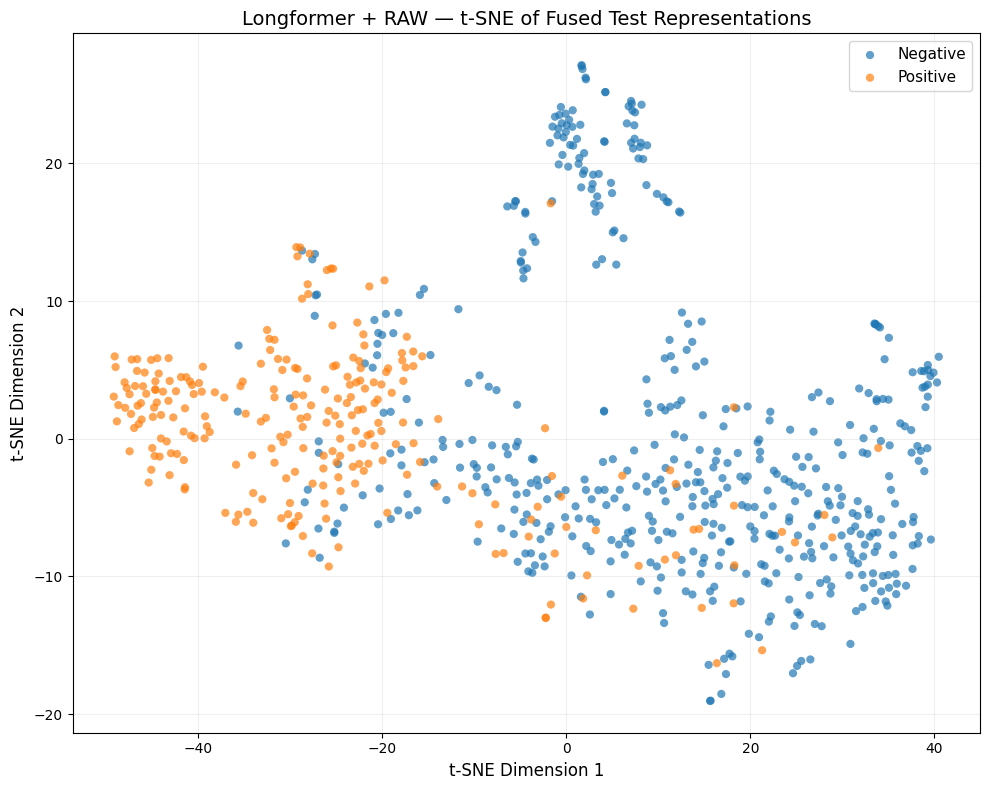


t-SNE ANALYSIS COMPLETE
✓ Fused representation extracted
✓ PCA reduction completed
✓ t-SNE reduction completed
✓ Coordinates saved:
/kaggle/working/longformer_raw/explainability/tsne/longformer_raw_tsne_coordinates.csv
✓ Graph saved:
/kaggle/working/longformer_raw/explainability/tsne/longformer_raw_tsne.png
✓ Graph displayed above
✓ Configuration saved


In [20]:
# ============================================================
# EXPLAINABILITY — CELL 1
# LONGFORMER + RAW
# t-SNE: FUSED REPRESENTATION → PCA → t-SNE
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

print("=" * 70)
print("t-SNE REPRESENTATION ANALYSIS")
print("LONGFORMER + RAW")
print("=" * 70)

# ============================================================
# FIXED EXPLAINABILITY SETTINGS
# ============================================================

EXPLAINABILITY_SEED = 42
PCA_COMPONENTS = 50
TSNE_COMPONENTS = 2
TSNE_PERPLEXITY = 30
TSNE_LEARNING_RATE = 200
TSNE_MAX_ITER = 1000

np.random.seed(EXPLAINABILITY_SEED)
torch.manual_seed(EXPLAINABILITY_SEED)

# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    BASE_RESULT_DIR,
    "explainability"
)

TSNE_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "tsne"
)

os.makedirs(
    TSNE_DIR,
    exist_ok=True
)

# ============================================================
# MODEL
# ============================================================

model_longformer_raw.eval()

# ============================================================
# EXTRACT FUSED REPRESENTATIONS
# ============================================================

fused_representations = []
test_labels = []

print()
print("Extracting fused model representations...")

with torch.no_grad():

    for batch_idx, batch in enumerate(
        test_longformer_raw_loader,
        start=1
    ):

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)

        output = model_longformer_raw(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        # ----------------------------------------------------
        # ACTUAL OUTPUT NAMES FROM LONGFORMER MODEL
        # ----------------------------------------------------

        text_representation = output[
            "text_representation"
        ]

        metadata_representation = output[
            "metadata_representation"
        ]

        # ----------------------------------------------------
        # SAME LEARNED METADATA GATE
        # ----------------------------------------------------

        metadata_gate = torch.sigmoid(
            model_longformer_raw.metadata_beta
        )

        gated_metadata = (
            metadata_gate *
            metadata_representation
        )

        # ----------------------------------------------------
        # EXACT FUSED REPRESENTATION
        # ----------------------------------------------------

        fused = torch.cat(
            [
                text_representation,
                gated_metadata
            ],
            dim=1
        )

        fused_representations.append(
            fused.cpu().numpy()
        )

        test_labels.extend(
            labels.cpu().numpy().tolist()
        )

        if (
            batch_idx == 1
            or batch_idx % 10 == 0
            or batch_idx ==
            len(test_longformer_raw_loader)
        ):

            print(
                f"Processed batch "
                f"{batch_idx}/"
                f"{len(test_longformer_raw_loader)}"
            )

# ============================================================
# COMBINE
# ============================================================

fused_representations = np.concatenate(
    fused_representations,
    axis=0
)

test_labels = np.array(
    test_labels
)

# ============================================================
# INTEGRITY
# ============================================================

print()
print("=" * 70)
print("FUSED REPRESENTATION")
print("=" * 70)

print(
    "Representation shape:",
    fused_representations.shape
)

print(
    "Number of test users:",
    len(test_labels)
)

print(
    "Representation dimensions:",
    fused_representations.shape[1]
)

print(
    "Negative users:",
    int((test_labels == 0).sum())
)

print(
    "Positive users:",
    int((test_labels == 1).sum())
)

assert (
    fused_representations.shape[0]
    ==
    len(test_labels)
)

assert np.isfinite(
    fused_representations
).all()

# ============================================================
# PCA
# ============================================================

print()
print("=" * 70)
print("PCA REDUCTION")
print("=" * 70)

pca_dimensions = min(
    PCA_COMPONENTS,
    fused_representations.shape[1]
)

pca = PCA(
    n_components=pca_dimensions,
    random_state=EXPLAINABILITY_SEED
)

pca_representation = pca.fit_transform(
    fused_representations
)

explained_variance = (
    pca.explained_variance_ratio_.sum()
)

print(
    "Original dimensions:",
    fused_representations.shape[1]
)

print(
    "PCA dimensions:",
    pca_representation.shape[1]
)

print(
    "Variance retained:",
    f"{explained_variance * 100:.2f}%"
)

# ============================================================
# t-SNE
# ============================================================

print()
print("=" * 70)
print("t-SNE REDUCTION")
print("=" * 70)

tsne = TSNE(
    n_components=TSNE_COMPONENTS,
    perplexity=TSNE_PERPLEXITY,
    learning_rate=TSNE_LEARNING_RATE,
    init="pca",
    random_state=EXPLAINABILITY_SEED,
    max_iter=TSNE_MAX_ITER
)

tsne_representation = tsne.fit_transform(
    pca_representation
)

print(
    "t-SNE output shape:",
    tsne_representation.shape
)

# ============================================================
# SAVE COORDINATES
# ============================================================

tsne_df = pd.DataFrame({

    "tsne_1":
        tsne_representation[:, 0],

    "tsne_2":
        tsne_representation[:, 1],

    "label":
        test_labels

})

tsne_df["class"] = tsne_df[
    "label"
].map({
    0: "Negative",
    1: "Positive"
})

tsne_csv_path = os.path.join(
    TSNE_DIR,
    "longformer_raw_tsne_coordinates.csv"
)

tsne_df.to_csv(
    tsne_csv_path,
    index=False
)

# ============================================================
# PUBLICATION-QUALITY PLOT
# ============================================================

plt.figure(
    figsize=(10, 8)
)

negative_mask = (
    test_labels == 0
)

positive_mask = (
    test_labels == 1
)

plt.scatter(
    tsne_representation[
        negative_mask,
        0
    ],
    tsne_representation[
        negative_mask,
        1
    ],
    s=35,
    alpha=0.70,
    label="Negative",
    edgecolors="none"
)

plt.scatter(
    tsne_representation[
        positive_mask,
        0
    ],
    tsne_representation[
        positive_mask,
        1
    ],
    s=35,
    alpha=0.70,
    label="Positive",
    edgecolors="none"
)

plt.xlabel(
    "t-SNE Dimension 1",
    fontsize=12
)

plt.ylabel(
    "t-SNE Dimension 2",
    fontsize=12
)

plt.title(
    "Longformer + RAW — "
    "t-SNE of Fused Test Representations",
    fontsize=14
)

plt.legend(
    fontsize=11
)

plt.grid(
    alpha=0.20
)

plt.tight_layout()

tsne_plot_path = os.path.join(
    TSNE_DIR,
    "longformer_raw_tsne.png"
)

# SAVE
plt.savefig(
    tsne_plot_path,
    dpi=300,
    bbox_inches="tight"
)

# DISPLAY
plt.show()

plt.close()

# ============================================================
# SAVE CONFIGURATION
# ============================================================

tsne_config = {

    "model":
        "Longformer",

    "cleaning":
        "RAW",

    "dataset":
        "Held-out test set",

    "test_users":
        int(len(test_labels)),

    "input_representation":
        "Fused classifier representation",

    "text_representation_dimension":
        int(
            text_representation.shape[1]
        ),

    "metadata_representation_dimension":
        int(
            metadata_representation.shape[1]
        ),

    "fused_representation_dimension":
        int(
            fused_representations.shape[1]
        ),

    "pca_dimensions":
        int(pca_dimensions),

    "pca_variance_retained":
        float(explained_variance),

    "tsne_dimensions":
        int(TSNE_COMPONENTS),

    "tsne_perplexity":
        int(TSNE_PERPLEXITY),

    "tsne_learning_rate":
        TSNE_LEARNING_RATE,

    "tsne_max_iterations":
        int(TSNE_MAX_ITER),

    "random_seed":
        EXPLAINABILITY_SEED

}

with open(
    os.path.join(
        TSNE_DIR,
        "longformer_raw_tsne_config.json"
    ),
    "w"
) as f:

    json.dump(
        tsne_config,
        f,
        indent=2
    )

# ============================================================
# FINAL OUTPUT
# ============================================================

print()
print("=" * 70)
print("t-SNE ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ Fused representation extracted"
)

print(
    "✓ PCA reduction completed"
)

print(
    "✓ t-SNE reduction completed"
)

print(
    "✓ Coordinates saved:"
)

print(
    tsne_csv_path
)

print(
    "✓ Graph saved:"
)

print(
    tsne_plot_path
)

print(
    "✓ Graph displayed above"
)

print(
    "✓ Configuration saved"
)

In [21]:
# ============================================================
# GRAD-CAM — TOKENIZER SETUP
# LONGFORMER + RAW
# ============================================================

# The notebook keeps the tokenizer as longformer_raw_tokenizer.
# Grad-CAM expects the generic name tokenizer.

try:
    tokenizer = longformer_raw_tokenizer

    print("✓ Existing Longformer tokenizer reused")

except NameError:

    from transformers import AutoTokenizer

    tokenizer = AutoTokenizer.from_pretrained(
        MODEL_NAME,
        token=hf_token
    )

    print("✓ Longformer tokenizer loaded")

print(
    "Tokenizer:",
    tokenizer.__class__.__name__
)


✓ Existing Longformer tokenizer reused
Tokenizer: RobertaTokenizer


GRAD-CAM ANALYSIS
LONGFORMER + RAW

✓ Longformer model loaded
✓ Evaluation mode enabled
✓ All model parameters remain frozen

GENERATING TEST PREDICTIONS FOR CASE SELECTION

Test users: 767
✓ Test predictions generated

FIXED REPRESENTATIVE TEST CASES
TN: test index = 0
TP: test index = 1
FP: test index = 7
FN: test index = 35

GENERATING GRAD-CAM EXPLANATIONS

Processing TN (test index 0)...
✓ TN Grad-CAM complete

Processing TP (test index 1)...
✓ TP Grad-CAM complete

Processing FP (test index 7)...
✓ FP Grad-CAM complete

Processing FN (test index 35)...
✓ FN Grad-CAM complete

GRAD-CAM TOKEN IMPORTANCE


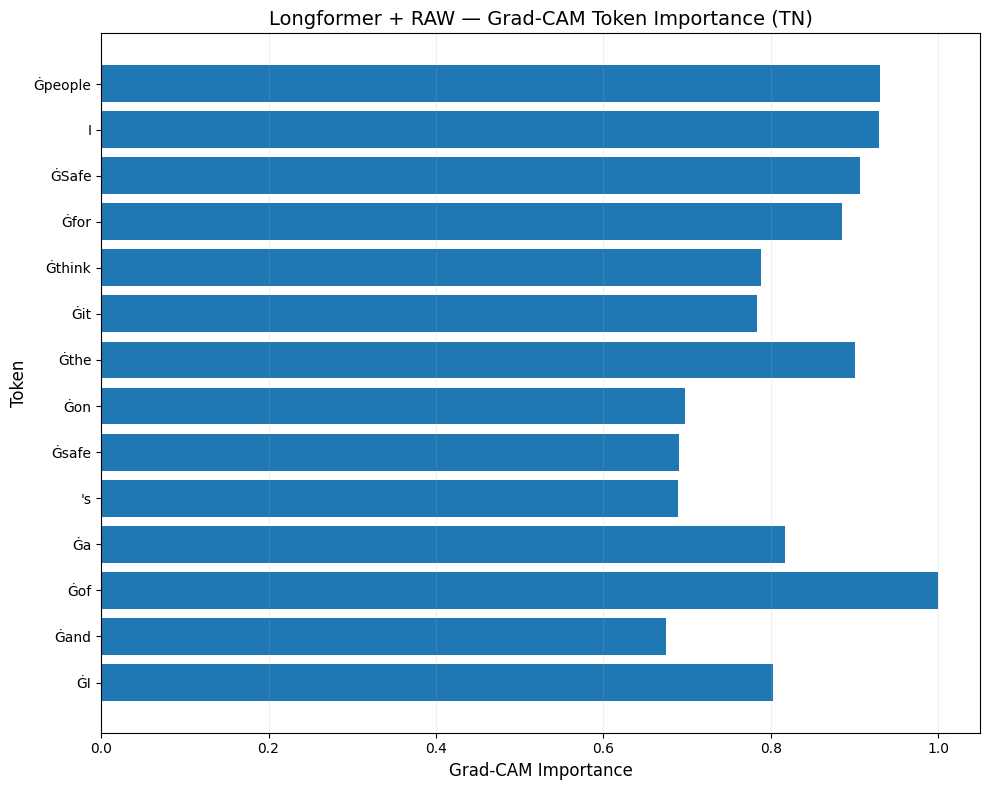

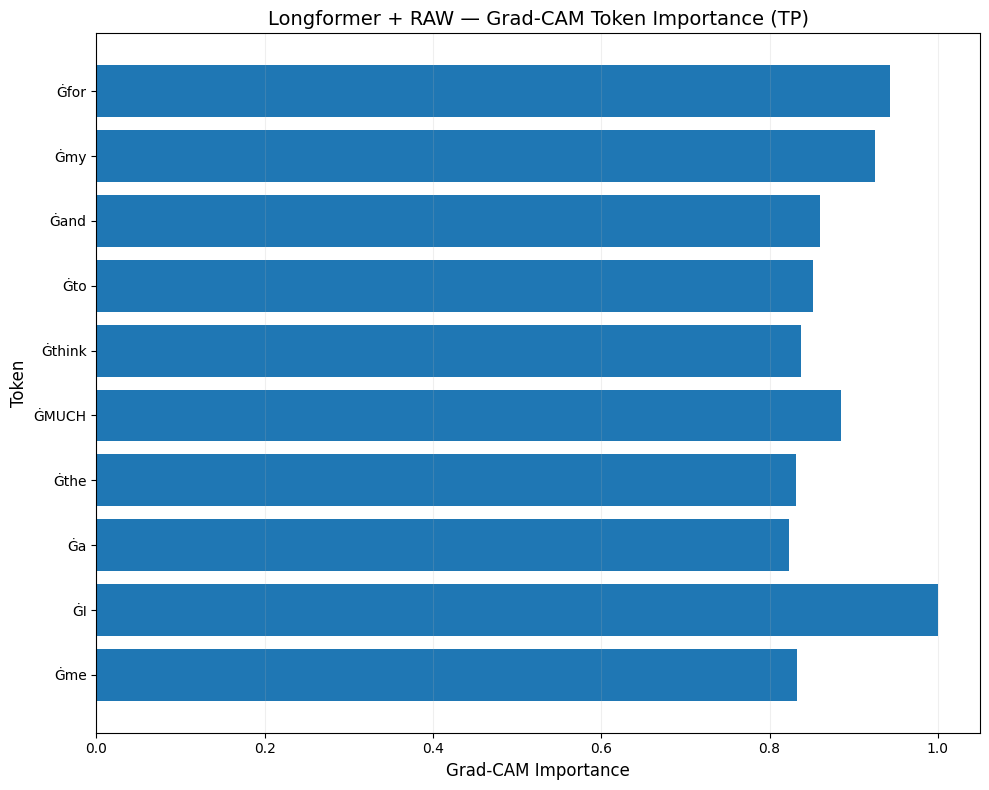

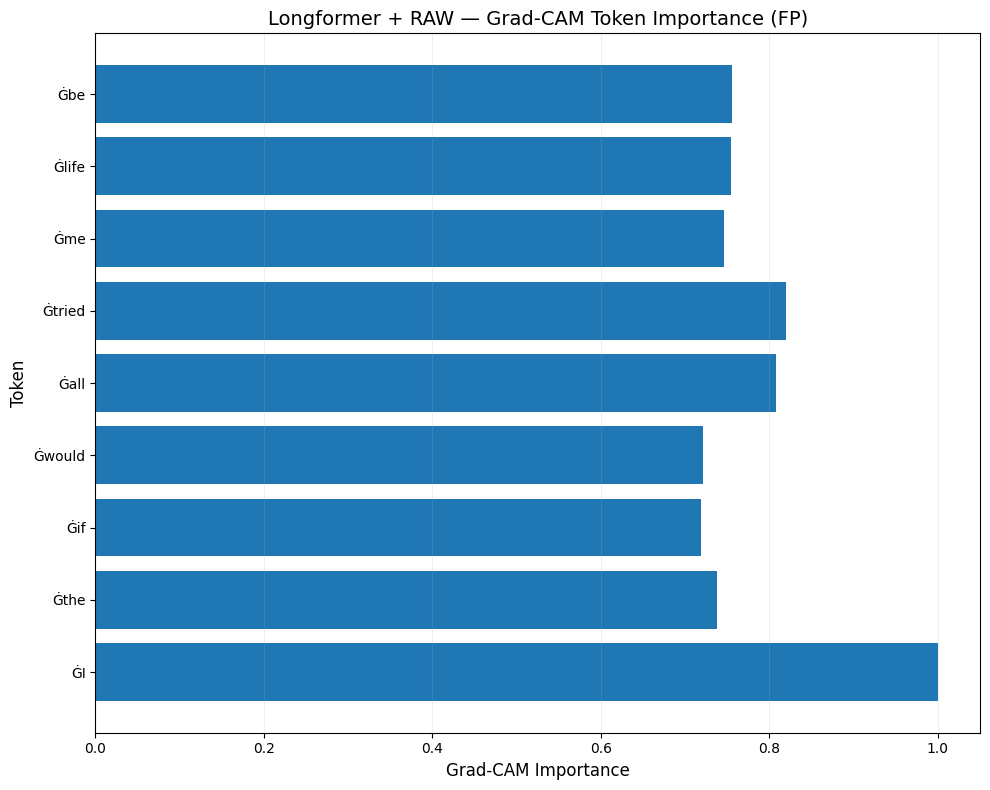

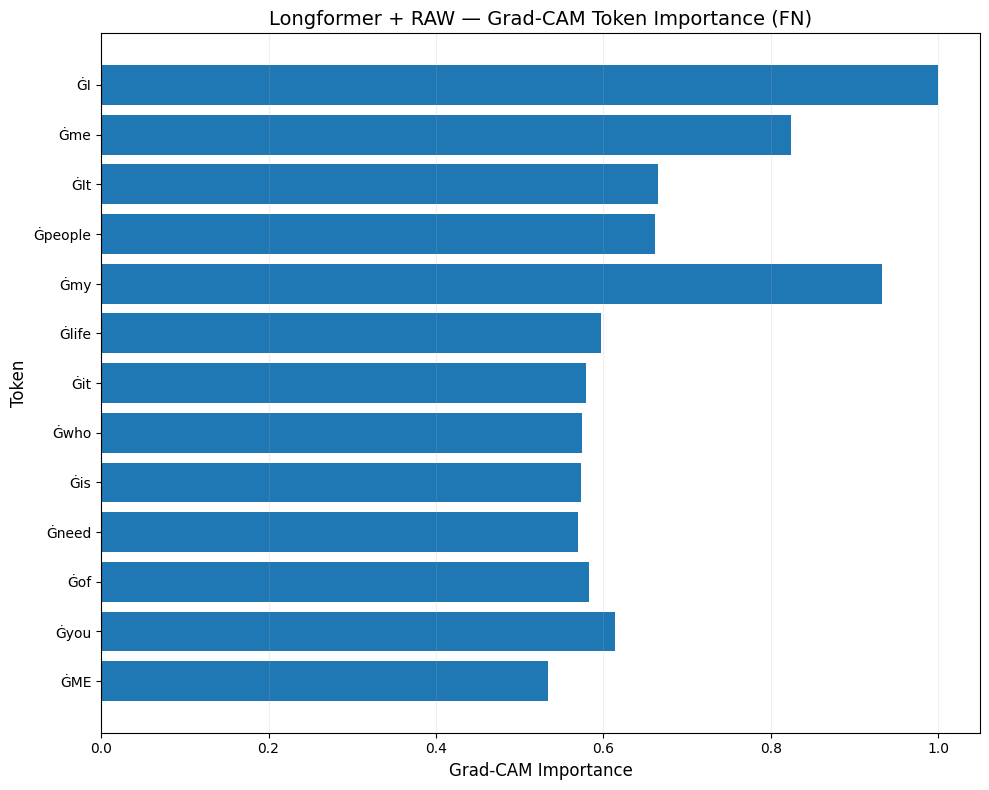


GRAD-CAM ANALYSIS COMPLETE
✓ Same TP/TN/FP/FN selection logic
✓ Final Transformer hidden states used
✓ Positive-class gradients computed
✓ Longformer weights remained frozen
✓ No additional model training
✓ Token importance calculated
✓ Top-20 token plots saved and displayed
✓ Token importance CSV saved
✓ Configuration saved

Grad-CAM output directory: /kaggle/working/longformer_raw/explainability/gradcam


In [22]:
# ============================================================
# EXPLAINABILITY — GRAD-CAM
# LONGFORMER + RAW
# TOKEN-LEVEL LOCAL EXPLANATION
# ============================================================

import os
import json
import gc
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from IPython.display import display, HTML

print("=" * 70)
print("GRAD-CAM ANALYSIS")
print("LONGFORMER + RAW")
print("=" * 70)

# ============================================================
# FIXED GRAD-CAM SETTINGS
# ============================================================

GRADCAM_SEED = 42
GRADCAM_TOP_TOKENS = 20

np.random.seed(GRADCAM_SEED)
torch.manual_seed(GRADCAM_SEED)

# ============================================================
# OUTPUT DIRECTORY
# ============================================================

GRADCAM_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "gradcam"
)

os.makedirs(
    GRADCAM_DIR,
    exist_ok=True
)

# ============================================================
# MODEL
# ============================================================

model_longformer_raw.eval()

# Keep all model parameters frozen
for parameter in model_longformer_raw.parameters():
    parameter.requires_grad = False

print()
print("✓ Longformer model loaded")
print("✓ Evaluation mode enabled")
print("✓ All model parameters remain frozen")

# ============================================================
# GET TEST PREDICTIONS
# ============================================================
# The source cell expects:
# labels_np, preds_np, probs_np
# and selected_cases to already exist.
#
# In this Longformer notebook these arrays are reproduced
# directly from the already-trained model and
# test_longformer_raw_loader.

labels_np = []
preds_np = []
probs_np = []

print()
print("=" * 70)
print("GENERATING TEST PREDICTIONS FOR CASE SELECTION")
print("=" * 70)

with torch.no_grad():

    for batch in test_longformer_raw_loader:

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)

        output = model_longformer_raw(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = output[
            "logits"
        ]

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predictions = torch.argmax(
            logits,
            dim=1
        )

        labels_np.extend(
            labels.cpu().numpy().tolist()
        )

        preds_np.extend(
            predictions.cpu().numpy().tolist()
        )

        probs_np.extend(
            probabilities[:, 1]
            .cpu()
            .numpy()
            .tolist()
        )

labels_np = np.asarray(
    labels_np,
    dtype=np.int64
)

preds_np = np.asarray(
    preds_np,
    dtype=np.int64
)

probs_np = np.asarray(
    probs_np,
    dtype=np.float32
)

assert len(labels_np) == len(
    test_longformer_raw_dataset
)

assert len(preds_np) == len(
    test_longformer_raw_dataset
)

assert len(probs_np) == len(
    test_longformer_raw_dataset
)

print()
print(
    "Test users:",
    len(labels_np)
)

print(
    "✓ Test predictions generated"
)

# ============================================================
# FIXED REPRESENTATIVE TEST CASES
# ============================================================
# First matching test example in fixed test order:
# TP = true 1, predicted 1
# TN = true 0, predicted 0
# FP = true 0, predicted 1
# FN = true 1, predicted 0
# ============================================================

selected_cases = {}

for test_index in range(
    len(labels_np)
):

    true_label = int(
        labels_np[test_index]
    )

    predicted_label = int(
        preds_np[test_index]
    )

    if (
        "TP" not in selected_cases
        and true_label == 1
        and predicted_label == 1
    ):

        selected_cases["TP"] = test_index

    elif (
        "TN" not in selected_cases
        and true_label == 0
        and predicted_label == 0
    ):

        selected_cases["TN"] = test_index

    elif (
        "FP" not in selected_cases
        and true_label == 0
        and predicted_label == 1
    ):

        selected_cases["FP"] = test_index

    elif (
        "FN" not in selected_cases
        and true_label == 1
        and predicted_label == 0
    ):

        selected_cases["FN"] = test_index

    if len(
        selected_cases
    ) == 4:

        break

assert set(
    selected_cases.keys()
) == {
    "TP",
    "TN",
    "FP",
    "FN"
}

print()
print("=" * 70)
print("FIXED REPRESENTATIVE TEST CASES")
print("=" * 70)

for case_name, test_index in selected_cases.items():

    print(
        f"{case_name}: "
        f"test index = {test_index}"
    )

# ============================================================
# GRAD-CAM FUNCTION
# ============================================================

def compute_longformer_gradcam(
    test_index
):

    sample = test_longformer_raw_dataset[
        int(test_index)
    ]

    input_ids = (
        sample["input_ids"]
        .unsqueeze(0)
        .to(device)
    )

    attention_mask = (
        sample["attention_mask"]
        .unsqueeze(0)
        .to(device)
    )

    metadata = (
        sample["metadata"]
        .unsqueeze(0)
        .to(device)
    )

    # --------------------------------------------------------
    # Encoder forward pass
    # --------------------------------------------------------

    with torch.enable_grad():

        # Longformer backbone is frozen.
        # Only its output activation is made differentiable
        # for Grad-CAM.

        with torch.no_grad():

            encoder_output = (
                model_longformer_raw.longformer(
                    input_ids=input_ids,
                    attention_mask=attention_mask
                )
            )

        hidden_states = (
            encoder_output.last_hidden_state
        )

        hidden_states = (
            hidden_states
            .detach()
        )

        hidden_states.requires_grad_(True)

        hidden_states.retain_grad()

        # ----------------------------------------------------
        # EXACT ATTENTION POOLING FROM LONGFORMER MODEL
        # ----------------------------------------------------

        projected = (
            model_longformer_raw.attention_projection(
                hidden_states
            )
        )

        scores = (
            model_longformer_raw.attention_score(
                torch.tanh(
                    projected
                )
            )
            .squeeze(-1)
        )

        scores = scores.masked_fill(
            attention_mask == 0,
            torch.finfo(
                scores.dtype
            ).min
        )

        attention_weights = (
            torch.softmax(
                scores,
                dim=1
            )
        )

        text_representation = torch.sum(
            hidden_states *
            attention_weights.unsqueeze(-1),
            dim=1
        )

        # ----------------------------------------------------
        # EXACT METADATA BRANCH FROM LONGFORMER MODEL
        # ----------------------------------------------------

        metadata_representation = (
            model_longformer_raw.metadata_branch(
                metadata
            )
        )

        metadata_gate = torch.sigmoid(
            model_longformer_raw.metadata_beta
        )

        gated_metadata = (
            metadata_gate *
            metadata_representation
        )

        # ----------------------------------------------------
        # EXACT FUSION + CLASSIFIER
        # ----------------------------------------------------

        fused = torch.cat(
            [
                text_representation,
                gated_metadata
            ],
            dim=1
        )

        logits = (
            model_longformer_raw.classifier(
                fused
            )
        )

        # Positive/depression class
        target_score = logits[
            0,
            1
        ]

        # ----------------------------------------------------
        # BACKWARD
        # ----------------------------------------------------

        model_longformer_raw.zero_grad(
            set_to_none=True
        )

        target_score.backward()

        gradients = (
            hidden_states.grad
            .detach()
            .clone()
        )

        activations = (
            hidden_states.detach()
            .clone()
        )

    # ========================================================
    # GRAD-CAM WEIGHTS
    # ========================================================

    channel_weights = gradients.mean(
        dim=1
    )

    cam = torch.sum(
        activations *
        channel_weights.unsqueeze(1),
        dim=-1
    )

    cam = torch.relu(
        cam
    )

    cam = cam.squeeze(
        0
    ).cpu().numpy()

    attention_weights_np = (
        attention_weights
        .detach()
        .squeeze(0)
        .cpu()
        .numpy()
    )

    input_ids_np = (
        input_ids
        .detach()
        .squeeze(0)
        .cpu()
        .numpy()
    )

    # --------------------------------------------------------
    # Normalize Grad-CAM
    # --------------------------------------------------------

    valid_mask = (
        attention_mask
        .detach()
        .squeeze(0)
        .cpu()
        .numpy()
        .astype(bool)
    )

    valid_cam = cam[
        valid_mask
    ]

    if (
        valid_cam.max()
        -
        valid_cam.min()
    ) > 1e-12:

        cam_normalized = (
            cam
            -
            valid_cam.min()
        ) / (
            valid_cam.max()
            -
            valid_cam.min()
        )

    else:

        cam_normalized = (
            np.zeros_like(cam)
        )

    cam_normalized[
        ~valid_mask
    ] = 0.0

    return {
        "cam":
            cam_normalized,

        "attention_weights":
            attention_weights_np,

        "input_ids":
            input_ids_np,

        "attention_mask":
            valid_mask,

        "positive_logit":
            float(
                target_score
                .detach()
                .cpu()
                .item()
            ),

        "logits":
            logits
            .detach()
            .cpu()
            .numpy()
            .squeeze(0)
    }


# ============================================================
# TOKEN PROCESSING
# ============================================================

def get_token_information(
    result
):

    token_ids = (
        result["input_ids"]
    )

    cam = (
        result["cam"]
    )

    attention_mask = (
        result["attention_mask"]
    )

    tokens = tokenizer.convert_ids_to_tokens(
        token_ids.tolist()
    )

    rows = []

    for position, (
        token,
        importance,
        valid
    ) in enumerate(
        zip(
            tokens,
            cam,
            attention_mask
        )
    ):

        if not valid:
            continue

        if token in tokenizer.all_special_tokens:
            continue

        rows.append({

            "position":
                position,

            "token":
                token,

            "importance":
                float(
                    importance
                )

        })

    token_df = pd.DataFrame(
        rows
    )

    token_df = token_df.sort_values(
        "importance",
        ascending=False
    ).reset_index(
        drop=True
    )

    token_df["rank"] = (
        np.arange(
            len(token_df)
        ) + 1
    )

    return token_df


# ============================================================
# RUN GRAD-CAM FOR TP/TN/FP/FN
# ============================================================

gradcam_results = {}

print()
print("=" * 70)
print("GENERATING GRAD-CAM EXPLANATIONS")
print("=" * 70)

for case_name, test_index in selected_cases.items():

    print()
    print(
        f"Processing {case_name} "
        f"(test index {test_index})..."
    )

    result = compute_longformer_gradcam(
        test_index
    )

    token_df = get_token_information(
        result
    )

    gradcam_results[
        case_name
    ] = {

        "test_index":
            test_index,

        "result":
            result,

        "token_df":
            token_df

    }

    print(
        f"✓ {case_name} Grad-CAM complete"
    )

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()

# ============================================================
# SAVE TOKEN IMPORTANCE
# ============================================================

all_gradcam_rows = []

for case_name, data in gradcam_results.items():

    token_df = data[
        "token_df"
    ]

    for _, row in token_df.iterrows():

        all_gradcam_rows.append({

            "case":
                case_name,

            "test_index":
                data["test_index"],

            "true_label":
                int(
                    labels_np[
                        data["test_index"]
                    ]
                ),

            "predicted_label":
                int(
                    preds_np[
                        data["test_index"]
                    ]
                ),

            "positive_probability":
                float(
                    probs_np[
                        data["test_index"]
                    ]
                ),

            "position":
                int(
                    row["position"]
                ),

            "token":
                row["token"],

            "gradcam_importance":
                row["importance"],

            "rank":
                int(
                    row["rank"]
                )

        })

gradcam_results_df = pd.DataFrame(
    all_gradcam_rows
)

gradcam_csv_path = os.path.join(
    GRADCAM_DIR,
    "longformer_raw_gradcam_token_importance.csv"
)

gradcam_results_df.to_csv(
    gradcam_csv_path,
    index=False
)

# ============================================================
# PAPER-READY TOP TOKEN PLOTS
# ============================================================

print()
print("=" * 70)
print("GRAD-CAM TOKEN IMPORTANCE")
print("=" * 70)

for case_name, data in gradcam_results.items():

    token_df = data[
        "token_df"
    ].head(
        GRADCAM_TOP_TOKENS
    ).copy()

    token_df = token_df.iloc[::-1]

    plt.figure(
        figsize=(10, 8)
    )

    plt.barh(
        token_df["token"],
        token_df["importance"]
    )

    plt.xlabel(
        "Grad-CAM Importance",
        fontsize=12
    )

    plt.ylabel(
        "Token",
        fontsize=12
    )

    plt.title(
        f"Longformer + RAW — "
        f"Grad-CAM Token Importance ({case_name})",
        fontsize=14
    )

    plt.grid(
        axis="x",
        alpha=0.20
    )

    plt.tight_layout()

    plot_path = os.path.join(
        GRADCAM_DIR,
        f"longformer_raw_gradcam_{case_name}.png"
    )

    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

# ============================================================
# SAVE TOP TOKEN TABLE
# ============================================================

top_token_rows = []

for case_name, data in gradcam_results.items():

    top_tokens = data[
        "token_df"
    ].head(
        GRADCAM_TOP_TOKENS
    )

    for _, row in top_tokens.iterrows():

        top_token_rows.append({

            "case":
                case_name,

            "rank":
                int(
                    row["rank"]
                ),

            "token":
                row["token"],

            "gradcam_importance":
                float(
                    row["importance"]
                )

        })

top_token_df = pd.DataFrame(
    top_token_rows
)

top_token_df.to_csv(
    os.path.join(
        GRADCAM_DIR,
        "longformer_raw_gradcam_top_tokens.csv"
    ),
    index=False
)

# ============================================================
# SAVE CONFIGURATION
# ============================================================

gradcam_config = {

    "model":
        "Longformer",

    "cleaning":
        "RAW",

    "dataset":
        "Held-out test set",

    "target":
        "Positive/depression class logit",

    "layer":
        "Final Transformer hidden states",

    "hidden_dimension":
        768,

    "method":
        "Transformer Grad-CAM",

    "cases":
        [
            "TP",
            "TN",
            "FP",
            "FN"
        ],

    "top_tokens_displayed":
        GRADCAM_TOP_TOKENS,

    "random_seed":
        GRADCAM_SEED,

    "model_training":
        "No additional training",

    "transformer_weights":
        "Frozen"

}

with open(
    os.path.join(
        GRADCAM_DIR,
        "longformer_raw_gradcam_config.json"
    ),
    "w"
) as f:

    json.dump(
        gradcam_config,
        f,
        indent=2
    )

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("GRAD-CAM ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ Same TP/TN/FP/FN selection logic"
)

print(
    "✓ Final Transformer hidden states used"
)

print(
    "✓ Positive-class gradients computed"
)

print(
    "✓ Longformer weights remained frozen"
)

print(
    "✓ No additional model training"
)

print(
    "✓ Token importance calculated"
)

print(
    "✓ Top-20 token plots saved and displayed"
)

print(
    "✓ Token importance CSV saved"
)

print(
    "✓ Configuration saved"
)

print()
print(
    "Grad-CAM output directory:",
    GRADCAM_DIR
)

SHAP ANALYSIS
LONGFORMER + RAW

Total metadata features: 53

SHAP background samples: 50
Background dimensions: 53

SHAP test samples: 100
Negative: 50
Positive: 50

✓ Longformer model set to evaluation mode
✓ No parameters will be updated

COMPUTING SHAP VALUES
Explained 1/100 test users
Explained 10/100 test users
Explained 20/100 test users
Explained 30/100 test users
Explained 40/100 test users
Explained 50/100 test users
Explained 60/100 test users
Explained 70/100 test users
Explained 80/100 test users
Explained 90/100 test users
Explained 100/100 test users

SHAP RESULT SUMMARY
SHAP matrix: (100, 53)
Metadata matrix: (100, 53)

TOP 20 SHAP FEATURES
                 feature  mean_abs_shap  mean_signed_shap
             lda_topic_2       0.035072          0.005365
              word_count       0.034434          0.000973
             tweet_count       0.023089          0.000570
              engagement       0.018081         -0.009008
          total_retweets       0.016680       

/tmp/ipykernel_58/2149935808.py:677: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


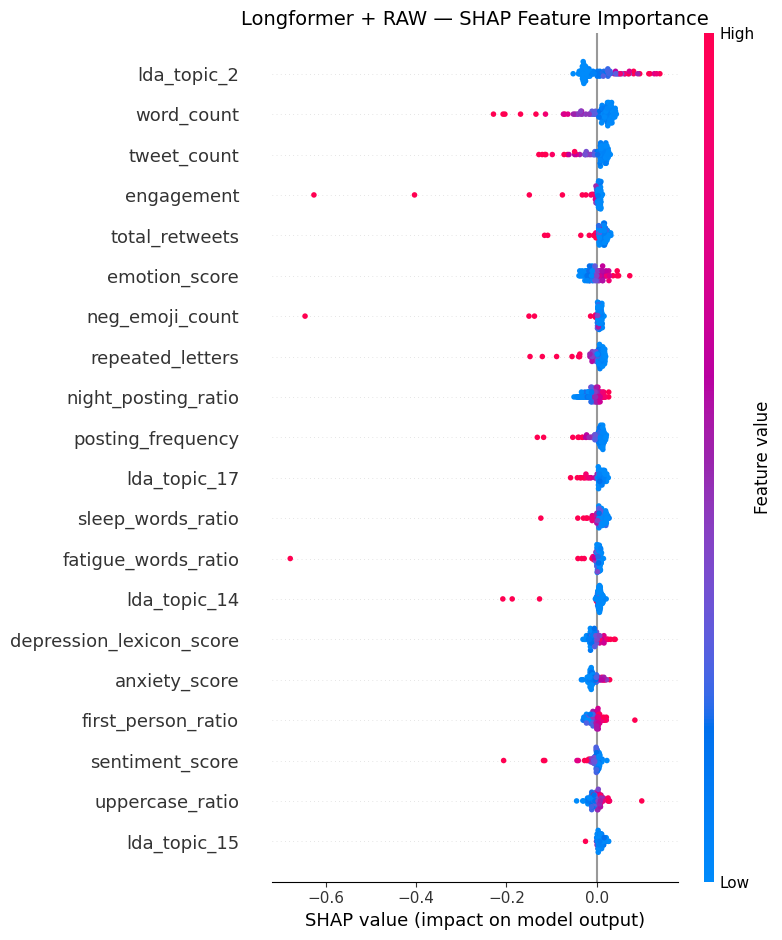

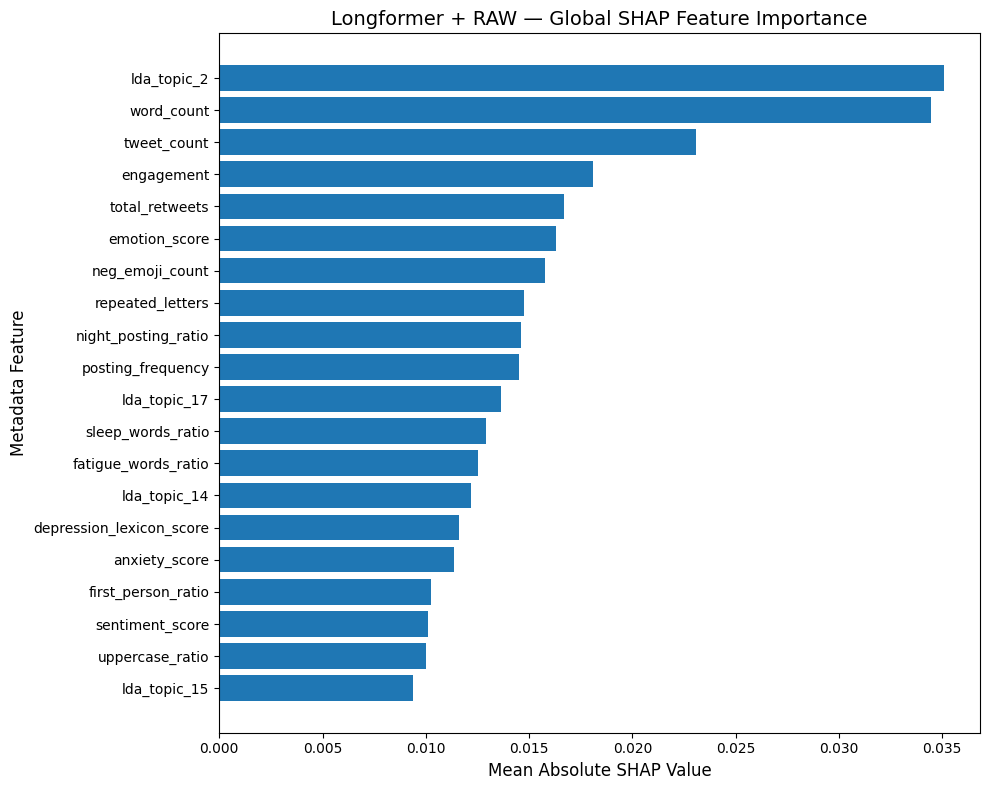


SHAP ANALYSIS COMPLETE
✓ 53 metadata features explained
✓ 100 fixed test users explained
✓ 50 negative + 50 positive
✓ Training-only background used
✓ Positive-class logit explained
✓ Longformer weights unchanged
✓ Longformer text representation fixed per user
✓ SHAP beeswarm saved and displayed
✓ SHAP bar plot saved and displayed
✓ SHAP values saved
✓ Feature importance ranking saved
✓ Configuration saved

SHAP output directory: /kaggle/working/longformer_raw/explainability/shap


In [23]:
# ============================================================
# EXPLAINABILITY — SHAP
# LONGFORMER + RAW
# GLOBAL METADATA FEATURE EXPLANATION
# ============================================================

import os
import json
import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import shap

print("=" * 70)
print("SHAP ANALYSIS")
print("LONGFORMER + RAW")
print("=" * 70)

# ============================================================
# FIXED SHAP SETTINGS
# ============================================================

SHAP_SEED = 42
SHAP_BACKGROUND_SIZE = 50
SHAP_TEST_SIZE_PER_CLASS = 50
SHAP_TOP_FEATURES = 20

np.random.seed(SHAP_SEED)
torch.manual_seed(SHAP_SEED)

# ============================================================
# OUTPUT DIRECTORY
# ============================================================

SHAP_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "shap"
)

os.makedirs(
    SHAP_DIR,
    exist_ok=True
)

# ============================================================
# FEATURE NAMES
# ============================================================

feature_names = list(
    selected_metadata_names
)

assert len(feature_names) == 53

print()
print(
    "Total metadata features:",
    len(feature_names)
)

# ============================================================
# FIXED BACKGROUND DATA
# TRAINING USERS ONLY
# ============================================================

background_metadata = (
    train_longformer_raw_dataset.metadata[
        :SHAP_BACKGROUND_SIZE
    ]
    .clone()
    .detach()
    .to(device)
)

print()
print(
    "SHAP background samples:",
    background_metadata.shape[0]
)

print(
    "Background dimensions:",
    background_metadata.shape[1]
)

assert background_metadata.shape[1] == 53

# ============================================================
# FIXED TEST USERS
# 50 NEGATIVE + 50 POSITIVE
# ============================================================

test_labels_tensor = (
    test_longformer_raw_dataset.labels
    .detach()
    .cpu()
)

negative_indices = torch.where(
    test_labels_tensor == 0
)[0].numpy()

positive_indices = torch.where(
    test_labels_tensor == 1
)[0].numpy()

assert len(
    negative_indices
) >= SHAP_TEST_SIZE_PER_CLASS

assert len(
    positive_indices
) >= SHAP_TEST_SIZE_PER_CLASS

shap_negative_indices = (
    negative_indices[
        :SHAP_TEST_SIZE_PER_CLASS
    ]
)

shap_positive_indices = (
    positive_indices[
        :SHAP_TEST_SIZE_PER_CLASS
    ]
)

shap_test_indices = np.concatenate(
    [
        shap_negative_indices,
        shap_positive_indices
    ]
)

print()
print(
    "SHAP test samples:",
    len(shap_test_indices)
)

print(
    "Negative:",
    len(shap_negative_indices)
)

print(
    "Positive:",
    len(shap_positive_indices)
)

# ============================================================
# MODEL PREPARATION
# ============================================================

model_longformer_raw.eval()

for parameter in (
    model_longformer_raw.parameters()
):

    parameter.requires_grad = False

print()
print(
    "✓ Longformer model set to evaluation mode"
)

print(
    "✓ No parameters will be updated"
)

# ============================================================
# FIXED TEXT REPRESENTATION
# ============================================================
# The Longformer text representation is computed once
# for each explained user.
#
# SHAP then explains only the 53 metadata features while
# keeping that user's text representation fixed.
# ============================================================

def get_fixed_text_representation(
    test_index
):

    sample = test_longformer_raw_dataset[
        int(test_index)
    ]

    input_ids = (
        sample["input_ids"]
        .unsqueeze(0)
        .to(device)
    )

    attention_mask = (
        sample["attention_mask"]
        .unsqueeze(0)
        .to(device)
    )

    # --------------------------------------------------------
    # EXACT LONGFORMER TEXT REPRESENTATION
    # FROM MODEL FORWARD
    # --------------------------------------------------------

    with torch.no_grad():

        outputs = (
            model_longformer_raw.longformer(
                input_ids=input_ids,
                attention_mask=attention_mask
            )
        )

        hidden_states = (
            outputs.last_hidden_state
        )

        projected = (
            model_longformer_raw.attention_projection(
                hidden_states
            )
        )

        attention_scores = (
            model_longformer_raw.attention_score(
                torch.tanh(
                    projected
                )
            )
            .squeeze(-1)
        )

        attention_scores = (
            attention_scores.masked_fill(
                attention_mask == 0,
                torch.finfo(
                    attention_scores.dtype
                ).min
            )
        )

        attention_weights = (
            torch.softmax(
                attention_scores,
                dim=1
            )
        )

        text_representation = (
            hidden_states
            *
            attention_weights.unsqueeze(-1)
        ).sum(
            dim=1
        )

    return (
        text_representation
        .detach()
        .clone()
    )

# ============================================================
# MODEL WRAPPER
# ============================================================
# Explains metadata while keeping each user's
# Longformer text representation fixed.
#
# No model parameters are changed.
# ============================================================

class MetadataSHAPWrapper(
    nn.Module
):

    def __init__(
        self,
        base_model,
        fixed_text_representation
    ):

        super().__init__()

        self.base_model = base_model

        self.fixed_text_representation = (
            fixed_text_representation
            .to(device)
        )

    def forward(
        self,
        metadata
    ):

        batch_size = metadata.size(
            0
        )

        # ----------------------------------------------------
        # Metadata representation
        # ----------------------------------------------------

        metadata_representation = (
            self.base_model.metadata_branch(
                metadata
            )
        )

        # ----------------------------------------------------
        # Exact learned metadata gate
        # ----------------------------------------------------

        metadata_gate = torch.sigmoid(
            self.base_model.metadata_beta
        )

        gated_metadata = (
            metadata_gate
            *
            metadata_representation
        )

        # ----------------------------------------------------
        # Fixed Longformer text representation
        # ----------------------------------------------------

        text_representation = (
            self.fixed_text_representation
            .expand(
                batch_size,
                -1
            )
        )

        # ----------------------------------------------------
        # Exact fusion
        # ----------------------------------------------------

        fused_representation = torch.cat(
            [
                text_representation,
                gated_metadata
            ],
            dim=1
        )

        # ----------------------------------------------------
        # Exact classifier
        # ----------------------------------------------------

        logits = (
            self.base_model.classifier(
                fused_representation
            )
        )

        # ----------------------------------------------------
        # Positive/depression class logit
        # ----------------------------------------------------

        positive_logit = logits[
            :,
            1:2
        ]

        return positive_logit


# ============================================================
# COMPUTE SHAP VALUES
# ============================================================

all_shap_values = []
all_metadata_values = []
all_explained_labels = []

print()
print("=" * 70)
print("COMPUTING SHAP VALUES")
print("=" * 70)

for count, test_index in enumerate(
    shap_test_indices,
    start=1
):

    sample = test_longformer_raw_dataset[
        int(test_index)
    ]

    metadata_sample = (
        sample["metadata"]
        .unsqueeze(0)
        .to(device)
    )

    label = int(
        sample["labels"].item()
    )

    # --------------------------------------------------------
    # FIXED USER-SPECIFIC TEXT REPRESENTATION
    # --------------------------------------------------------

    fixed_text_representation = (
        get_fixed_text_representation(
            test_index
        )
    )

    # --------------------------------------------------------
    # USER-SPECIFIC WRAPPER
    # Text representation remains fixed for this user.
    # --------------------------------------------------------

    wrapper = MetadataSHAPWrapper(
        model_longformer_raw,
        fixed_text_representation
    ).to(device)

    wrapper.eval()

    # --------------------------------------------------------
    # Gradient-based SHAP
    # --------------------------------------------------------

    explainer = shap.GradientExplainer(
        wrapper,
        background_metadata
    )

    shap_result = explainer.shap_values(
        metadata_sample
    )

    # --------------------------------------------------------
    # Handle SHAP version-dependent output format
    # --------------------------------------------------------

    if isinstance(
        shap_result,
        list
    ):

        shap_array = np.asarray(
            shap_result[0]
        )

    else:

        shap_array = np.asarray(
            shap_result
        )

    shap_array = np.squeeze(
        shap_array
    )

    assert shap_array.shape == (
        53,
    )

    all_shap_values.append(
        shap_array
    )

    all_metadata_values.append(
        metadata_sample
        .detach()
        .cpu()
        .numpy()
        .squeeze(0)
    )

    all_explained_labels.append(
        label
    )

    if (
        count == 1
        or count % 10 == 0
        or count == len(
            shap_test_indices
        )
    ):

        print(
            f"Explained "
            f"{count}/"
            f"{len(shap_test_indices)} "
            f"test users"
        )

    # --------------------------------------------------------
    # MEMORY CLEANUP
    # --------------------------------------------------------

    del (
        wrapper,
        explainer,
        shap_result,
        shap_array,
        fixed_text_representation,
        metadata_sample
    )

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()

# ============================================================
# COMBINE RESULTS
# ============================================================

all_shap_values = np.vstack(
    all_shap_values
)

all_metadata_values = np.vstack(
    all_metadata_values
)

all_explained_labels = np.array(
    all_explained_labels
)

print()
print("=" * 70)
print("SHAP RESULT SUMMARY")
print("=" * 70)

print(
    "SHAP matrix:",
    all_shap_values.shape
)

print(
    "Metadata matrix:",
    all_metadata_values.shape
)

assert all_shap_values.shape == (
    len(shap_test_indices),
    53
)

assert all_metadata_values.shape == (
    len(shap_test_indices),
    53
)

assert np.isfinite(
    all_shap_values
).all()

# ============================================================
# GLOBAL FEATURE IMPORTANCE
# ============================================================

mean_abs_shap = np.mean(
    np.abs(
        all_shap_values
    ),
    axis=0
)

mean_signed_shap = np.mean(
    all_shap_values,
    axis=0
)

feature_importance_df = pd.DataFrame({

    "feature":
        feature_names,

    "mean_abs_shap":
        mean_abs_shap,

    "mean_signed_shap":
        mean_signed_shap

})

feature_importance_df = (
    feature_importance_df
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

print()
print("=" * 70)
print("TOP 20 SHAP FEATURES")
print("=" * 70)

print(
    feature_importance_df
    .head(
        SHAP_TOP_FEATURES
    )
    .to_string(
        index=False
    )
)

# ============================================================
# SAVE SHAP VALUES
# ============================================================

shap_values_df = pd.DataFrame(
    all_shap_values,
    columns=feature_names
)

shap_values_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "longformer_raw_shap_values.csv"
    ),
    index=False
)

# ============================================================
# SAVE FEATURE IMPORTANCE
# ============================================================

feature_importance_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "longformer_raw_shap_feature_importance.csv"
    ),
    index=False
)

# ============================================================
# SAVE EXPLAINED USER INFORMATION
# ============================================================

explained_users_df = pd.DataFrame({

    "test_index":
        shap_test_indices,

    "label":
        all_explained_labels

})

explained_users_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "longformer_raw_shap_test_users.csv"
    ),
    index=False
)

# ============================================================
# SHAP BEESWARM — PAPER FIGURE
# ============================================================

plt.figure(
    figsize=(11, 8)
)

shap.summary_plot(
    all_shap_values,
    all_metadata_values,
    feature_names=feature_names,
    max_display=SHAP_TOP_FEATURES,
    show=False
)

plt.title(
    "Longformer + RAW — SHAP Feature Importance",
    fontsize=14
)

plt.tight_layout()

shap_beeswarm_path = os.path.join(
    SHAP_DIR,
    "longformer_raw_shap_beeswarm.png"
)

plt.savefig(
    shap_beeswarm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

# ============================================================
# SHAP BAR — PAPER FIGURE
# ============================================================

top_features = (
    feature_importance_df
    .head(
        SHAP_TOP_FEATURES
    )
    .iloc[::-1]
)

plt.figure(
    figsize=(10, 8)
)

plt.barh(
    top_features["feature"],
    top_features["mean_abs_shap"]
)

plt.xlabel(
    "Mean Absolute SHAP Value",
    fontsize=12
)

plt.ylabel(
    "Metadata Feature",
    fontsize=12
)

plt.title(
    "Longformer + RAW — Global SHAP Feature Importance",
    fontsize=14
)

plt.tight_layout()

shap_bar_path = os.path.join(
    SHAP_DIR,
    "longformer_raw_shap_bar.png"
)

plt.savefig(
    shap_bar_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()

# ============================================================
# SAVE CONFIGURATION
# ============================================================

shap_config = {

    "model":
        "Longformer",

    "cleaning":
        "RAW",

    "dataset":
        "Held-out test set",

    "total_metadata_features":
        53,

    "background_samples":
        SHAP_BACKGROUND_SIZE,

    "test_samples_per_class":
        SHAP_TEST_SIZE_PER_CLASS,

    "total_explained_test_users":
        len(shap_test_indices),

    "target":
        "Positive/depression class logit",

    "explainer":
        "SHAP GradientExplainer",

    "text_representation":
        "Fixed for each explained user",

    "text_representation_dimension":
        768,

    "metadata_representation_dimension":
        64,

    "fused_representation_dimension":
        832,

    "random_seed":
        SHAP_SEED,

    "top_features_displayed":
        SHAP_TOP_FEATURES,

    "transformer":
        "Frozen Longformer backbone",

    "memory_mode":
        "Fixed text representation; SHAP varies metadata only"

}

with open(
    os.path.join(
        SHAP_DIR,
        "longformer_raw_shap_config.json"
    ),
    "w"
) as f:

    json.dump(
        shap_config,
        f,
        indent=2
    )

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("SHAP ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ 53 metadata features explained"
)

print(
    "✓ 100 fixed test users explained"
)

print(
    "✓ 50 negative + 50 positive"
)

print(
    "✓ Training-only background used"
)

print(
    "✓ Positive-class logit explained"
)

print(
    "✓ Longformer weights unchanged"
)

print(
    "✓ Longformer text representation fixed per user"
)

print(
    "✓ SHAP beeswarm saved and displayed"
)

print(
    "✓ SHAP bar plot saved and displayed"
)

print(
    "✓ SHAP values saved"
)

print(
    "✓ Feature importance ranking saved"
)

print(
    "✓ Configuration saved"
)

print()
print(
    "SHAP output directory:",
    SHAP_DIR
)

LIME ANALYSIS
LONGFORMER + RAW

✓ Longformer model loaded
✓ Evaluation mode enabled
✓ All model parameters remain frozen
✓ Existing Longformer tokenizer reused

GENERATING TEST PREDICTIONS
Test users: 767
✓ Test predictions generated

FIXED REPRESENTATIVE TEST CASES
TN: test index = 0
TP: test index = 1
FP: test index = 7
FN: test index = 35

GENERATING LIME EXPLANATIONS

Processing TN (test index 0)...
✓ TN explanation complete

Processing TP (test index 1)...
✓ TP explanation complete

Processing FP (test index 7)...
✓ FP explanation complete

Processing FN (test index 35)...
✓ FN explanation complete

LIME EXPLANATIONS

TN — LIME LOCAL EXPLANATION



TP — LIME LOCAL EXPLANATION



FP — LIME LOCAL EXPLANATION



FN — LIME LOCAL EXPLANATION


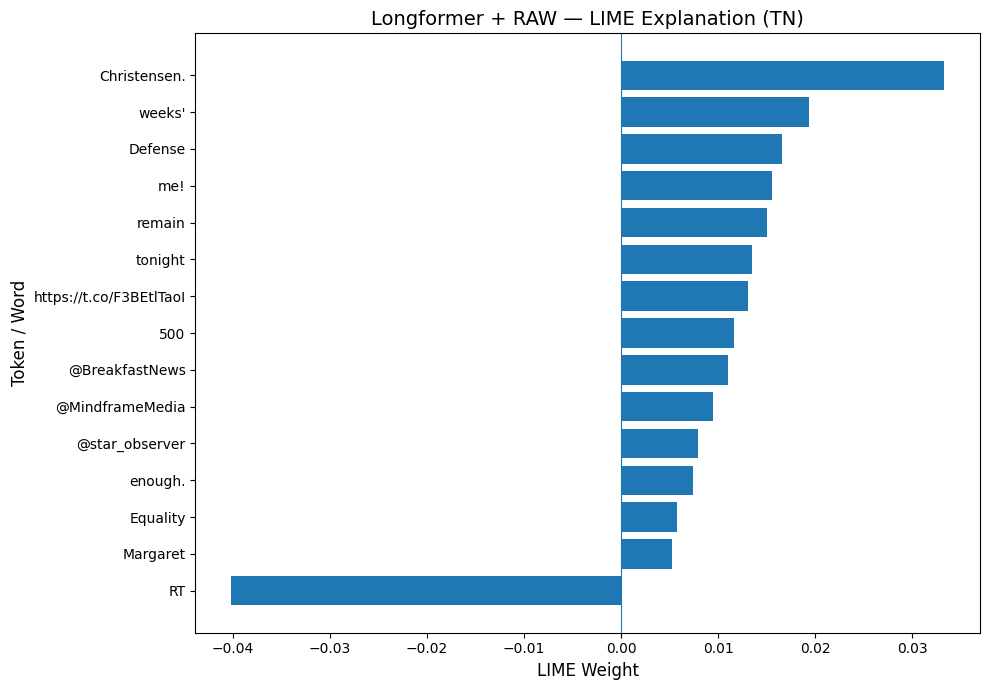

/tmp/ipykernel_58/653986235.py:671: UserWarning: Glyph 128128 (\N{SKULL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_58/653986235.py:671: UserWarning: Glyph 128054 (\N{DOG FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_58/653986235.py:671: UserWarning: Glyph 127794 (\N{EVERGREEN TREE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_58/653986235.py:671: UserWarning: Glyph 127754 (\N{WATER WAVE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_58/653986235.py:671: UserWarning: Glyph 128247 (\N{CAMERA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_58/653986235.py:680: UserWarning: Glyph 128128 (\N{SKULL}) missing from font(s) DejaVu Sans.
  plt.savefig(
/tmp/ipykernel_58/653986235.py:680: UserWarning: Glyph 128054 (\N{DOG FACE}) missing from font(s) DejaVu Sans.
  plt.savefig(
/tmp/ipykernel_58/653986235.py:680: UserWarning: Glyph 127794 (\N{EVERGREEN TREE}) missi

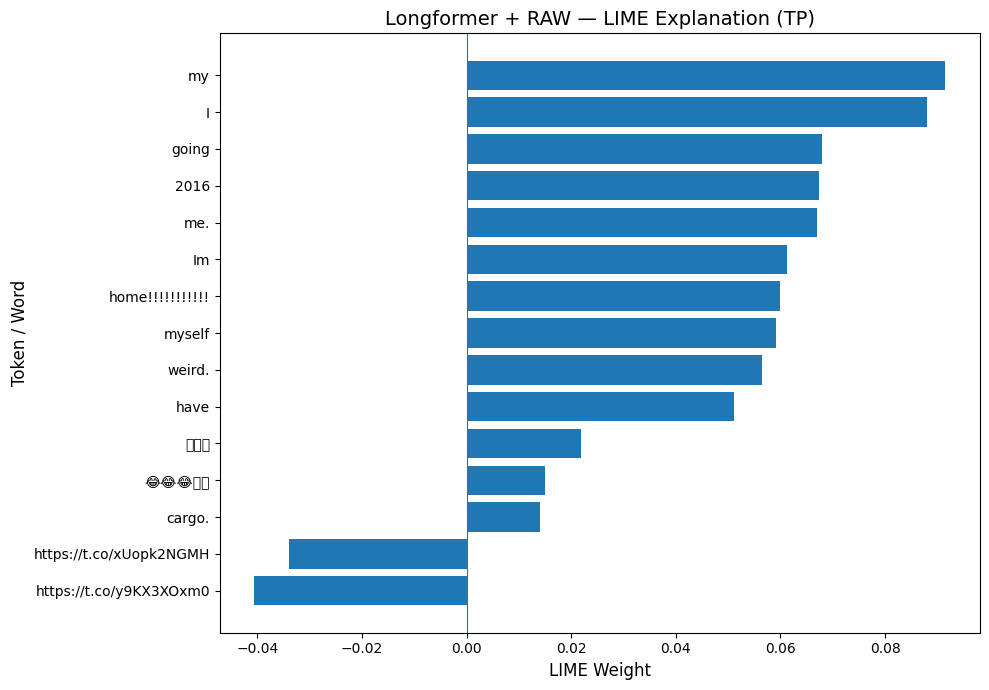

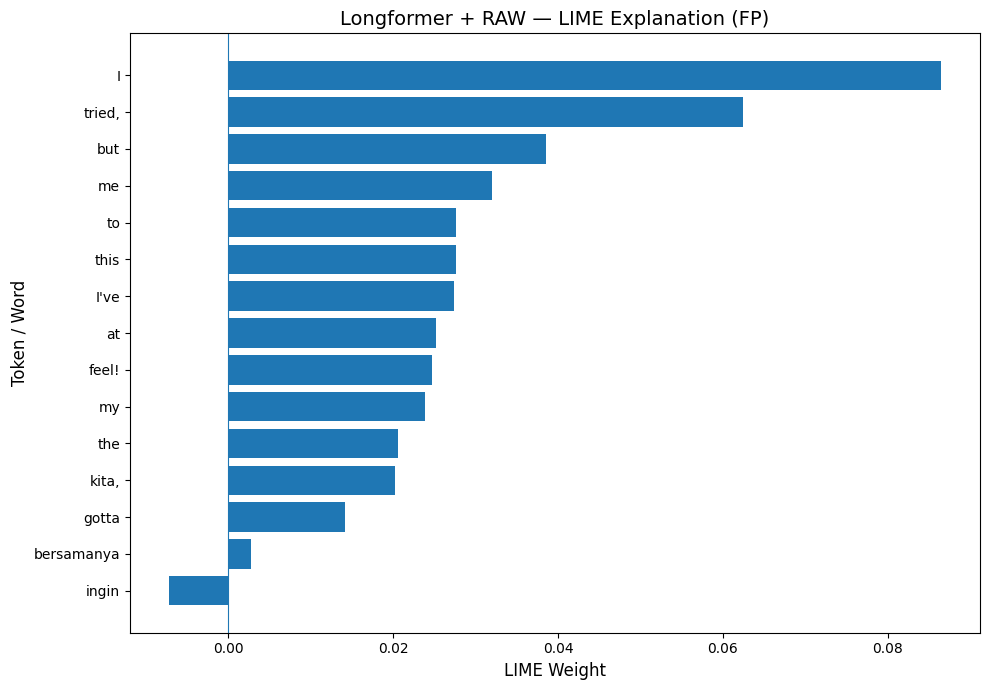

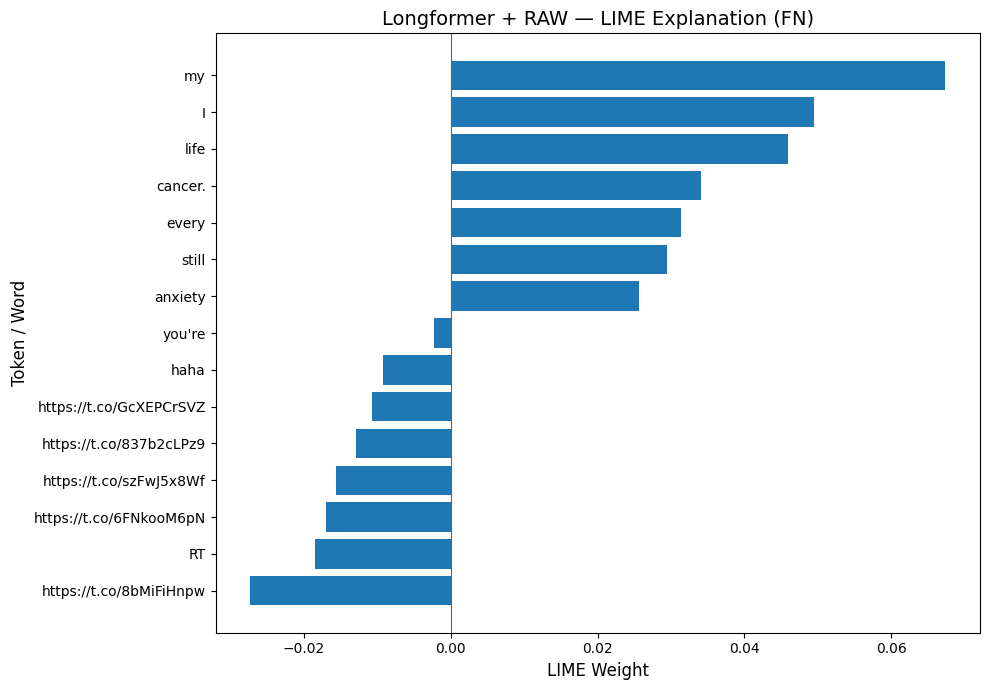


LIME ANALYSIS COMPLETE
✓ TP, TN, FP, FN cases explained
✓ Same trained Longformer model used
✓ Metadata held fixed per user
✓ 1000 LIME perturbations per case
✓ Top 15 features extracted
✓ LIME results saved
✓ HTML explanations saved
✓ Paper-ready LIME plots saved and displayed

LIME output directory: /kaggle/working/longformer_raw/explainability/lime


In [24]:
# ============================================================
# LIME EXPLAINER — LONGFORMER + RAW
# CORRECTED FOR INSTALLED LIME VERSION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from lime.lime_text import LimeTextExplainer
from IPython.display import display, HTML

print("=" * 70)
print("LIME ANALYSIS")
print("LONGFORMER + RAW")
print("=" * 70)

# ============================================================
# FIXED LIME SETTINGS
# ============================================================

LIME_SEED = 42
LIME_NUM_FEATURES = 15
LIME_NUM_SAMPLES = 1000
LIME_BATCH_SIZE = 16

np.random.seed(LIME_SEED)
torch.manual_seed(LIME_SEED)

# ============================================================
# OUTPUT DIRECTORY
# ============================================================

LIME_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "lime"
)

os.makedirs(
    LIME_DIR,
    exist_ok=True
)

# ============================================================
# MODEL
# ============================================================

model_longformer_raw.eval()

for parameter in model_longformer_raw.parameters():
    parameter.requires_grad = False

print()
print("✓ Longformer model loaded")
print("✓ Evaluation mode enabled")
print("✓ All model parameters remain frozen")

# ============================================================
# TOKENIZER
# ============================================================

try:

    tokenizer

    print(
        "✓ Existing Longformer tokenizer reused"
    )

except NameError:

    from transformers import AutoTokenizer

    try:

        tokenizer = AutoTokenizer.from_pretrained(
            MODEL_NAME,
            token=hf_token
        )

    except NameError:

        tokenizer = AutoTokenizer.from_pretrained(
            MODEL_NAME
        )

    print(
        "✓ Longformer tokenizer loaded"
    )

# ============================================================
# TEST PREDICTIONS
# ============================================================
# Required for the notebook's TP/TN/FP/FN reporting.

labels_np = []
preds_np = []
probs_np = []

print()
print("=" * 70)
print("GENERATING TEST PREDICTIONS")
print("=" * 70)

with torch.no_grad():

    for batch in test_longformer_raw_loader:

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)

        output = model_longformer_raw(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = output[
            "logits"
        ]

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predictions = torch.argmax(
            logits,
            dim=1
        )

        labels_np.extend(
            labels.cpu().numpy().tolist()
        )

        preds_np.extend(
            predictions.cpu().numpy().tolist()
        )

        probs_np.extend(
            probabilities[:, 1]
            .cpu()
            .numpy()
            .tolist()
        )

labels_np = np.asarray(
    labels_np,
    dtype=np.int64
)

preds_np = np.asarray(
    preds_np,
    dtype=np.int64
)

probs_np = np.asarray(
    probs_np,
    dtype=np.float32
)

assert len(labels_np) == len(
    test_longformer_raw_dataset
)

assert len(preds_np) == len(
    test_longformer_raw_dataset
)

assert len(probs_np) == len(
    test_longformer_raw_dataset
)

print(
    "Test users:",
    len(labels_np)
)

print(
    "✓ Test predictions generated"
)

# ============================================================
# FIXED REPRESENTATIVE TEST CASES
# ============================================================

selected_cases = {}

for test_index in range(
    len(labels_np)
):

    true_label = int(
        labels_np[test_index]
    )

    predicted_label = int(
        preds_np[test_index]
    )

    if (
        "TP" not in selected_cases
        and true_label == 1
        and predicted_label == 1
    ):

        selected_cases["TP"] = test_index

    elif (
        "TN" not in selected_cases
        and true_label == 0
        and predicted_label == 0
    ):

        selected_cases["TN"] = test_index

    elif (
        "FP" not in selected_cases
        and true_label == 0
        and predicted_label == 1
    ):

        selected_cases["FP"] = test_index

    elif (
        "FN" not in selected_cases
        and true_label == 1
        and predicted_label == 0
    ):

        selected_cases["FN"] = test_index

    if len(
        selected_cases
    ) == 4:

        break

assert set(
    selected_cases.keys()
) == {
    "TP",
    "TN",
    "FP",
    "FN"
}

print()
print("=" * 70)
print("FIXED REPRESENTATIVE TEST CASES")
print("=" * 70)

for case_name, test_index in selected_cases.items():

    print(
        f"{case_name}: "
        f"test index = {test_index}"
    )

# ============================================================
# TEXT FUNCTION
# ============================================================

# ============================================================
# LIME — TEST TEXT LOADER
# ============================================================

def get_test_text(
    test_index
):

    # --------------------------------------------------------
    # Reuse exact Longformer RAW dataframe
    # --------------------------------------------------------

    if "test_longformer_raw_df" in globals():

        text = test_longformer_raw_df.iloc[
            int(test_index)
        ]["model_text"]

        if pd.isna(text):

            return ""

        return str(text)

    # --------------------------------------------------------
    # Otherwise load the exact saved RAW-cleaned test dataframe
    # --------------------------------------------------------

    test_cleaned_path = os.path.join(
        RESULT_DIR,
        "test_cleaned.pkl"
    )

    assert os.path.exists(
        test_cleaned_path
    ), (
        "Saved RAW test dataframe not found: "
        f"{test_cleaned_path}"
    )

    test_cleaned_df = pd.read_pickle(
        test_cleaned_path
    )

    # EXACT notebook definition:
    # model_text = anchor_removed_text

    text = test_cleaned_df.iloc[
        int(test_index)
    ]["model_text"]

    if pd.isna(text):

        return ""

    return str(text)


# ============================================================
# LIME PREDICTOR
# ============================================================
# Metadata remains FIXED for the explained user.
# LIME perturbs only the text.

def make_lime_predictor(
    test_index
):

    fixed_metadata = (
        test_longformer_raw_dataset
        .metadata[
            int(test_index)
        ]
        .unsqueeze(0)
        .to(device)
    )

    def predictor(
        texts
    ):

        all_probabilities = []

        for start_idx in range(
            0,
            len(texts),
            LIME_BATCH_SIZE
        ):

            batch_texts = texts[
                start_idx:
                start_idx + LIME_BATCH_SIZE
            ]

            encoded = tokenizer(
                [
                    str(text)
                    for text in batch_texts
                ],
                max_length=MAX_LENGTH,
                truncation=True,
                padding="max_length",
                return_attention_mask=True,
                return_tensors="pt"
            )

            input_ids = (
                encoded["input_ids"]
                .to(device)
            )

            attention_mask = (
                encoded["attention_mask"]
                .to(device)
            )

            metadata = (
                fixed_metadata
                .expand(
                    len(batch_texts),
                    -1
                )
            )

            with torch.no_grad():

                output = model_longformer_raw(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    metadata=metadata
                )

                logits = output[
                    "logits"
                ]

                probabilities = torch.softmax(
                    logits,
                    dim=1
                )

            all_probabilities.append(
                probabilities
                .cpu()
                .numpy()
            )

        return np.concatenate(
            all_probabilities,
            axis=0
        )

    return predictor


# ============================================================
# LIME EXPLAINER
# ============================================================

explainer = LimeTextExplainer(
    class_names=[
        "Negative",
        "Positive"
    ],
    split_expression=r"\s+",
    random_state=LIME_SEED
)

# ============================================================
# RUN LIME FOR FOUR CASES
# ============================================================

all_explanations = {}

print()
print("=" * 70)
print("GENERATING LIME EXPLANATIONS")
print("=" * 70)

for case_name, test_index in selected_cases.items():

    print()
    print(
        f"Processing {case_name} "
        f"(test index {test_index})..."
    )

    text = get_test_text(
        test_index
    )

    predictor = make_lime_predictor(
        test_index
    )

    explanation = explainer.explain_instance(
        text,
        predictor,
        labels=(1,),
        num_features=LIME_NUM_FEATURES,
        num_samples=LIME_NUM_SAMPLES
    )

    all_explanations[
        case_name
    ] = explanation

    print(
        f"✓ {case_name} explanation complete"
    )

# ============================================================
# SAVE LIME RESULTS
# ============================================================

all_lime_rows = []

for case_name, explanation in all_explanations.items():

    explanation_list = explanation.as_list(
        label=1
    )

    for rank, (
        word,
        weight
    ) in enumerate(
        explanation_list,
        start=1
    ):

        all_lime_rows.append({

            "case":
                case_name,

            "test_index":
                selected_cases[case_name],

            "true_label":
                int(
                    labels_np[
                        selected_cases[case_name]
                    ]
                ),

            "predicted_label":
                int(
                    preds_np[
                        selected_cases[case_name]
                    ]
                ),

            "positive_probability":
                float(
                    probs_np[
                        selected_cases[case_name]
                    ]
                ),

            "rank":
                rank,

            "word":
                word,

            "lime_weight":
                float(weight)

        })

lime_results_df = pd.DataFrame(
    all_lime_rows
)

lime_csv_path = os.path.join(
    LIME_DIR,
    "longformer_raw_lime_results.csv"
)

lime_results_df.to_csv(
    lime_csv_path,
    index=False
)

# ============================================================
# DISPLAY + SAVE HTML
# ============================================================

print()
print("=" * 70)
print("LIME EXPLANATIONS")
print("=" * 70)

for case_name, explanation in all_explanations.items():

    print()
    print(
        "=" * 60
    )

    print(
        f"{case_name} — "
        f"LIME LOCAL EXPLANATION"
    )

    print(
        "=" * 60
    )

    # DISPLAY IN NOTEBOOK

    display(
        HTML(
            explanation.as_html(
                labels=[1]
            )
        )
    )

    # SAVE HTML

    html_path = os.path.join(
        LIME_DIR,
        f"longformer_raw_lime_{case_name}.html"
    )

    with open(
        html_path,
        "w",
        encoding="utf-8"
    ) as f:

        f.write(
            explanation.as_html(
                labels=[1]
            )
        )

# ============================================================
# PAPER-FRIENDLY LIME BAR PLOTS
# ============================================================

for case_name, explanation in all_explanations.items():

    explanation_list = explanation.as_list(
        label=1
    )

    plot_df = pd.DataFrame(
        explanation_list,
        columns=[
            "word",
            "weight"
        ]
    )

    plot_df = plot_df.sort_values(
        "weight"
    )

    plt.figure(
        figsize=(10, 7)
    )

    plt.barh(
        plot_df["word"],
        plot_df["weight"]
    )

    plt.axvline(
        0,
        linewidth=0.8
    )

    plt.xlabel(
        "LIME Weight",
        fontsize=12
    )

    plt.ylabel(
        "Token / Word",
        fontsize=12
    )

    plt.title(
        f"Longformer + RAW — "
        f"LIME Explanation ({case_name})",
        fontsize=14
    )

    plt.tight_layout()

    plot_path = os.path.join(
        LIME_DIR,
        f"longformer_raw_lime_{case_name}.png"
    )

    # SAVE

    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    # DISPLAY

    plt.show()

    plt.close()

# ============================================================
# SAVE CASE INFORMATION
# ============================================================

case_info_rows = []

for case_name, test_index in selected_cases.items():

    case_info_rows.append({

        "case":
            case_name,

        "test_index":
            int(test_index),

        "true_label":
            int(
                labels_np[test_index]
            ),

        "predicted_label":
            int(
                preds_np[test_index]
            ),

        "positive_probability":
            float(
                probs_np[test_index]
            ),

        "text_length_characters":
            len(
                get_test_text(test_index)
            )

    })

case_info_df = pd.DataFrame(
    case_info_rows
)

case_info_df.to_csv(
    os.path.join(
        LIME_DIR,
        "longformer_raw_lime_case_information.csv"
    ),
    index=False
)

# ============================================================
# SAVE CONFIGURATION
# ============================================================

lime_config = {

    "model":
        "Longformer",

    "cleaning":
        "RAW",

    "dataset":
        "Held-out test set",

    "target":
        "Positive/depression class",

    "representative_cases":
        [
            "TP",
            "TN",
            "FP",
            "FN"
        ],

    "case_selection":
        "First matching test example in fixed test order",

    "random_seed":
        LIME_SEED,

    "num_samples":
        LIME_NUM_SAMPLES,

    "num_features":
        LIME_NUM_FEATURES,

    "batch_size":
        LIME_BATCH_SIZE,

    "metadata":
        "Fixed for each explained user",

    "text_perturbation":
        "LIME word-level perturbations",

    "max_length":
        MAX_LENGTH,

    "model_training":
        "No additional training",

    "transformer":
        "Longformer",

    "transformer_weights":
        "Frozen"

}

with open(
    os.path.join(
        LIME_DIR,
        "longformer_raw_lime_config.json"
    ),
    "w"
) as f:

    json.dump(
        lime_config,
        f,
        indent=2
    )

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("LIME ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ TP, TN, FP, FN cases explained"
)

print(
    "✓ Same trained Longformer model used"
)

print(
    "✓ Metadata held fixed per user"
)

print(
    "✓ 1000 LIME perturbations per case"
)

print(
    "✓ Top 15 features extracted"
)

print(
    "✓ LIME results saved"
)

print(
    "✓ HTML explanations saved"
)

print(
    "✓ Paper-ready LIME plots saved and displayed"
)

print()
print(
    "LIME output directory:",
    LIME_DIR
)